# Process Window Scout (AM-PWS)

An agent that recommends **PBF-LB process windows** from the open-access literature and tells you which
published results to trust. Example request: *"316L, 200 W machine, 30 µm layers, density above 99.5 %"*.

This notebook is the whole project. It follows `docs/notebook-outline.md`: one logical step per Part, from the
engineer's request to an approved, cited window. Each Part opens with the question it answers, the course concept it
applies, the LangChain or LangGraph feature that implements it, and the evidence that it works. Test cells right
below each piece check it.

**How to run:** kernel *Python 3.13 (CMU Agents)*, then *Kernel > Restart & Run All*. Every test cell prints
`ok` lines and stops with an error if something breaks. Slow steps (paper downloads, model calls) save their results
in `data/` so a rerun is quick. Model answers are cached in `data/llm_cache.sqlite`, so a rerun replays them without
calling the endpoint (and works without the VPN).

| Part | Question | Status |
|---|---|---|
| 0 | Setup: settings, test helper, cache and trace for every model call | built |
| 1 | Which calculations must never be left to the model? (tools) | built |
| 2 | How do we talk to the model reliably? | built |
| 3 | Where does the knowledge come from? (retrieval) | built |
| 4 | Can one agent answer with tools? (single-agent baseline) | built |
| 5 | What exactly does each paper report? (Reader) | built |
| 6 | Which records can we trust? (Checker) | built |
| 7 | Why do comparable studies disagree? (Analyst, Tree of Thought) | planned |
| 8 | How do the agents work together? (multi-agent graph) | built, Analyst a stand-in |
| 9 | When must a human decide? (guardrails and memory) | built |
| 10 | Does it actually work? (evaluation) | scoring ready, answer key pending |
| 11 | End-to-end demo | planned |


## Part 0. Setup: settings, test helper, cache and trace

- **Question:** What does every later Part rely on, and how is every model call kept, replayed and traced?
- **Course concept:** the harness around an agent and observability (Module 4): every call recorded, nothing hidden
- **Framework feature:** `set_llm_cache` with a small SQLite backend, a LangChain callback handler for traces, and `ChatGLM`, a `ChatOpenAI` subclass that keeps GLM-5.2's reasoning
- **Evidence:** the cache and trace tests in 0.3, and the trace tables printed after every model step in later Parts (capability 33)

Paths and one small helper first. `check()` is my test function: it prints `ok` when a condition holds and raises
an error when it does not, so *Restart & Run All* stops at the first broken piece.


In [1]:
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import lambertw

# Project root = the repository folder (this notebook lives in notebooks/).
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
print("Project root:", ROOT)


def check(name, condition):
    # Tiny test helper: print ok, or stop the notebook with a clear message.
    assert condition, f"FAILED: {name}"
    print(f"  ok  {name}")

Project root: C:\Users\Chinmay.Phutela\Carnegie Capstone\process-window-scout


### 0.1 Settings and the endpoint

The agent's reasoning comes from **GLM-5.2**, an open-weight model served on a vLLM server with an OpenAI-compatible
API, so the standard `openai` Python client can talk to it.

- The model is **GLM-5.2** (set in the code, so anyone running the notebook uses the same model). The server address
  and key live in `.env`, which is never committed. Copy `.env.example` to `.env` and fill them in.
- `llm_available()` checks once whether the endpoint answers. Off the network every model cell replays its answer
  from the cache (0.3) or skips politely.
- **Thinking mode is on.** GLM-5.2 writes its reasoning first and its answer second. `ask_llm()` returns both, and
  every agent prints its reasoning at every step, because seeing *why* it chose something is how I debug it.
- Reasoning uses many tokens (in a test, 270 of 279 output tokens), so `max_tokens` is generous. Too small a limit
  returns an empty answer.

In [2]:
import os
import json
import time
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(ROOT / ".env")
LLM_MODEL = os.environ.get("LLM_MODEL") or "GLM-5.2"  # the model this project was built and tested with
llm = OpenAI(base_url=os.environ.get("LLM_BASE_URL"), api_key=os.environ.get("LLM_API_KEY") or "EMPTY",
             timeout=300, max_retries=1)


def llm_available() -> bool:
    # True when the endpoint answers. Off the office network it does not, and the LLM cells skip politely.
    try:
        llm.with_options(timeout=10, max_retries=0).models.list()
        return True
    except Exception as e:
        print(f"LLM endpoint not reachable ({type(e).__name__}). LLM cells will be skipped.")
        return False


def ask_llm(messages, max_tokens=6000, show_reasoning=True):
    """Send a chat to GLM-5.2 with thinking on. Returns (reasoning, answer)."""
    t0 = time.time()
    r = llm.chat.completions.create(model=LLM_MODEL, messages=messages, max_tokens=max_tokens)
    msg = r.choices[0].message
    extra = msg.model_extra or {}
    reasoning = getattr(msg, "reasoning", None) or extra.get("reasoning") or extra.get("reasoning_content") or ""
    answer = msg.content or ""
    if not answer and r.choices[0].finish_reason == "length":
        print(f"WARNING: no answer, the model used all {max_tokens} tokens on reasoning. Raise max_tokens.")
    if show_reasoning and reasoning:
        print(f"--- reasoning ({len(reasoning.split())} words) ---\n{reasoning}\n")
    print(f"[{time.time() - t0:.0f} s, {r.usage.completion_tokens} output tokens]")
    return reasoning, answer


LLM_OK = llm_available()
print("Model:", LLM_MODEL or "(not set)", "| reachable:", LLM_OK)

Model: GLM-5.2 | reachable: True


### 0.2 GLM-5.2 through LangChain

The plain `openai` client of 0.1 talks to GLM-5.2 directly. From here on the agents are built with LangChain
and LangGraph (structured output, tool calling, a ready-made agent loop, graphs), and those expect a **LangChain chat
model**. `ChatOpenAI` from `langchain-openai` is the standard class for any server with an OpenAI-compatible API,
so in principle it works with our vLLM server unchanged.

**What I checked first (a short spike on 7 November).** Four questions, answered with real calls in 2.2:

| Question | Answer |
|---|---|
| (a) Does GLM's reasoning survive `ChatOpenAI`? | **No.** vLLM returns it in a field called `reasoning`, which is not part of OpenAI's API, and `ChatOpenAI` drops such fields on purpose (its documentation says so). The reasoning token count survives, the text does not. Fix: the small subclass below. |
| (b) Does `with_structured_output` work with thinking on? | **Yes**, all three methods gave correct records on two test passages. I use `json_schema` (reasons in 2.2). |
| (c) Does `bind_tools` give proper tool calls? | **Yes**, with clean arguments. LangChain's ready-made agent loop `create_agent` also completes a tool round. |
| (d) Time and tokens per call? | A few seconds per call. Reasoning is most of the output tokens (table in 2.2). |

`ChatGLM` is `ChatOpenAI` with three small overrides. Each is a method LangChain calls internally:

1. `_create_chat_result` turns the server's response into a LangChain message. The override copies GLM's `reasoning`
   into `message.additional_kwargs["reasoning_content"]`, the key LangChain uses for reasoning from other providers
   (DeepSeek, Ollama). It also stores a structured answer as a plain dictionary, so it can be cached.
2. `_generate` makes the actual call. The override times it and stores the seconds with the answer, so a cached
   replay still knows what the real call cost. When the endpoint is unreachable it raises `ModelUnavailable` at once
   instead of waiting for a network timeout.
3. `_get_llm_string` describes the model for the cache key (0.3). LangChain's default includes the server address,
   which must never be saved, and names an output schema only by its class name, so editing a schema's fields would
   silently replay an old answer. The override uses the model name and call settings, with the full schema.

Streaming is switched off (`disable_streaming=True`), so every call takes the same path through these methods.
`reasoning_of(message)` is the one place the notebook reads the reasoning from. (LangChain's `content_blocks` view
does not show it, because the OpenAI translator behind it only knows OpenAI's own fields.)

In [3]:
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI


class ModelUnavailable(RuntimeError):
    """The answer is not in the cache and the GLM endpoint cannot be reached."""


class ChatGLM(ChatOpenAI):
    """ChatOpenAI for GLM-5.2 on vLLM: keeps the reasoning, times each call, cache key without the server address."""

    offline: bool = False              # True when the endpoint is unreachable: only cached answers are possible
    disable_streaming: bool = True     # one code path for every call (streaming would bypass _generate)

    def _create_chat_result(self, response, generation_info=None):
        result = super()._create_chat_result(response, generation_info)
        choices = response["choices"] if isinstance(response, dict) else response.choices
        for gen, choice in zip(result.generations, choices):
            msg = choice["message"] if isinstance(choice, dict) else choice.message
            fields = msg if isinstance(msg, dict) else (msg.model_extra or {})
            reasoning = fields.get("reasoning") or fields.get("reasoning_content")
            if reasoning:
                gen.message.additional_kwargs["reasoning_content"] = reasoning
            parsed = gen.message.additional_kwargs.get("parsed")
            if isinstance(parsed, BaseModel):           # structured output: a plain dict can be cached
                gen.message.additional_kwargs["parsed"] = parsed.model_dump()
        return result

    def _generate(self, messages, stop=None, run_manager=None, **kwargs):
        # LangChain checks the cache first, so this only runs on a cache miss.
        if self.offline:
            raise ModelUnavailable("this answer is not in the cache and the GLM endpoint is not reachable")
        t0 = time.time()
        result = super()._generate(messages, stop=stop, run_manager=run_manager, **kwargs)
        for gen in result.generations:
            gen.generation_info = {**(gen.generation_info or {}), "seconds": round(time.time() - t0, 2)}
        return result

    def _get_llm_string(self, stop=None, **kwargs) -> str:
        # The model half of the cache key (the messages are the other half). Bound tools and output schemas are in kwargs.
        def plain(x):
            return x.model_json_schema() if isinstance(x, type) and issubclass(x, BaseModel) else str(x)
        settings = {"model": self.model_name, "temperature": self.temperature, "max_tokens": self.max_tokens,
                    "extra_body": self.extra_body, "stop": stop, **kwargs}
        return json.dumps(settings, sort_keys=True, default=plain)


def reasoning_of(message) -> str:
    """GLM's reasoning for one answer ('' if there is none)."""
    return message.additional_kwargs.get("reasoning_content", "")

### 0.3 Cache and trace for every model call

Every model call from here on (agents included) goes through one mechanism with two parts. Both are standard
LangChain hooks, so they also work inside `with_structured_output`, `create_agent` and LangGraph nodes without
any extra code there.

**Cache: `set_llm_cache`.** Before a chat model calls the server, LangChain asks the global cache for an answer
saved under the same key: the messages plus the model settings (`_get_llm_string` above). On a hit it returns the
saved answer and makes no call. The key ignores bookkeeping such as token counts (`messages_key`), because LangChain
changes those on a replay and a multi-step conversation would otherwise not find its second step. The backend is a
small SQLite table, `SQLiteLLMCache` (`data/llm_cache.sqlite`). I
wrote it on LangChain's `BaseCache` interface (three methods: `lookup`, `update`, `clear`) instead of using the
ready-made `SQLiteCache`, because that one lives in `langchain-community`, which is being retired and prints a
deprecation warning. The answer is stored as a readable JSON message, reasoning, token counts and call time included.
One practical lesson: the backend keeps a single SQLite connection open. Opening the file anew for every call
failed about one time in fifteen on this Windows laptop, because something (most likely the virus scanner) holds
the file for a moment and SQLite then opens it read-only.

**Trace: a callback handler.** LangChain calls a handler's `on_chat_model_start` before every model call and
`on_llm_end` after it, also when the answer came from the cache. `TraceRecorder` uses these two hooks to write one
JSON line per call to `data/traces/<run>.jsonl`: which agent or graph node called, the prompt, the reasoning, the
answer or tool calls, token counts, the seconds the real call took, and whether it was replayed from the cache. It
also prints the reasoning at every step (shortened on screen, complete in the file). The agent name comes from the
call's metadata, for example `config={"metadata": {"agent": "reader"}}`, and inside a LangGraph graph from the node
name automatically.

**Why this matters**
- *Reproducibility:* Restart & Run All replays the same answers, so the results in this notebook do not change
  from run to run, and it runs without the VPN.
- *Cost:* a call that has been made once is never paid for again, in time or tokens.
- *Traceability:* a grader (or I) can open the trace and see, for any number in a result, which prompt produced it
  and what the model was thinking. The token and time columns feed the evaluation in Part 10 (calls, run time).

Secrets stay out: the cache key never contains the server address, and `redact()` removes the address and key from
any error text before it is printed or saved. To force fresh answers, delete `data/llm_cache.sqlite`.

In [4]:
import hashlib
import sqlite3
import threading
from datetime import datetime
from urllib.parse import urlparse

from langchain_core.caches import BaseCache
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.globals import set_llm_cache
from langchain_core.messages import message_to_dict, messages_from_dict
from langchain_core.outputs import ChatGeneration

TRACES = DATA / "traces"
TRACES.mkdir(exist_ok=True)


def messages_key(prompt: str) -> str:
    """The part of a conversation that decides the answer: each message's type, text and tool calls.

    LangChain hands the cache the full messages, bookkeeping included. On a replay it sets the answer's cost to zero,
    so in a tool loop the next step's messages differ from the first run and would never be found again. Leaving the
    bookkeeping (token counts, ids, costs) out of the key avoids that.
    """
    try:
        return json.dumps([[m["id"][-1], m["kwargs"].get("content"), m["kwargs"].get("tool_calls"),
                            m["kwargs"].get("tool_call_id")] for m in json.loads(prompt)], sort_keys=True, ensure_ascii=False)
    except (ValueError, KeyError, TypeError):
        return prompt


class SQLiteLLMCache(BaseCache):
    """LangChain cache backend: one SQLite row per (messages, model settings) holding the model's whole answer."""

    def __init__(self, path):
        self.path = str(path)
        # One connection for the whole session: reopening the file for every call failed now and then on this
        # Windows laptop ("attempt to write a readonly database"), a connection that stays open never did.
        self._db = sqlite3.connect(self.path, timeout=30, check_same_thread=False)
        self._lock = threading.Lock()                     # parallel Readers may write at the same moment
        self._sql("CREATE TABLE IF NOT EXISTS answers (key TEXT PRIMARY KEY, settings TEXT, messages TEXT, answer TEXT, saved TEXT)")

    def _sql(self, query, args=()):
        with self._lock, self._db:                        # one statement at a time, committed at once
            return self._db.execute(query, args).fetchall()

    @staticmethod
    def key(prompt: str, llm_string: str) -> str:
        return hashlib.sha256(f"{llm_string}\n{messages_key(prompt)}".encode()).hexdigest()

    def lookup(self, prompt, llm_string):
        rows = self._sql("SELECT answer FROM answers WHERE key = ?", (self.key(prompt, llm_string),))
        if not rows:
            return None                                     # a miss: LangChain will call the model
        return [ChatGeneration(message=messages_from_dict([g["message"]])[0],             # the answer exactly as saved
                               generation_info={**(g["info"] or {}), "from_cache": True})   # seen by the trace handler
                for g in json.loads(rows[0][0])]

    def update(self, prompt, llm_string, return_val):
        answer = json.dumps([{"message": message_to_dict(g.message), "info": g.generation_info} for g in return_val],
                            ensure_ascii=False)
        self._sql("INSERT OR REPLACE INTO answers VALUES (?, ?, ?, ?, ?)",
                  (self.key(prompt, llm_string), llm_string, prompt, answer, datetime.now().isoformat(timespec="seconds")))

    def clear(self, **kwargs):
        self._sql("DELETE FROM answers")

    def size(self) -> int:
        return self._sql("SELECT COUNT(*) FROM answers")[0][0]

    def close(self):
        self._db.close()


def redact(text: str) -> str:
    """Remove the server address, its host name and the key from a text before it is printed or saved."""
    base = os.environ.get("LLM_BASE_URL") or ""
    for secret in (base, urlparse(base).hostname, os.environ.get("LLM_API_KEY")):
        if secret:
            text = text.replace(secret, "<hidden>")
    return text


class TraceRecorder(BaseCallbackHandler):
    """Callback handler: one JSON line per model call in data/traces/<run>.jsonl, and the reasoning printed."""

    def __init__(self, folder, print_chars: int = 1500):
        self.folder, self.print_chars = Path(folder), print_chars
        self.run, self.path, self._file = None, None, None
        self._pending, self._lock = {}, threading.Lock()

    def start(self, run: str) -> Path:
        """Begin the trace of a new run. A trace file with the same name is replaced."""
        self.stop()
        with self._lock:
            self.run, self.path = run, self.folder / f"{run}.jsonl"
            # Kept open for the whole run: like the cache (0.3), reopening it for every call failed now and then here.
            self._file = self.path.open("w", encoding="utf-8")
        return self.path

    def stop(self):
        """Close the current trace file (a new start() or the next call opens one again)."""
        with self._lock:
            if self._file:
                self._file.close()
            self._file = None

    def on_chat_model_start(self, serialized, messages, *, run_id, metadata=None, invocation_params=None, **kwargs):
        meta, params = metadata or {}, invocation_params or {}
        self._pending[run_id] = {
            "agent": meta.get("agent") or meta.get("langgraph_node") or "notebook",
            "prompt": [{"role": m.type, "content": m.content,
                        **({"tool_calls": m.tool_calls} if getattr(m, "tool_calls", None) else {})} for m in messages[0]],
            "tools_offered": [t.get("function", t).get("name") for t in params.get("tools") or []],
        }

    def on_llm_end(self, response, *, run_id, **kwargs):
        start = self._pending.pop(run_id, {})
        gen = response.generations[0][0]
        msg, info, usage = gen.message, gen.generation_info or {}, gen.message.usage_metadata or {}
        rec = {"time": datetime.now().isoformat(timespec="seconds"), "run": self.run,
               "agent": start.get("agent", "notebook"), "model": msg.response_metadata.get("model_name"),
               "cached": bool(info.get("from_cache")), "seconds": info.get("seconds"),
               "input_tokens": usage.get("input_tokens"), "output_tokens": usage.get("output_tokens"),
               "reasoning_tokens": (usage.get("output_token_details") or {}).get("reasoning"),
               "tools_offered": start.get("tools_offered", []), "prompt": start.get("prompt"),
               "reasoning": reasoning_of(msg), "answer": msg.content,
               "tool_calls": [{"name": c["name"], "args": c["args"]} for c in msg.tool_calls]}
        self._write(rec)
        self._print(rec)

    def on_llm_error(self, error, *, run_id, **kwargs):
        start = self._pending.pop(run_id, {})
        self._write({"time": datetime.now().isoformat(timespec="seconds"), "run": self.run,
                     "agent": start.get("agent", "notebook"), "prompt": start.get("prompt"),
                     "error": redact(f"{type(error).__name__}: {error}")})

    def _write(self, rec):
        if self._file is None:
            self.start(self.run or "notebook")
        with self._lock:
            self._file.write(json.dumps(rec, ensure_ascii=False, default=str) + "\n")
            self._file.flush()                        # on disk at once, so load_trace sees every call

    def _print(self, rec):
        source = "from cache" if rec["cached"] else "model call"
        text = rec["reasoning"]
        more = f" [... {len(text) - self.print_chars} more characters in {self.path.name}]" if len(text) > self.print_chars else ""
        lines = [f"--- [{rec['agent']}] {source}: {rec['seconds']} s, {rec['input_tokens']} in / {rec['output_tokens']} out "
                 f"tokens ({rec['reasoning_tokens']} reasoning) ---",
                 f"reasoning ({len(text.split())} words): {text[:self.print_chars]}{more}"]
        lines += [f"tool call: {c['name']}({c['args']})" for c in rec["tool_calls"]]
        with self._lock:                  # calls running in parallel (batch, Send) print one whole block at a time
            print("\n".join(lines))


LLM_CACHE = SQLiteLLMCache(DATA / "llm_cache.sqlite")
set_llm_cache(LLM_CACHE)        # every LangChain chat model in this kernel now checks this cache first
TRACER = TraceRecorder(TRACES)

GLM_SETTINGS = dict(model=LLM_MODEL, base_url=os.environ.get("LLM_BASE_URL"), api_key=os.environ.get("LLM_API_KEY") or "EMPTY",
                    max_tokens=20000, timeout=600, max_retries=1, offline=not LLM_OK, callbacks=[TRACER])
glm = ChatGLM(**GLM_SETTINGS)          # agents with other needs start from GLM_SETTINGS (the Reader in Part 5)
print(f"Model {glm.model_name} | endpoint reachable: {LLM_OK} | answers in the cache: {LLM_CACHE.size()}")

Model GLM-5.2 | endpoint reachable: True | answers in the cache: 41


**The trace viewer.** `show_trace(run)` prints one line per model call with totals. `show_trace(run, call=n)` prints
everything about call `n`: the prompt, the full reasoning and the answer. `print_rows` is a small helper that prints
any list of dictionaries as a fixed-width table (later Parts reuse it).

In [5]:
def print_rows(rows, columns):
    """Print a list of dicts as a fixed-width table. columns = [(key, header, width), ...]."""
    def cell(v, w):
        s = "" if v is None else (f"{v:g}" if isinstance(v, float) else str(v))
        s = s.replace("\n", " ")
        return (s if len(s) <= w else s[: w - 3] + "...").ljust(w)
    print("  ".join(h.ljust(w) for _, h, w in columns))
    print("  ".join("-" * w for _, _, w in columns))
    for r in rows:
        print("  ".join(cell(r.get(k), w) for k, _, w in columns))


def load_trace(run: str) -> list[dict]:
    """All model calls of one run, read back from data/traces/<run>.jsonl."""
    path = TRACES / f"{run}.jsonl"
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def show_trace(run: str, call: int | None = None, chars: int = 600):
    """Trace viewer: a table of all calls in a run, or the prompt, reasoning and answer of one call."""
    recs = load_trace(run)
    if call is None:
        rows = [{"n": i, "agent": r["agent"], "src": "error" if "error" in r else "cache" if r["cached"] else "model",
                 "s": r.get("seconds"), "in": r.get("input_tokens"), "out": r.get("output_tokens"),
                 "reas": r.get("reasoning_tokens"),
                 "result": r.get("error") or "; ".join(f"{c['name']}({c['args']})" for c in r.get("tool_calls", []))
                           or r.get("answer")} for i, r in enumerate(recs, 1)]
        print(f"Trace '{run}': {len(recs)} model calls")
        print_rows(rows, [("n", "#", 3), ("agent", "agent / node", 22), ("src", "source", 6), ("s", "s", 6),
                          ("in", "tok in", 6), ("out", "tok out", 7), ("reas", "reason", 6), ("result", "answer or tool call", 60)])
        ok = [r for r in recs if "error" not in r]
        print(f"Total: {sum(r['seconds'] or 0 for r in ok):.1f} s of model time, "
              f"{sum(r['output_tokens'] or 0 for r in ok)} output tokens ({sum(r['reasoning_tokens'] or 0 for r in ok)} reasoning), "
              f"{sum(r['cached'] for r in ok)} of {len(ok)} answers replayed from the cache")
        return
    r = recs[call - 1]
    print(f"Call {call} of '{run}' by {r['agent']}")
    for m in r.get("prompt") or []:
        text = m["content"] if isinstance(m["content"], str) else json.dumps(m["content"], ensure_ascii=False)
        print(f"  [{m['role']}] {text[:chars]}{' ...' if len(text) > chars else ''}")
    print("\nREASONING:\n" + r.get("reasoning", ""))
    print("\nANSWER:\n" + (r.get("answer") or "(none)"))
    for c in r.get("tool_calls", []):
        print(f"TOOL CALL: {c['name']}({c['args']})")

In [6]:
# Tests for 0.2 and 0.3 (no endpoint needed)
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage

# The cache backend keeps the reasoning, the call time and the token counts.
_test_cache = SQLiteLLMCache(DATA / "cache_selftest.sqlite")
_test_cache.update("messages", "settings", [ChatGeneration(
    message=AIMessage("answer", additional_kwargs={"reasoning_content": "because"},
                      usage_metadata={"input_tokens": 5, "output_tokens": 9, "total_tokens": 14}),
    generation_info={"seconds": 2.5})])
_hit = _test_cache.lookup("messages", "settings")
check("a saved answer comes back with its reasoning", reasoning_of(_hit[0].message) == "because")
check("it remembers the real call time and is marked as replayed",
      _hit[0].generation_info["seconds"] == 2.5 and _hit[0].generation_info["from_cache"])
check("token counts survive the round trip", _hit[0].message.usage_metadata["output_tokens"] == 9)
check("different settings are a miss", _test_cache.lookup("messages", "other settings") is None)

# A replayed step of a conversation must find the next step: bookkeeping differences do not change the key.
from langchain_core.load import dumps
_ask = [HumanMessage("energy density at 200 W?")]
_fresh = AIMessage("", tool_calls=[{"name": "energy_density", "args": {"power_W": 200}, "id": "call-1"}],
                   usage_metadata={"input_tokens": 5, "output_tokens": 9, "total_tokens": 14})
_replayed = _fresh.model_copy(update={"usage_metadata": {**_fresh.usage_metadata, "total_cost": 0}, "id": "other"})
_tool = ToolMessage("E_v = 83.3 J/mm³", tool_call_id="call-1")
check("a replayed tool step gives the same key for the next call",
      SQLiteLLMCache.key(dumps(_ask + [_fresh, _tool]), "s") == SQLiteLLMCache.key(dumps(_ask + [_replayed, _tool]), "s"))
check("a different tool result gives a different key",
      SQLiteLLMCache.key(dumps(_ask + [_fresh, _tool]), "s")
      != SQLiteLLMCache.key(dumps(_ask + [_fresh, ToolMessage("E_v = 90 J/mm³", tool_call_id="call-1")]), "s"))
_test_cache.close()
Path(_test_cache.path).unlink()

# The cache key: model and settings, never the server address. An output schema enters with its fields.
class _Probe(BaseModel):
    density_pct: float
key_plain, key_schema = glm._get_llm_string(), glm._get_llm_string(response_format=_Probe)
check("the cache key names the model", LLM_MODEL in key_plain)
check("the cache key has no server address", not (os.environ.get("LLM_BASE_URL") or "<none>") in key_plain + key_schema)
check("an output schema is in the key with its fields", "density_pct" in key_schema and key_schema != key_plain)

# The trace handler writes one line per call, with the reasoning and the agent name from the metadata.
TRACER.start("selftest")
fake = GenericFakeChatModel(messages=iter([AIMessage("ok", additional_kwargs={"reasoning_content": "test reasoning"})]),
                            cache=False, callbacks=[TRACER])
fake.invoke("hello", config={"metadata": {"agent": "tester"}})
_t = load_trace("selftest")
check("one trace line per model call", len(_t) == 1)
check("the trace holds agent, prompt, reasoning and answer",
      _t[0]["agent"] == "tester" and _t[0]["prompt"][0]["content"] == "hello"
      and _t[0]["reasoning"] == "test reasoning" and _t[0]["answer"] == "ok")
TRACER.stop()
(TRACES / "selftest.jsonl").unlink()

# Offline, a cache miss stops at once with a clear error instead of a network timeout.
try:
    ChatGLM(model=LLM_MODEL, api_key="none", offline=True, cache=False).invoke("hello")
    offline_error = None
except ModelUnavailable as e:
    offline_error = e
check("offline and not cached raises ModelUnavailable", isinstance(offline_error, ModelUnavailable))
check("redact() hides the server address", os.environ.get("LLM_BASE_URL") is None
      or redact(f"failed: {os.environ['LLM_BASE_URL']}/chat") == "failed: <hidden>/chat")

  ok  a saved answer comes back with its reasoning
  ok  it remembers the real call time and is marked as replayed
  ok  token counts survive the round trip
  ok  different settings are a miss
  ok  a replayed tool step gives the same key for the next call
  ok  a different tool result gives a different key
  ok  the cache key names the model
  ok  the cache key has no server address
  ok  an output schema is in the key with its fields
--- [tester] model call: None s, None in / None out tokens (None reasoning) ---
reasoning (2 words): test reasoning
  ok  one trace line per model call
  ok  the trace holds agent, prompt, reasoning and answer
  ok  offline and not cached raises ModelUnavailable
  ok  redact() hides the server address


## Part 1. Which calculations must never be left to the model? (tools)

- **Question:** Which numbers must come from code, and how does an agent ask for them?
- **Course concept:** tool use, and why language models are weak at arithmetic (Modules 1 and 2)
- **Framework feature:** plain Python functions with typed, unit-named arguments and docstrings, wrapped as LangChain `@tool`s in 1.4
- **Evidence:** the tests under each tool, the depth band plot, and the tool schemas the model sees (capability 9)

**Why tools first.** The agent will read numbers from papers and compare them. Language models are poor at
arithmetic (Module 1: numbers are split into tokens, and the model pattern-matches rather than calculates), so
the rule for this project is: *the model never does arithmetic*. Every number it reasons about comes from a
paper or from one of these plain Python functions.

Each tool follows the same contract (from Lab 2.2):
- typed inputs with the unit in the argument name (`power_W`, `scan_speed_mm_s`).
- a docstring that says what the tool does, when to use it, its inputs with units and an example. In
  Part 4 the agent framework reads the name, type hints and docstring to describe the tool to the model,
  so this text decides whether the model picks the right tool.
- it returns a dictionary: numbers for my code, plus a `summary` sentence that restates the inputs, units and
  result, which is what the agent will read.
- invalid input raises `ValueError` with a readable message. In Part 4 the agent loop turns that message
  into an observation, so the model can correct itself instead of crashing.
- values that are legal but unusual for PBF-LB produce a warning in the summary. A scan speed of 0.8 "mm/s" is
  almost certainly 0.8 m/s, and I want that caught before it spoils a comparison.

The tools are tested here without any model. Only once they pass does an agent get to use them.

### 1.1 Unit conversion

Papers report scan speed in mm/s, m/s or even mm/min, and layer thickness in µm or mm. Before two papers can be
compared, everything goes to one set of units: **W, mm/s, µm**. The table maps each unit to its dimension and a
factor to SI, so a conversion is `value * factor_from / factor_to`. Asking for W to mm is refused rather than
silently producing nonsense.

In [7]:
# unit -> (dimension, factor to SI)
UNITS = {
    "W": ("power", 1.0), "kW": ("power", 1e3),
    "mm/s": ("speed", 1e-3), "m/s": ("speed", 1.0),
    "mm/min": ("speed", 1e-3 / 60), "m/min": ("speed", 1 / 60),
    "um": ("length", 1e-6), "µm": ("length", 1e-6), "μm": ("length", 1e-6),  # micro sign and Greek mu
    "mm": ("length", 1e-3), "m": ("length", 1.0),
    "J/mm3": ("energy density", 1e9), "J/m3": ("energy density", 1.0),
}


def convert_units(value: float, from_unit: str, to_unit: str) -> dict:
    """Convert a power, speed, length or energy density value from one unit to another.

    Use this whenever a paper reports a value in a different unit from the one needed for a comparison
    (project units are W, mm/s and µm). Do not convert units yourself.

    Args:
        value: the number to convert.
        from_unit: unit of the value, one of W, kW, mm/s, m/s, mm/min, m/min, um, µm, mm, m, J/mm3, J/m3.
        to_unit: unit wanted, same list; must measure the same quantity as from_unit.

    Example: convert_units(0.8, "m/s", "mm/s") gives 800 mm/s.
    Returns a dict with "value", "unit" and a "summary" sentence.
    """
    for u in (from_unit, to_unit):
        if u not in UNITS:
            raise ValueError(f"Unknown unit '{u}'. Known units: {', '.join(UNITS)}.")
    dim_from, f_from = UNITS[from_unit]
    dim_to, f_to = UNITS[to_unit]
    if dim_from != dim_to:
        raise ValueError(f"Cannot convert {dim_from} ({from_unit}) to {dim_to} ({to_unit}).")
    result = value * f_from / f_to
    return {
        "value": result,
        "unit": to_unit,
        "summary": f"{value:g} {from_unit} = {result:.6g} {to_unit} ({dim_from}).",
    }


print(convert_units(0.8, "m/s", "mm/s")["summary"])
print(convert_units(0.03, "mm", "µm")["summary"])

0.8 m/s = 800 mm/s (speed).
0.03 mm = 30 µm (length).


In [8]:
# Tests for convert_units
check("0.8 m/s is 800 mm/s", math.isclose(convert_units(0.8, "m/s", "mm/s")["value"], 800))
check("48 m/min is 800 mm/s", math.isclose(convert_units(48, "m/min", "mm/s")["value"], 800))
check("0.03 mm is 30 µm", math.isclose(convert_units(0.03, "mm", "µm")["value"], 30))
check("micro sign and Greek mu agree", convert_units(1, "mm", "µm")["value"] == convert_units(1, "mm", "μm")["value"])
check("0.4 kW is 400 W", math.isclose(convert_units(0.4, "kW", "W")["value"], 400))

for bad in [(1, "W", "mm"), (1, "furlong", "m")]:
    try:
        convert_units(*bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"{bad} raises: {e}", True)

  ok  0.8 m/s is 800 mm/s
  ok  48 m/min is 800 mm/s
  ok  0.03 mm is 30 µm
  ok  micro sign and Greek mu agree
  ok  0.4 kW is 400 W
  ok  (1, 'W', 'mm') raises: Cannot convert power (W) to length (mm).
  ok  (1, 'furlong', 'm') raises: Unknown unit 'furlong'. Known units: W, kW, mm/s, m/s, mm/min, m/min, um, µm, μm, mm, m, J/mm3, J/m3.


### 1.2 Energy density

Volumetric energy density is the number most papers use to summarise a parameter set:

$$E_v = \frac{P}{v \, h \, t} \quad [\mathrm{J/mm^3}]$$

with laser power $P$ (W), scan speed $v$ (mm/s), hatch spacing $h$ (mm) and layer thickness $t$ (mm). The tool
also reports linear energy density $P/v$ (J/mm).

$E_v$ is a coarse metric: two parameter sets with the same $E_v$ can give very different melt pools and
densities (Bertoli et al., 2017). The agent may use it to group papers, never to judge a result on its own,
and the summary says so.

The helper `_range_warnings` holds what I consider typical PBF-LB ranges. Values outside them are allowed but
flagged, mainly to catch unit mistakes.

In [9]:
# Typical PBF-LB ranges: outside these is legal but suspicious (often a unit mistake).
TYPICAL = {
    "power_W": (20, 1000),
    "scan_speed_mm_s": (50, 5000),
    "hatch_um": (20, 300),
    "layer_um": (10, 150),
}


def _validate(**inputs) -> list[str]:
    # Raise on non-positive values; return warnings for values outside typical PBF-LB ranges.
    warnings = []
    for name, value in inputs.items():
        if value is None or not value > 0:
            raise ValueError(f"{name} must be a positive number, got {value!r}.")
        lo, hi = TYPICAL[name]
        if not lo <= value <= hi:
            warnings.append(f"{name} = {value:g} is outside the typical PBF-LB range {lo:g} to {hi:g}; check the units.")
    return warnings


def energy_density(power_W: float, scan_speed_mm_s: float, hatch_um: float, layer_um: float) -> dict:
    """Volumetric energy density E_v = P/(v*h*t) in J/mm³ and linear energy density P/v in J/mm.

    Use this when a paper gives laser power, scan speed, hatch spacing and layer thickness and you need
    its energy density, for example to group papers. E_v is a coarse metric: never judge a result on
    E_v alone.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s (convert m/s first).
        hatch_um: hatch spacing in µm.
        layer_um: layer thickness in µm.

    Example: energy_density(200, 800, 100, 30) gives E_v = 83.3 J/mm³.
    Returns a dict with "ved_J_mm3", "led_J_mm", "warnings" and a "summary" sentence.
    """
    warnings = _validate(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s, hatch_um=hatch_um, layer_um=layer_um)
    ved = power_W / (scan_speed_mm_s * (hatch_um / 1000) * (layer_um / 1000))
    led = power_W / scan_speed_mm_s
    summary = (
        f"For P = {power_W:g} W, v = {scan_speed_mm_s:g} mm/s, h = {hatch_um:g} µm, t = {layer_um:g} µm: "
        f"volumetric energy density E_v = P/(v*h*t) = {ved:.1f} J/mm³; linear energy density P/v = {led:.3f} J/mm. "
        "E_v is a coarse metric: equal E_v does not mean an equal melt pool or density."
    )
    if warnings:
        summary += " Warning: " + " ".join(warnings)
    return {"ved_J_mm3": ved, "led_J_mm": led, "warnings": warnings, "summary": summary}


print(energy_density(200, 800, 100, 30)["summary"])

For P = 200 W, v = 800 mm/s, h = 100 µm, t = 30 µm: volumetric energy density E_v = P/(v*h*t) = 83.3 J/mm³; linear energy density P/v = 0.250 J/mm. E_v is a coarse metric: equal E_v does not mean an equal melt pool or density.


In [10]:
# Tests for energy_density
r = energy_density(200, 800, 100, 30)
check("200 W, 800 mm/s, 100 µm, 30 µm gives 83.3 J/mm³", math.isclose(r["ved_J_mm3"], 83.333, rel_tol=1e-4))
check("linear energy density 0.25 J/mm", math.isclose(r["led_J_mm"], 0.25))
check("no warnings for a typical set", r["warnings"] == [])
check("doubling speed halves E_v", math.isclose(energy_density(200, 1600, 100, 30)["ved_J_mm3"], r["ved_J_mm3"] / 2))

# A speed given in m/s by mistake: allowed, but flagged in the summary the agent reads.
r_bad = energy_density(200, 0.8, 100, 30)
check("0.8 mm/s is flagged as a likely unit mistake", "scan_speed_mm_s" in r_bad["summary"] and r_bad["warnings"])

for bad in [dict(power_W=0, scan_speed_mm_s=800, hatch_um=100, layer_um=30),
            dict(power_W=200, scan_speed_mm_s=-5, hatch_um=100, layer_um=30)]:
    try:
        energy_density(**bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"raises: {e}", True)

  ok  200 W, 800 mm/s, 100 µm, 30 µm gives 83.3 J/mm³
  ok  linear energy density 0.25 J/mm
  ok  no warnings for a typical set
  ok  doubling speed halves E_v
  ok  0.8 mm/s is flagged as a likely unit mistake
  ok  raises: power_W must be a positive number, got 0.
  ok  raises: scan_speed_mm_s must be a positive number, got -5.


### 1.3 Melt-pool band (physics as weak evidence)

This is the tool that lets the agent *generate new data* rather than only read it. It estimates melt-pool width
and depth with the **Rosenthal** solution for a moving point heat source on a semi-infinite body. In the frame
moving with the laser (position $\xi$ along the scan direction, $\xi < 0$ behind the laser, $R$ the distance
from the source):

$$T - T_0 = \frac{A P}{2 \pi k R} \exp\left(-\frac{v (\xi + R)}{2 \alpha}\right), \qquad \alpha = \frac{k}{\rho c_p}$$

The melt pool is the region where $T \ge T_m$. For a given $\xi$ the right-hand side falls steadily with $R$,
so the melt boundary has a closed form through the Lambert W function. With $b = v / 2\alpha$ and
$C = A P / (2 \pi k (T_m - T_0))$:

$$R_m(\xi) = \frac{1}{b} W_0\left(b \, C \, e^{-b \xi}\right), \qquad r(\xi) = \sqrt{R_m^2 - \xi^2}$$

The pool runs from the rear tip at $\xi = -C$ to the front tip at $\xi_f = W_0(2 b C)/(2b)$. Width is
$2 \max r$. Because only $R$ appears in the solution, the cross-section is a half circle: **depth = width / 2**.

**Why a band, and why weak evidence.** Rosenthal ignores latent heat, Marangoni flow, keyholing, the powder
layer and temperature-dependent properties, and the absorptivity $A$ is rarely known. I run it at
$A$ = 0.3, 0.5 and 0.7 and treat the spread as an uncertainty band. In Part 6 a paper is flagged as an outlier
only if the consensus of other papers *and the whole band* disagree with it. In keyhole conditions the real
depth will be well above this estimate, so a too-shallow band is expected there and is not a contradiction.

**Material properties** are averages between room temperature and melting. They are approximate (after Mills,
2002) and are the first thing to revisit if the band looks off.

In [11]:
# Approximate 316L properties, averaged between room temperature and melting (after Mills, 2002).
MATERIALS = {
    "316L": {
        "k_W_mK": 22.0,      # thermal conductivity (about 14 at room temperature, about 30 near melting)
        "rho_kg_m3": 7800.0, # density
        "cp_J_kgK": 600.0,   # specific heat (about 500 to 720 over the range)
        "T_melt_K": 1700.0,  # between solidus (about 1658 K) and liquidus (about 1723 K)
        "T0_K": 300.0,       # build plate / powder bed temperature, no preheat
    },
}


def _rosenthal_pool(power_W, scan_speed_mm_s, absorptivity, mat):
    # Melt-pool width, depth and length (µm) from the Rosenthal point-source solution.
    k, rho, cp = mat["k_W_mK"], mat["rho_kg_m3"], mat["cp_J_kgK"]
    v = scan_speed_mm_s / 1000                      # m/s
    alpha = k / (rho * cp)                          # thermal diffusivity, m²/s
    b = v / (2 * alpha)                             # 1/m
    C = absorptivity * power_W / (2 * math.pi * k * (mat["T_melt_K"] - mat["T0_K"]))  # m

    xi_rear = -C                                    # rear tip of the pool
    xi_front = lambertw(2 * b * C).real / (2 * b)   # front tip of the pool
    xi = np.linspace(xi_rear, xi_front, 4001)
    R_m = lambertw(b * C * np.exp(-b * xi)).real / b   # melt boundary distance at each xi
    r = np.sqrt(np.clip(R_m**2 - xi**2, 0, None))      # half-width of the pool at each xi

    width = 2 * r.max()
    return {"width_um": width * 1e6, "depth_um": width / 2 * 1e6, "length_um": (xi_front - xi_rear) * 1e6}


def melt_pool_band(power_W: float, scan_speed_mm_s: float, material: str = "316L",
                   absorptivities: tuple = (0.3, 0.5, 0.7)) -> dict:
    """Estimated melt-pool width and depth (µm) from the Rosenthal model, as a band over absorptivity.

    Use this to see whether physics supports or contradicts a reported result at a given laser power and
    scan speed, for example whether the melt pool is likely deeper than the layer. The result is weak
    evidence: the model ignores fluid flow and keyholing, so treat the band as a rough range, not a check.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s (convert m/s first).
        material: alloy name; only "316L" is available.
        absorptivities: laser absorptivities to try, each between 0 and 1 (default 0.3, 0.5, 0.7).

    Example: melt_pool_band(200, 800) gives width about 101 to 156 µm, depth about 51 to 78 µm.
    Returns a dict with "material", "band" (one row per absorptivity), "warnings" and a "summary" sentence.
    """
    if material not in MATERIALS:
        raise ValueError(f"No properties for material '{material}'. Available: {', '.join(MATERIALS)}.")
    for a in absorptivities:
        if not 0 < a <= 1:
            raise ValueError(f"Absorptivity must be between 0 and 1, got {a}.")
    warnings = _validate(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s)

    rows = [{"absorptivity": a, **_rosenthal_pool(power_W, scan_speed_mm_s, a, MATERIALS[material])}
            for a in absorptivities]
    w = [row["width_um"] for row in rows]
    d = [row["depth_um"] for row in rows]
    summary = (
        f"Rosenthal estimate for {material} at P = {power_W:g} W, v = {scan_speed_mm_s:g} mm/s, "
        f"absorptivity {min(absorptivities):g} to {max(absorptivities):g}: melt-pool width {min(w):.0f} to {max(w):.0f} µm, "
        f"depth {min(d):.0f} to {max(d):.0f} µm. Weak evidence: the model ignores fluid flow and keyholing, "
        "so real depth can be much larger at high energy input."
    )
    if warnings:
        summary += " Warning: " + " ".join(warnings)
    return {"material": material, "band": rows, "warnings": warnings, "summary": summary}


band = melt_pool_band(200, 800)
print(band["summary"])
for row in band["band"]:
    print(f"  A = {row['absorptivity']}: width {row['width_um']:.0f} µm, depth {row['depth_um']:.0f} µm, length {row['length_um']:.0f} µm")

Rosenthal estimate for 316L at P = 200 W, v = 800 mm/s, absorptivity 0.3 to 0.7: melt-pool width 101 to 156 µm, depth 51 to 78 µm. Weak evidence: the model ignores fluid flow and keyholing, so real depth can be much larger at high energy input.
  A = 0.3: width 101 µm, depth 51 µm, length 327 µm
  A = 0.5: width 132 µm, depth 66 µm, length 536 µm
  A = 0.7: width 156 µm, depth 78 µm, length 744 µm


**How do I know the solver is right?** Three kinds of test:
1. *Physical trends:* the pool grows with power and absorptivity and shrinks with speed.
2. *Built-in geometry:* depth is exactly half the width.
3. *An independent formula:* at high speed the Rosenthal width tends to
   $W \approx \sqrt{\dfrac{8 A P}{\pi e \, \rho c_p v (T_m - T_0)}}$, which I derived separately from the same
   equation. My numerical result should approach it as speed increases, and stay within a few percent at
   typical PBF-LB speeds.

In [12]:
# Tests for melt_pool_band
def width(P, v, A=0.5):
    return _rosenthal_pool(P, v, A, MATERIALS["316L"])["width_um"]

def width_high_speed(P, v, A=0.5, m=MATERIALS["316L"]):
    dT = m["T_melt_K"] - m["T0_K"]
    return math.sqrt(8 * A * P / (math.pi * math.e * m["rho_kg_m3"] * m["cp_J_kgK"] * (v / 1000) * dT)) * 1e6

check("wider at higher power", width(300, 800) > width(200, 800))
check("narrower at higher speed", width(200, 1200) < width(200, 800))
check("wider at higher absorptivity", width(200, 800, 0.7) > width(200, 800, 0.3))

pool = _rosenthal_pool(200, 800, 0.5, MATERIALS["316L"])
check("depth is half the width", math.isclose(pool["depth_um"], pool["width_um"] / 2))

for P, v in [(200, 800), (370, 1500), (200, 3000)]:
    ratio = width(P, v) / width_high_speed(P, v)
    check(f"P = {P} W, v = {v} mm/s: within 5 % of the high-speed formula (ratio {ratio:.3f})", abs(ratio - 1) < 0.05)
check("closer to the formula at higher speed", abs(width(200, 3000) / width_high_speed(200, 3000) - 1)
      < abs(width(200, 400) / width_high_speed(200, 400) - 1))

b = melt_pool_band(200, 800)
check("band has three absorptivities", [row["absorptivity"] for row in b["band"]] == [0.3, 0.5, 0.7])
check("summary states inputs and units", "200 W" in b["summary"] and "800 mm/s" in b["summary"] and "µm" in b["summary"])
for bad in [dict(material="Ti64"), dict(absorptivities=(0.5, 1.5))]:
    try:
        melt_pool_band(200, 800, **bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"raises: {e}", True)

  ok  wider at higher power
  ok  narrower at higher speed
  ok  wider at higher absorptivity
  ok  depth is half the width
  ok  P = 200 W, v = 800 mm/s: within 5 % of the high-speed formula (ratio 0.985)
  ok  P = 370 W, v = 1500 mm/s: within 5 % of the high-speed formula (ratio 0.996)
  ok  P = 200 W, v = 3000 mm/s: within 5 % of the high-speed formula (ratio 0.996)
  ok  closer to the formula at higher speed
  ok  band has three absorptivities
  ok  summary states inputs and units
  ok  raises: No properties for material 'Ti64'. Available: 316L.
  ok  raises: Absorptivity must be between 0 and 1, got 1.5.


**Demo: the band across scan speeds.** The shaded area is what the agent will later hold a paper's reported
result against. At 30 µm layers, for example, a depth band that sits well above the layer thickness says the
physics does not argue against full fusion. It does not prove it.

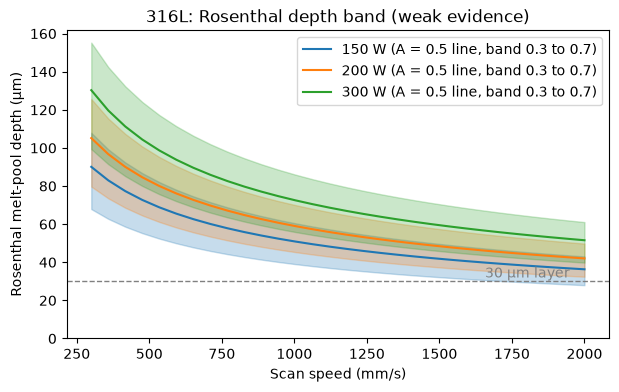

In [13]:
speeds = np.linspace(300, 2000, 30)
fig, ax = plt.subplots(figsize=(7, 4))
for P, colour in [(150, "tab:blue"), (200, "tab:orange"), (300, "tab:green")]:
    bands = [melt_pool_band(P, v)["band"] for v in speeds]
    lo = [b_[0]["depth_um"] for b_ in bands]
    mid = [b_[1]["depth_um"] for b_ in bands]
    hi = [b_[2]["depth_um"] for b_ in bands]
    ax.fill_between(speeds, lo, hi, color=colour, alpha=0.25)
    ax.plot(speeds, mid, color=colour, label=f"{P} W (A = 0.5 line, band 0.3 to 0.7)")
ax.axhline(30, color="grey", ls="--", lw=1)
ax.text(1950, 32, "30 µm layer", ha="right", color="grey")
ax.set_ylim(0, None)
ax.set_xlabel("Scan speed (mm/s)")
ax.set_ylabel("Rosenthal melt-pool depth (µm)")
ax.set_title("316L: Rosenthal depth band (weak evidence)")
ax.legend()
plt.show()

### 1.4 The tools as LangChain tools

An agent framework cannot call a Python function directly. It needs a **tool**: a name, a description and a schema
of the arguments, which LangChain sends to the model with every call (`bind_tools`, 2.2). `tool(function,
parse_docstring=True)` builds all three from what each function already has: its name, its type hints (so
`power_W: float` becomes a number argument) and its docstring (the first part becomes the description, the `Args:`
lines become the argument descriptions). Nothing is written twice, so a tool and its function cannot drift apart.

What the model sees is printed below: the name, the first line of the description, and each argument with its type
and unit. What it gets back is the function's dictionary, whose `summary` sentence restates the inputs and units.

In [14]:
from langchain_core.tools import tool

convert_units_tool = tool(convert_units, parse_docstring=True)
energy_density_tool = tool(energy_density, parse_docstring=True)
melt_pool_band_tool = tool(melt_pool_band, parse_docstring=True)
PART1_TOOLS = [convert_units_tool, energy_density_tool, melt_pool_band_tool]

for t in PART1_TOOLS:
    print(f"{t.name}: {t.description.splitlines()[0]}")
    for arg, spec in t.args.items():
        kind = spec.get("type") or "/".join(a.get("type", "?") for a in spec.get("anyOf", []))
        print(f"    {arg:<16} {kind:<14} {spec.get('description', '')}")

convert_units: Convert a power, speed, length or energy density value from one unit to another. Use this whenever a paper reports a value in a different unit from the one needed for a comparison
    value            number         the number to convert.
    from_unit        string         unit of the value, one of W, kW, mm/s, m/s, mm/min, m/min, um, µm, mm, m, J/mm3, J/m3.
    to_unit          string         unit wanted, same list; must measure the same quantity as from_unit.
energy_density: Volumetric energy density E_v = P/(v*h*t) in J/mm³ and linear energy density P/v in J/mm. Use this when a paper gives laser power, scan speed, hatch spacing and layer thickness and you need
    power_W          number         laser power in W.
    scan_speed_mm_s  number         scan speed in mm/s (convert m/s first).
    hatch_um         number         hatch spacing in µm.
    layer_um         number         layer thickness in µm.
melt_pool_band: Estimated melt-pool width and depth (µm) from the 

In [15]:
# Tests for 1.4
check("the tools keep the function names", [t.name for t in PART1_TOOLS] == ["convert_units", "energy_density", "melt_pool_band"])
check("argument descriptions with units come from the docstring", "laser power in W" in energy_density_tool.args["power_W"]["description"])
check("a tool call gives exactly the function's answer",
      energy_density_tool.invoke({"power_W": 200, "scan_speed_mm_s": 800, "hatch_um": 100, "layer_um": 30})["ved_J_mm3"]
      == energy_density(200, 800, 100, 30)["ved_J_mm3"])
check("convert_units as a tool: 0.8 m/s is 800 mm/s",
      convert_units_tool.invoke({"value": 0.8, "from_unit": "m/s", "to_unit": "mm/s"})["value"] == 800)
check("melt_pool_band as a tool returns the three absorptivities",
      [r["absorptivity"] for r in melt_pool_band_tool.invoke({"power_W": 200, "scan_speed_mm_s": 800})["band"]] == [0.3, 0.5, 0.7])

  ok  the tools keep the function names
  ok  argument descriptions with units come from the docstring
  ok  a tool call gives exactly the function's answer
  ok  convert_units as a tool: 0.8 m/s is 800 mm/s
  ok  melt_pool_band as a tool returns the three absorptivities


### Part 1 summary

- Three tested tools: `convert_units`, `energy_density`, `melt_pool_band`. None needs a model.
- Each returns numbers for code and a sentence with inputs and units for the agent.
- Bad inputs raise readable errors. Suspicious ones are flagged in the sentence.
- The melt-pool solver agrees with an independent high-speed formula, but its output stays weak evidence.

**Next:** Part 2 connects the language model, and Part 3 gives it a library of papers to search.


## Part 2. How do we talk to the model reliably?

- **Question:** How do I get reasoning, structured answers and tool calls out of GLM-5.2, and know what each call cost?
- **Course concept:** prompting, structured output and function calling (Modules 1 and 2)
- **Framework feature:** `ChatOpenAI` (as `ChatGLM`, 0.2) with `with_structured_output` (Pydantic) and `bind_tools`, and `create_agent`. The Reader in Part 5 adds `ChatPromptTemplate`
- **Evidence:** the spike in 2.2: three structured output methods compared, tool calls, a full agent round, tokens and seconds per call (capability 33)

### 2.1 The plain client

`ask_llm()` from 0.1 is the first slice: the plain `openai` client, used for the Checkpoint 3.1 demo
(3.8). The cell below is the one deliberate live call in the notebook, a smoke test that the endpoint answers.
Everything else goes through `glm` and the cache, so it replays offline.


In [16]:
# Test: one short call (skipped off-network)
if LLM_OK:
    reasoning, answer = ask_llm([{"role": "user", "content": "In one sentence, what is volumetric energy density in PBF-LB?"}],
                                max_tokens=2000)
    print("answer:", answer)
    check("the model returned an answer", len(answer) > 10)
    check("the model returned its reasoning", len(reasoning) > 10)

--- reasoning (584 words) ---
1.  **Analyze the Request:**
    *   **Topic:** Volumetric energy density (VED) in PBF-LB (Powder Bed Fusion - Laser Beam).
    *   **Constraint:** Exactly *one sentence*.
    *   **Goal:** Define/explain what it is clearly and accurately.

2.  **Define Volumetric Energy Density (VED) in PBF-LB:**
    *   What is it? It's a parameter used to quantify the amount of energy input into the material during the 3D printing process.
    *   How is it calculated? Laser power ($P$) divided by the product of laser scan speed ($v$), hatch spacing ($h$), and layer thickness ($t$). Formula: $E_v = \frac{P}{v \cdot h \cdot t}$.
    *   What does it represent/impact? It represents the energy applied per unit volume of material and critically influences part density, microstructure, and mechanical properties.

3.  **Draft Initial Sentences:**
    *   *Draft 1:* Volumetric energy density in PBF-LB is a critical process parameter defined as the laser power divided by the pr

### 2.2 Spike: what GLM-5.2 can do through LangChain with thinking on

The Reader and the Analyst depend on four features. Each is checked here with real calls through `glm`, so every
call is cached and traced in `data/traces/part2_spike.jsonl`. After the first run these cells replay from the cache.
`model_cell` runs a cell's calls and, if an answer is neither cached nor reachable, prints why and skips the checks.

**(a) Reasoning.** One short question, asked twice. The second answer must come from the cache with the same reasoning.

In [17]:
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage


def model_cell(fn):
    """Run a cell's model calls. If an answer is neither cached nor reachable, say so and return None."""
    try:
        return fn()
    except ModelUnavailable as e:
        print(f"Skipped: {e}. Connect to the endpoint and re-run this cell.")
        return None


TRACER.start("part2_spike")
SHORT_QUESTION = [HumanMessage("In one sentence, what is volumetric energy density in PBF-LB?")]
spike_a = model_cell(lambda: [glm.invoke(SHORT_QUESTION, config={"metadata": {"agent": "spike (a) reasoning"}})
                              for _ in range(2)])
if spike_a:
    print("\nanswer:", spike_a[0].content)

--- [spike (a) reasoning] from cache: 3.14 s, 28 in / 620 out tokens (569 reasoning) ---
reasoning (365 words): 1.  **Analyze the Request:**
    *   **Topic:** Volumetric energy density (VED) in Powder Bed Fusion - Laser Beam (PBF-LB).
    *   **Constraint:** Exactly one sentence.
    *   **Goal:** Define what it is concisely and accurately.

2.  **Deconstruct Volumetric Energy Density in PBF-LB:**
    *   What is it? A parameter used to quantify the amount of energy applied by the laser to a specific volume of powder.
    *   What is the formula? $VED = \frac{P}{v \cdot h \cdot t}$ (Laser Power divided by scan speed, hatch spacing, and layer thickness).
    *   What is its purpose? It dictates the thermal input, which determines melt pool dynamics, microstructure, defect formation (porosity), and overall part density/quality.

3.  **Draft Initial Sentences:**
    *   *Draft 1:* Volumetric energy density in PBF-LB is a process parameter that defines the amount of laser energy applied t

In [18]:
# Tests for (a)
if spike_a:
    first, second = spike_a
    check("the reasoning text is kept", len(reasoning_of(first)) > 50)
    check("the token count shows reasoning tokens", first.usage_metadata["output_token_details"]["reasoning"] > 0)
    check("the second answer came from the cache", load_trace("part2_spike")[1]["cached"])
    check("with the same reasoning and answer", reasoning_of(second) == reasoning_of(first) and second.content == first.content)
    check("and it knows how long the real call took", second.response_metadata["seconds"] > 0)

  ok  the reasoning text is kept
  ok  the token count shows reasoning tokens
  ok  the second answer came from the cache
  ok  with the same reasoning and answer
  ok  and it knows how long the real call took


**(b) Structured output.** The Reader must return records in a fixed schema, not free text. LangChain's
`with_structured_output(Schema, method=...)` offers three ways to make the model do that on an OpenAI-compatible server:

| Method | How it works |
|---|---|
| `json_schema` | The schema goes to the server as `response_format`. vLLM constrains decoding so the answer must match it. |
| `function_calling` | The schema becomes a tool the model is forced to call. Its arguments are the record. |
| `json_mode` | The server only guarantees valid JSON. The schema has to be written into the prompt by hand. |

Each method extracts two records from each of two **made-up** test passages (not from real papers). Thinking stays
on. `include_raw=True` returns the raw message next to the parsed records, so the reasoning is not lost.
`SpikeRecord` is only for this test. The real Reader schema comes with the Reader.

In [19]:
class SpikeRecord(BaseModel):
    """One parameter set and the density measured for it, copied from the passage."""
    power_W: float | None = Field(None, description="laser power in W")
    speed_mm_s: float | None = Field(None, description="scan speed in mm/s")
    hatch_um: float | None = Field(None, description="hatch spacing in µm")
    layer_um: float | None = Field(None, description="layer thickness in µm")
    density_pct: float | None = Field(None, description="relative density in %")
    density_method: str | None = Field(None, description="how density was measured, e.g. Archimedes")
    quote: str = Field(description="the exact sentence the values come from")


class SpikeRecords(BaseModel):
    """All parameter sets with a measured density in the passage."""
    records: list[SpikeRecord]


SPIKE_PASSAGES = {   # MADE-UP passages for this test only
    "p1": ("Cubes were built with a laser power of 195 W, a scan speed of 750 mm/s, a hatch spacing of 90 µm and a "
           "layer thickness of 30 µm. Their relative density, measured by the Archimedes method, was 99.62 %. "
           "A second set at 170 W and 600 mm/s with the same hatch and layer reached 99.10 %."),
    "p2": ("Samples were produced at 30 µm layer thickness with 120 µm hatch distance. At 140 W and 100 mm/s the "
           "relative density from image analysis of polished cross sections was 97.76 %, while 190 W and 800 mm/s "
           "gave 99.31 %."),
}
SPIKE_EXPECTED = {"p1": [(195, 750, 90, 30, 99.62), (170, 600, 90, 30, 99.10)],
                  "p2": [(140, 100, 120, 30, 97.76), (190, 800, 120, 30, 99.31)]}
EXTRACT_RULES = ("You extract process parameters from a PBF-LB paper passage. Copy numbers exactly as written, "
                 "never calculate, leave a field empty if it is not stated.")


def spike_extract(method: str, pid: str) -> dict:
    rules = EXTRACT_RULES
    if method == "json_mode":                      # json_mode needs the schema written into the prompt
        rules += " Answer only with JSON matching this schema: " + json.dumps(SpikeRecords.model_json_schema())
    chain = glm.with_structured_output(SpikeRecords, method=method, include_raw=True)
    out = chain.invoke([SystemMessage(rules), HumanMessage(f"Passage:\n{SPIKE_PASSAGES[pid]}")],
                       config={"metadata": {"agent": f"spike (b) {method}"}})
    raw, parsed = out["raw"], out["parsed"]
    got = [(r.power_W, r.speed_mm_s, r.hatch_um, r.layer_um, r.density_pct) for r in parsed.records] if parsed else None
    usage = raw.usage_metadata or {}
    return {"method": method, "passage": pid, "parsed": parsed is not None, "correct": got == SPIKE_EXPECTED[pid],
            "seconds": raw.response_metadata.get("seconds"), "out_tokens": usage.get("output_tokens"),
            "reasoning_tokens": (usage.get("output_token_details") or {}).get("reasoning"),
            "reasoning_words": len(reasoning_of(raw).split()), "error": str(out["parsing_error"] or "")[:60]}


SO_METHODS = ["json_schema", "function_calling", "json_mode"]
spike_b = model_cell(lambda: [spike_extract(m, p) for m in SO_METHODS for p in SPIKE_PASSAGES])
if spike_b:
    print()
    print_rows(spike_b, [("method", "method", 16), ("passage", "passage", 7), ("parsed", "parsed", 6),
                         ("correct", "correct", 7), ("seconds", "s", 5), ("out_tokens", "tok out", 7),
                         ("reasoning_tokens", "reason", 6), ("reasoning_words", "reason words", 12), ("error", "error", 20)])

--- [spike (b) json_schema] from cache: 5.54 s, 130 in / 1285 out tokens (1070 reasoning) ---
reasoning (597 words): 1.  **Analyze the Request:**
    *   Goal: Extract process parameters from the provided PBF-LB paper passage.
    *   Rule 1: Copy numbers exactly as written.
    *   Rule 2: Never calculate.
    *   Rule 3: Leave a field empty if not stated.
    *   Input passage: "Cubes were built with a laser power of 195 W, a scan speed of 750 mm/s, a hatch spacing of 90 µm and a layer thickness of 30 µm. Their relative density, measured by the Archimedes method, was 99.62 %. A second set at 170 W and 600 mm/s with the same hatch and layer reached 99.10 %."

2.  **Analyze the Passage for Parameters:**
    *   "laser power of 195 W" -> Laser Power 1: 195 W
    *   "scan speed of 750 mm/s" -> Scan Speed 1: 750 mm/s
    *   "hatch spacing of 90 µm" -> Hatch Spacing 1: 90 µm
    *   "layer thickness of 30 µm" -> Layer Thickness 1: 30 µm
    *   "relative density... was 99.62 %" -> Relati

In [20]:
# Tests for (b)
if spike_b:
    for m in SO_METHODS:
        rows = [r for r in spike_b if r["method"] == m]
        check(f"{m}: both passages parsed and every number copied correctly", all(r["parsed"] and r["correct"] for r in rows))
    check("json_schema keeps the model's reasoning", all(r["reasoning_words"] > 0 for r in spike_b if r["method"] == "json_schema"))

  ok  json_schema: both passages parsed and every number copied correctly
  ok  function_calling: both passages parsed and every number copied correctly
  ok  json_mode: both passages parsed and every number copied correctly
  ok  json_schema keeps the model's reasoning


**Which structured output method?** All three were correct here, so the choice rests on the other columns:
- `json_schema` (chosen for the Reader and the Analyst): the server enforces the schema, and the model still writes a
  full reasoning before the answer, which is what I want to read when a value looks wrong.
- `function_calling` was the fastest, but the model reasoned much less before filling the forced tool call. It is the
  fallback if `json_schema` ever misbehaves (for example, constrained decoding can pad the JSON with whitespace).
- `json_mode` needs the schema pasted into the prompt and nothing enforces it. Not used.

**(c) Tool calls.** `bind_tools` describes Python functions to the model as tools. The model answers with a tool call
(a name and arguments), my code runs the function, and the result goes back as a `ToolMessage`. This is the loop the
ReAct agent will run, so here it is done once by hand. Part 1's `energy_density` becomes a LangChain tool with
`tool(...)`, which reads the name, type hints and docstring. Then the same question goes to `create_agent`, LangChain's
ready-made agent loop (a small LangGraph graph), which does the round trip by itself.

In [21]:
from langchain.agents import create_agent
from langchain_core.tools import tool

# energy_density_tool is the Part 1 function as a LangChain tool (1.4)
print("Tool the model sees:", energy_density_tool.name, "| arguments:", list(energy_density_tool.args))


def tool_round_by_hand():
    bound = glm.bind_tools([energy_density_tool])
    cfg = {"metadata": {"agent": "spike (c) bind_tools"}}
    msgs = [HumanMessage("What is the volumetric energy density for 200 W, 800 mm/s, 100 µm hatch and 30 µm layers?")]
    ask = bound.invoke(msgs, config=cfg)
    result = energy_density_tool.invoke(ask.tool_calls[0]["args"])            # my code runs the tool, not the model
    msgs += [ask, ToolMessage(result["summary"], tool_call_id=ask.tool_calls[0]["id"])]
    final = bound.invoke(msgs, config=cfg)
    return ask, result, final


def tool_round_by_agent():
    agent = create_agent(model=glm, tools=[energy_density_tool],
                         system_prompt="You answer PBF-LB questions. Never calculate yourself, use the tools.")
    return agent.invoke({"messages": [HumanMessage("Energy density at 180 W, 700 mm/s, 90 µm hatch and 40 µm layers?")]},
                        config={"metadata": {"agent": "spike (c) create_agent"}})


spike_c = model_cell(lambda: (tool_round_by_hand(), tool_round_by_agent()))
if spike_c:
    (ask, tool_result, final), agent_out = spike_c
    print("\nBy hand: final answer:", final.content[:300])
    print("\ncreate_agent, message types:", [m.type for m in agent_out["messages"]])
    print("create_agent, final answer:", agent_out["messages"][-1].content[:300])

Tool the model sees: energy_density | arguments: ['power_W', 'scan_speed_mm_s', 'hatch_um', 'layer_um']
--- [spike (c) bind_tools] from cache: 0.77 s, 349 in / 73 out tokens (36 reasoning) ---
reasoning (23 words): The user wants to calculate the volumetric energy density given the parameters: 200 W, 800 mm/s, 100 µm hatch, 30 µm layer thickness.
tool call: energy_density({'power_W': 200, 'scan_speed_mm_s': 800, 'hatch_um': 100, 'layer_um': 30})
--- [spike (c) bind_tools] from cache: 1.42 s, 473 in / 216 out tokens (15 reasoning) ---
reasoning (13 words): The function returned the results. Let me present them clearly to the user.
--- [spike (c) create_agent] from cache: 0.69 s, 361 in / 69 out tokens (32 reasoning) ---
reasoning (20 words): The user wants to calculate energy density with given parameters: 180 W, 700 mm/s, 90 µm hatch, 40 µm layers.
tool call: energy_density({'power_W': 180, 'scan_speed_mm_s': 700, 'hatch_um': 90, 'layer_um': 40})
--- [spike (c) create_agent] from cache

In [22]:
# Tests for (c)
if spike_c:
    check("bind_tools: the model asked for energy_density", ask.tool_calls and ask.tool_calls[0]["name"] == "energy_density")
    check("with the right arguments and units",
          ask.tool_calls[0]["args"] == {"power_W": 200, "scan_speed_mm_s": 800, "hatch_um": 100, "layer_um": 30})
    check("the final answer uses the tool's number (83.3 J/mm³)", "83.3" in final.content)
    kinds = [m.type for m in agent_out["messages"]]
    check("create_agent ran a full round: question, tool call, tool result, answer", kinds == ["human", "ai", "tool", "ai"])
    check("create_agent's answer uses the tool result (71.4 J/mm³)", "71.4" in agent_out["messages"][-1].content)
    check("the reasoning is kept at every agent step",
          all(reasoning_of(m) for m in agent_out["messages"] if m.type == "ai"))

  ok  bind_tools: the model asked for energy_density
  ok  with the right arguments and units
  ok  the final answer uses the tool's number (83.3 J/mm³)
  ok  create_agent ran a full round: question, tool call, tool result, answer
  ok  create_agent's answer uses the tool result (71.4 J/mm³)
  ok  the reasoning is kept at every agent step


**(d) Time and tokens per call.** The trace of this section already holds what each call cost. The seconds are those of
the real call, also when the answer was replayed from the cache.

In [23]:
show_trace("part2_spike")

Trace 'part2_spike': 12 model calls
#    agent / node            source  s       tok in  tok out  reason  answer or tool call                                         
---  ----------------------  ------  ------  ------  -------  ------  ------------------------------------------------------------
1    spike (a) reasoning     cache   3.14    28      620      569     In PBF-LB, volumetric energy density is a critical proces...
2    spike (a) reasoning     cache   3.14    28      620      569     In PBF-LB, volumetric energy density is a critical proces...
3    spike (b) json_schema   cache   5.54    130     1285     1070    {   "records": [     {       "power_W": 195,       "speed...
4    spike (b) json_schema   cache   4.15    107     933      745     {   "records": [     {       "power_W": 140,       "speed...
5    spike (b) function_...  cache   1.88    560     330      127     SpikeRecords({'records': [{'power_W': 195, 'speed_mm_s': ...
6    spike (b) function_...  cache   1.71    53

In [24]:
# Tests for (d): every spike call is in the trace with its reasoning, tokens and time
if spike_a and spike_b and spike_c:
    spike_trace = load_trace("part2_spike")
    check("2 + 6 + 2 + 2 = 12 model calls traced", len(spike_trace) == 12)
    check("every call has its reasoning, token counts and seconds",
          all(r["reasoning"] and r["output_tokens"] and r["seconds"] for r in spike_trace))
    check("the repeated question in (a) was replayed from the cache", spike_trace[1]["cached"])

  ok  2 + 6 + 2 + 2 = 12 model calls traced
  ok  every call has its reasoning, token counts and seconds
  ok  the repeated question in (a) was replayed from the cache


## Part 3. Where does the knowledge come from? (retrieval)

- **Question:** Which papers and passages hold the parameters and densities, and how does the agent find them?
- **Course concept:** retrieval-augmented generation: chunking, embeddings, a vector store, MMR, metadata filters, grounding (Module 3)
- **Framework feature:** the Europe PMC API, Qwen3 embeddings in ChromaDB with my own chunking and MMR (3.3 to 3.5), then LangChain's text splitter, `Chroma` vector store and MMR retriever with an alloy filter (3.10)
- **Evidence:** the distractor kept out by the filter (3.6), the demo with and without retrieval and its citation check (3.8), the frozen library (3.9), review sheets for the answer key (3.11) (capabilities 1 to 8)

**Why retrieval at all.** The facts this agent needs (which study used which power, speed and layer thickness,
and what density it measured) are in papers, not in the model. GLM-5.2 could take a whole stack of papers in
one prompt, but that context would be re-sent at every agent step, facts in the middle of a long context are
easily missed (Module 2), and the source check needs the exact passage behind every value. So the agent
retrieves only the few passages it needs.

Retrieval happens at three levels:

| Level | Question | Mechanism |
|---|---|---|
| Papers | Which open-access 316L studies exist? | Europe PMC search API |
| Passages | Where in them are the parameters and densities? | Semantic search over chunks (this part) |
| Numbers | Which extracted values match given settings? | SQL over an evidence table (Part 9) |

**Data source.** I first used OpenAlex and downloaded PDFs, but most publishers block automated downloads
(HTTP 403 on 23 of 25 papers). **Europe PMC** serves the full text of open-access papers through an official
API as structured XML, with tables intact. So citations point to a **section or table** rather than a page,
which is easier to check by hand anyway.

In [25]:
import re
import xml.etree.ElementTree as ET
import requests

EPMC = "https://www.ebi.ac.uk/europepmc/webservices/rest"
PAPERS = DATA / "papers"
PAPERS.mkdir(exist_ok=True)


def search_papers(query: str, n: int = 30) -> list[dict]:
    """Search Europe PMC and return paper records (pmcid, doi, title, year, journal)."""
    r = requests.get(f"{EPMC}/search", params={"query": query, "format": "json", "pageSize": n,
                                                "resultType": "lite"}, timeout=30)
    r.raise_for_status()
    return [{"pmcid": w["pmcid"], "doi": w.get("doi", ""), "title": w["title"], "year": w.get("pubYear"),
             "journal": w.get("journalTitle", "")} for w in r.json()["resultList"]["result"] if w.get("pmcid")]


def fetch_fulltext(pmcid: str) -> Path:
    """Download the full-text XML once and cache it in data/papers/."""
    path = PAPERS / f"{pmcid}.xml"
    if not path.exists():
        r = requests.get(f"{EPMC}/{pmcid}/fullTextXML", timeout=60)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path

### 3.1 Reading a paper and labelling its alloy

The XML gives the title, DOI, section texts and every table. Tables are turned into plain rows
(`cell | cell | cell`) so that numbers stay next to their column headers and units.

**Alloy label.** Every chunk will carry the paper's alloy, so a search for 316L can exclude other alloys. A
paper about 25CrMo4 steel may still *mention* 316L for comparison, so the label comes from the **title**
first, and only falls back to counting mentions in the text.

In [26]:
GRADES = {  # name -> regular expression
    "316L": r"316\s?L", "304L": r"\b304L?\b", "17-4PH": r"17-4\s?PH", "25CrMo4": r"25CrMo4",
    "AlSi10Mg": r"AlSi10Mg", "Ti-6Al-4V": r"Ti-?6Al-?4V", "IN718": r"(IN|Inconel\s?)718",
    "H13": r"\bH13\b", "maraging": r"[Mm]araging",
}


def text_of(el) -> str:
    return re.sub(r"\s+", " ", "".join(el.itertext())).strip() if el is not None else ""


def detect_alloy(title: str, full_text: str) -> str:
    # Title first: it names the alloy the paper is actually about.
    in_title = [g for g, rx in GRADES.items() if re.search(rx, title)]
    if in_title:
        return in_title[0]
    counts = {g: len(re.findall(rx, full_text)) for g, rx in GRADES.items()}
    return max(counts, key=counts.get) if max(counts.values()) else "unknown"


def parse_paper(path: Path, paragraph_sep: str = " ") -> dict:
    """Parse a Europe PMC JATS XML file into title, doi, sections, tables and alloy.

    paragraph_sep joins the paragraphs of a section (the frozen library in 3.9 uses "\n\n").
    """
    root = ET.parse(path).getroot()
    title = text_of(root.find(".//article-title"))
    doi = text_of(root.find(".//article-id[@pub-id-type='doi']"))
    tables = []
    for tw in root.iter("table-wrap"):  # tables sit in <body> or <floats-group>
        head = f"{text_of(tw.find('label'))} {text_of(tw.find('caption'))}".strip()
        rows = [" | ".join(text_of(c) for c in tr if c.tag in ("td", "th")) for tr in tw.iter("tr")]
        rows = [r for r in rows if r.strip(" |")]
        if rows:
            tables.append({"label": head, "text": "\n".join(rows)})
    sections = []
    body = root.find(".//body")
    if body is not None:
        for sec in body.findall("sec"):
            paras = [text_of(p) for p in sec.iter("p")]
            sections.append({"title": text_of(sec.find("title")) or "Body", "text": paragraph_sep.join(p for p in paras if p)})
    full = " ".join(s["text"] for s in sections) + " " + " ".join(t["text"] for t in tables)
    return {"title": title, "doi": doi, "sections": sections, "tables": tables, "alloy": detect_alloy(title, full)}


def has_parameter_table(paper: dict) -> bool:
    # At least one table that mentions power, speed and density or porosity.
    for t in paper["tables"]:
        s = (t["label"] + " " + t["text"]).lower()
        if "power" in s and ("speed" in s or "velocity" in s or "mm/s" in s) and ("density" in s or "porosity" in s):
            return True
    return False

### 3.2 Choosing the papers

The search asks Europe PMC for open-access, CC BY licensed 316L PBF-LB papers that mention density and scan
speed. A paper is **kept** if its alloy label is 316L and it has at least one parameter table. For this first
slice I keep **5 papers**, plus **one deliberate distractor**: the first paper about a *different* alloy that
also has a parameter table. The distractor is there to test the alloy filter (the failure mode in 3.6).

The selection is saved, so later runs reuse the same papers even if the search results change.

In [27]:
SELECTION = PAPERS / "selection.json"
QUERY = ('("316L") AND ("laser powder bed fusion" OR "selective laser melting") AND '
         '("relative density" OR "porosity") AND ("scan speed" OR "scanning speed") AND '
         'OPEN_ACCESS:y AND HAS_FT:y AND LICENSE:"cc by"')

if SELECTION.exists():
    selection = json.loads(SELECTION.read_text(encoding="utf-8"))
else:
    selection, distractor = [], None
    for hit in search_papers(QUERY, n=40):
        paper = parse_paper(fetch_fulltext(hit["pmcid"]))
        if not has_parameter_table(paper):
            continue
        if paper["alloy"] == "316L" and len(selection) < 5:
            selection.append({**hit, "alloy": "316L", "role": "source"})
        elif paper["alloy"] not in ("316L", "unknown") and distractor is None:
            distractor = {**hit, "alloy": paper["alloy"], "role": "distractor"}
        if len(selection) == 5 and distractor:
            break
    selection.append(distractor)
    SELECTION.write_text(json.dumps(selection, indent=1), encoding="utf-8")

papers = {s["pmcid"]: parse_paper(fetch_fulltext(s["pmcid"])) for s in selection}
for s in selection:
    p = papers[s["pmcid"]]
    print(f"{s['role']:<10} {s['pmcid']}  {p['alloy']:<8} {len(p['tables']):>2} tables  {s['year']}  {p['title'][:70]}")

source     PMC13073740  316L      5 tables  2026  A Lattice Boltzmann Thermal Model for Predicting Melt Pool Geometry in
source     PMC12735063  316L      5 tables  2025  Role of Laser Powder Bed Fusion Process Factors in Determining the Por
source     PMC13208960  316L      3 tables  2026  Novel Design in Venturi-Type Nozzle by Selective Laser Melting for Enh
source     PMC12387571  316L      4 tables  2025  Manufacturing, Microstructure, and Mechanics of 316L SS Biomaterials b
source     PMC12194911  316L     18 tables  2025  A Review of Optimization of Additively Manufactured 316/316L Stainless
distractor PMC12693020  25CrMo4   8 tables  2025  Laser Powder Bed Fusion of 25CrMo4 Steel: Effect of Process Parameters


In [28]:
# Tests for the paper library
check("5 source papers and 1 distractor", [s["role"] for s in selection].count("source") == 5
      and [s["role"] for s in selection].count("distractor") == 1)
check("every source paper is labelled 316L", all(papers[s["pmcid"]]["alloy"] == "316L" for s in selection if s["role"] == "source"))
check("the distractor is another alloy", all(papers[s["pmcid"]]["alloy"] != "316L" for s in selection if s["role"] == "distractor"))
check("every paper has a parameter table", all(has_parameter_table(p) for p in papers.values()))
check("every paper has a DOI", all(p["doi"] for p in papers.values()))

  ok  5 source papers and 1 distractor
  ok  every source paper is labelled 316L
  ok  the distractor is another alloy
  ok  every paper has a parameter table
  ok  every paper has a DOI


### 3.3 Chunking

- **Text:** each section is cut into windows of about **250 words with 50 words of overlap**, so a sentence cut
  at a boundary still appears whole in the next chunk. Each chunk keeps its section title.
- **Tables:** **never split**. A table row means nothing without its header and units, and process parameters
  are almost always reported in tables. Each table becomes one chunk, caption included.
- Every chunk carries metadata: paper ID, DOI, title, **alloy**, where it came from (section or table) and kind.

Smaller chunks than the lecture's 800 to 1000 tokens, because the answer is often a single table row and the
citation should point to one place.

In [29]:
def chunk_paper(pmcid: str, paper: dict, size: int = 250, overlap: int = 50) -> list[dict]:
    """Split a parsed paper into text chunks (overlapping word windows) and whole-table chunks."""
    meta = {"pmcid": pmcid, "doi": paper["doi"], "title": paper["title"][:200], "alloy": paper["alloy"]}
    chunks = []
    for sec in paper["sections"]:
        words = sec["text"].split()
        for start in range(0, max(len(words) - overlap, 1), size - overlap):
            piece = " ".join(words[start:start + size])
            if len(piece.split()) >= 30:  # skip scraps
                chunks.append({"text": piece, **meta, "where": sec["title"][:80], "kind": "text"})
    for t in paper["tables"]:
        chunks.append({"text": f"{t['label']}\n{t['text']}", **meta, "where": (t["label"] or "Table")[:80], "kind": "table"})
    for i, c in enumerate(chunks):
        c["id"] = f"{pmcid}-{i:03d}"
    return chunks


chunks = [c for pmcid, p in papers.items() for c in chunk_paper(pmcid, p)]
n_tables = sum(c["kind"] == "table" for c in chunks)
print(f"{len(chunks)} chunks: {len(chunks) - n_tables} text, {n_tables} tables")

328 chunks: 285 text, 43 tables


In [30]:
# Tests for chunking
text_chunks = [c for c in chunks if c["kind"] == "text"]
check("text chunks are at most 250 words", max(len(c["text"].split()) for c in text_chunks) <= 250)
check("one chunk per table (tables are never split)", n_tables == sum(len(p["tables"]) for p in papers.values()))
check("chunk ids are unique", len({c["id"] for c in chunks}) == len(chunks))
check("every chunk knows its paper, alloy and place", all(c["pmcid"] and c["alloy"] and c["where"] for c in chunks))
first = chunk_paper("x", {"doi": "d", "title": "t", "alloy": "316L", "tables": [],
                          "sections": [{"title": "S", "text": " ".join(f"w{i}" for i in range(400))}]})
check("consecutive text chunks overlap by 50 words", first[0]["text"].split()[-50:] == first[1]["text"].split()[:50])

  ok  text chunks are at most 250 words
  ok  one chunk per table (tables are never split)
  ok  chunk ids are unique
  ok  every chunk knows its paper, alloy and place
  ok  consecutive text chunks overlap by 50 words


### 3.4 Embeddings and the vector database

- **Embedding model: Qwen3-Embedding-0.6B**, run locally on the laptop GPU (about 1.2 GB). The lab used
  all-MiniLM-L6-v2, but MiniLM silently cuts every input at 256 tokens, which would chop the longer tables.
  Qwen3 reads up to 32k tokens. Questions are encoded with the model's `query` prompt, chunks without one,
  as the model card recommends.
- **Vector database: ChromaDB**, stored in `data/chroma/`. Each chunk is stored with its vector and metadata,
  so a search can be **filtered by alloy**. Cosine similarity is used.
- Embedding all chunks takes about a minute the first time. Afterwards the database is reused.

In [31]:
import torch
import chromadb
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
_device = "cuda" if torch.cuda.is_available() else "cpu"
_kw = {"model_kwargs": {"torch_dtype": torch.float16}} if _device == "cuda" else {}
t0 = time.time()
try:  # use the cached copy without contacting Hugging Face (avoids hangs on a changing network)
    embedder = SentenceTransformer(EMBED_MODEL, device=_device, local_files_only=True, **_kw)
except Exception:  # first run: download it (about 1.2 GB)
    embedder = SentenceTransformer(EMBED_MODEL, device=_device, **_kw)
print(f"embedding model loaded on {_device} in {time.time() - t0:.0f} s")

chroma = chromadb.PersistentClient(path=str(DATA / "chroma"))
library = chroma.get_or_create_collection("papers_v1", metadata={"hnsw:space": "cosine"})

if library.count() != len(chunks):  # (re)build when the chunks changed
    chroma.delete_collection("papers_v1")
    library = chroma.create_collection("papers_v1", metadata={"hnsw:space": "cosine"})
    t0 = time.time()
    vectors = embedder.encode([c["text"] for c in chunks], batch_size=4, normalize_embeddings=True)
    print(f"embedded {len(chunks)} chunks in {time.time() - t0:.0f} s")
    library.add(ids=[c["id"] for c in chunks], embeddings=vectors.tolist(), documents=[c["text"] for c in chunks],
                metadatas=[{k: c[k] for k in ("pmcid", "doi", "title", "alloy", "where", "kind")} for c in chunks])
print("chunks in the vector database:", library.count())

C:\Users\Chinmay.Phutela\Carnegie Capstone\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/310 [00:00<00:34,  9.04it/s]

Loading weights:  17%|█▋        | 52/310 [00:00<00:00, 265.64it/s]

Loading weights:  30%|██▉       | 92/310 [00:00<00:00, 317.35it/s]

Loading weights:  42%|████▏     | 130/310 [00:00<00:00, 326.59it/s]

... (3 outputs left out)

Loading weights:  90%|████████▉ | 278/310 [00:00<00:00, 341.02it/s]

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 333.58it/s]

embedding model loaded on cuda in 3 s


chunks in the vector database: 328


In [32]:
check("every chunk is in the database", library.count() == len(chunks))
check("vectors have 1024 dimensions", len(library.get(limit=1, include=["embeddings"])["embeddings"][0]) == 1024)

  ok  every chunk is in the database
  ok  vectors have 1024 dimensions


### 3.5 Searching: top 5, diverse, filtered by alloy

`search_passages()` is the function the agent will call as a tool. It:
1. encodes the question and asks ChromaDB for the **60 closest chunks** (only 316L chunks when an alloy is given).
2. picks **5** of them with **maximal marginal relevance** (Lab 3.2): each pick balances relevance to the question
   against similarity to chunks already picked (lambda = 0.7 leans towards relevance).
3. allows **at most 2 chunks per paper**, so the evidence comes from several studies, which consensus needs.

**Why the cap matters (observed):** for the demo question, 19 of the 20 closest chunks came from one paper.
Without the cap the agent would see one study five times and mistake it for agreement. With only 20
candidates the cap left too few options, so the search now draws 60 candidates, which covers all five papers.

Every result keeps its citation: paper, DOI and section or table.

In [33]:
def search_passages(question: str, k: int = 5, alloy: str | None = "316L", fetch_k: int = 60,
                    lam: float = 0.7, max_per_paper: int = 2) -> list[dict]:
    """Find the k passages most relevant to a question, with citations.

    Use this to look up what the papers report (process parameters, densities, methods) before answering.
    alloy filters the library to one alloy (None searches everything). Returns a list of passages, each with
    text, pmcid, doi, title, where (section or table) and score (cosine similarity, higher is closer).
    """
    q = embedder.encode([question], prompt_name="query", normalize_embeddings=True)[0]
    res = library.query(query_embeddings=[q.tolist()], n_results=fetch_k, where={"alloy": alloy} if alloy else None,
                        include=["documents", "metadatas", "embeddings"])
    docs, metas, embs = res["documents"][0], res["metadatas"][0], np.array(res["embeddings"][0])
    relevance = embs @ q
    picked, per_paper = [], {}
    while len(picked) < min(k, len(docs)):
        best, best_score = None, -np.inf
        for i in range(len(docs)):
            if i in picked or per_paper.get(metas[i]["pmcid"], 0) >= max_per_paper:
                continue
            redundancy = max((float(embs[i] @ embs[j]) for j in picked), default=0.0)
            score = lam * relevance[i] - (1 - lam) * redundancy
            if score > best_score:
                best, best_score = i, score
        if best is None:
            break
        picked.append(best)
        per_paper[metas[best]["pmcid"]] = per_paper.get(metas[best]["pmcid"], 0) + 1
    return [{"text": docs[i], **metas[i], "score": round(float(relevance[i]), 3)} for i in picked]


def show_passages(passages, width=160):
    for n, p in enumerate(passages, 1):
        print(f"[{n}] {p['score']:.3f}  {p['alloy']:<8} {p['pmcid']}  {p['where'][:60]}")
        print("     " + p["text"][:width].replace("\n", " / ") + " ...")

In [34]:
LAYER_UM = 30  # layer thickness the engineer asked for: power and speed only make sense together with it
QUESTION = (f"For 316L at a layer thickness of {LAYER_UM} µm, which laser power and scan speed gave the highest "
            "relative density in these studies, and what density was reported?")
hits = search_passages(QUESTION)
show_passages(hits)

check("5 passages returned", len(hits) == 5)
check("all passages are 316L", all(h["alloy"] == "316L" for h in hits))
check("at most 2 passages per paper", max(sum(h["pmcid"] == p for h in hits) for p in {h["pmcid"] for h in hits}) <= 2)
check("passages are ordered by MMR, all reasonably relevant", min(h["score"] for h in hits) > 0.3)

[1] 0.756  316L     PMC12387571  2. Methodology
     the laser beam orientation between adjacent layers to promote better adhesion and enhance mechanical performance. For example, when the first layer was scanned  ...
[2] 0.735  316L     PMC13208960  Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser Power (W) | Scan Speed (mm/s) | Laser Energy Density (J/mm3) ...
[3] 0.701  316L     PMC12194911  2. DED, SLM, and EBM Process Parameter Effects and Optimizat
     hardness variation, though the hardness value itself may be slightly lower. In contrast, 30 µm, 80 µm, and 100 µm thicknesses show better hardness but lead to h ...
[4] 0.711  316L     PMC12387571  3. Results
     as a function of laser power (140 to 190 W) and scanning speed (600 to 900 mm/s). Porosity decreased with increasing laser power and decreasing scanning speed.  ...
[5] 0.637  316L     PMC13073740  4. Re

### 3.6 Failure mode: the similarity trap

Semantic search ranks by *meaning*, not by alloy. The distractor paper describes the same kind of experiment
(power, speed, density) for a different steel, so it looks relevant. The cell below runs the same question
**without** the alloy filter and **with** it.

In [35]:
distractor_id = next(s["pmcid"] for s in selection if s["role"] == "distractor")
unfiltered = search_passages(QUESTION, alloy=None, k=10)
print("WITHOUT alloy filter:")
show_passages(unfiltered, width=100)
print("\nWITH alloy filter (316L): distractor present?", any(h["pmcid"] == distractor_id for h in hits))

check("with the filter, the distractor never appears", not any(h["pmcid"] == distractor_id for h in hits))

WITHOUT alloy filter:
[1] 0.756  316L     PMC12387571  2. Methodology
     the laser beam orientation between adjacent layers to promote better adhesion and enhance mechanical ...
[2] 0.735  316L     PMC13208960  Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser  ...
[3] 0.701  316L     PMC12194911  2. DED, SLM, and EBM Process Parameter Effects and Optimizat
     hardness variation, though the hardness value itself may be slightly lower. In contrast, 30 µm, 80 µ ...
[4] 0.711  316L     PMC12387571  3. Results
     as a function of laser power (140 to 190 W) and scanning speed (600 to 900 mm/s). Porosity decreased ...
[5] 0.637  316L     PMC13073740  4. Results
     187 μm, while the corresponding melt pool depths are about 79 μm, 81 μm, and 68 μm. These values ind ...
[6] 0.597  25CrMo4  PMC12693020  Table 2 The parameters of the printing material.
     Table 2 The par

### 3.7 Stated conditions: the layer thickness behind each result

Laser power and scan speed only mean something together with **layer thickness** (and hatch spacing): 140 W at
100 mm/s is a different process at 30 µm than at 50 µm. Papers usually put these in the *Methods* text, while the
results sit in a table, so a single search for the question tends to return the table without the conditions.
(For the 30 µm question, Table 2 of the nozzle study is retrieved, but the sentence saying it was printed at
30 µm is not.)

So for every paper that appears in the search results, `stated_conditions()` collects the sentences that **state**
a layer thickness, hatch spacing or spot size **with a number**, preferring the Methods section. This is a
deterministic lookup, not a similarity search: exact facts come from code. Sentences that cite another study
(`[12]`) are skipped, because they describe someone else's experiment.

In [36]:
COND_TERMS = re.compile(r"(layer thickness|layer height|powder layer|hatch (spacing|distance)|spot (size|diameter))", re.I)
COND_NUMBER = re.compile(r"\d+(\.\d+)?\s?(µm|μm|um|mm)\b")
METHODS = re.compile(r"method|experiment|material|setup|procedure", re.I)


def stated_conditions(pmcid: str, max_sentences: int = 3, library: dict | None = None) -> list[dict]:
    """Return sentences from one paper that state its layer thickness, hatch spacing or spot size with a number.

    Use this to find the experimental conditions behind a retrieved result. Methods sections come first;
    sentences that cite other work ([n]) are skipped. Each item has the sentence and its section.
    library: parsed papers to read from (default: the five Checkpoint 3.1 papers of 3.2).
    """
    found = []
    for sec in (library or papers)[pmcid]["sections"]:
        for sentence in re.split(r"(?<=[.;])\s+(?=[A-Z])", sec["text"]):
            if COND_TERMS.search(sentence) and COND_NUMBER.search(sentence) and len(sentence) < 400 \
                    and not re.search(r"\[\d+", sentence):
                found.append({"pmcid": pmcid, "where": sec["title"][:80], "text": sentence,
                              "methods": bool(METHODS.search(sec["title"]))})
    found.sort(key=lambda s: not s["methods"])  # Methods first, otherwise keep the paper's order
    return found[:max_sentences]


def conditions_block(conds):
    return "\n".join(f"[C{n}] {c['pmcid']} | {c['where']}: {c['text']}" for n, c in enumerate(conds, 1))


conditions = [c for pmcid in dict.fromkeys(h["pmcid"] for h in hits) for c in stated_conditions(pmcid)]
print(conditions_block(conditions))

[C1] PMC12387571 | 2. Methodology: Based on these considerations, the laser spot size for fabricating 316L stainless steel specimens in this study was set to 138 µm.
[C2] PMC12387571 | 2. Methodology: Other processing parameters were kept constant, following the manufacturer’s recommendations: laser spot diameter of 138 µm, hatch spacing of 90 µm, and powder layer thickness of 30 µm.
[C3] PMC13208960 | 2. Experimental Setup: The SLM structures with dimensions of 2 × 2 × 5 mm3, a layer thickness of 30 μm, and a hatch spacing of 120 μm were used for every conditions.
[C4] PMC13208960 | 4. Conclusions: The SLM structures were formed on the distribution plate of Venturi nozzle under the optimal condition of SLM process, as follows: a layer thickness of 30 μm, a hatch spacing of 120 μm, a laser power of 140 W, and a scanning speed of 100 mm/s.
[C5] PMC12194911 | 2. DED, SLM, and EBM Process Parameter Effects and Optimization: Studies indicate that a 60 µm layer thickness reduces hardness va

In [37]:
# Tests for stated_conditions
nozzle = stated_conditions("PMC13208960")
check("the nozzle study states 30 µm layers", any("30 μm" in s["text"] or "30 µm" in s["text"] for s in nozzle))
check("its hatch spacing (120 µm) is found too", any("120" in s["text"] for s in nozzle))
check("Methods sentences come first", nozzle[0]["methods"])
check("sentences citing other studies are skipped", not any(re.search(r"\[\d+", s["text"]) for s in conditions))
check("only papers from the search results are looked up", {c["pmcid"] for c in conditions} <= {h["pmcid"] for h in hits})

  ok  the nozzle study states 30 µm layers
  ok  its hatch spacing (120 µm) is found too
  ok  Methods sentences come first
  ok  sentences citing other studies are skipped
  ok  only papers from the search results are looked up


### 3.8 Demo: does retrieval change the answer?

The same question is sent to GLM-5.2 twice:
1. **Without retrieval:** the question only. The model answers from what it learned in training.
2. **With retrieval:** the question plus the 5 passages above, the stated conditions of each source paper (3.7), and a grounding rule: *use only these passages,
   cite the paper and table or section for every number, and say "not reported" if the passages do not answer.*

Both answers, the passages and the model's reasoning are saved to `data/traces/checkpoint3_demo.json`.

**Replayed, not re-run (since 7 November).** These answers were submitted with Checkpoint 3.1. To keep them exactly
as submitted, the cell below replays the saved run from `checkpoint3_demo.json` and checks that today's retrieval
still returns the same passages and conditions. Set `RERUN_CHECKPOINT3_DEMO = True` only to call the model again,
which overwrites the saved run.

**Then the hand check:** take one number from the retrieved answer, open that paper (DOI below) at the cited
table, and confirm the value.

In [38]:
GROUNDED_SYSTEM = (
    "You answer questions about metal 3D printing (PBF-LB) using ONLY the numbered passages and the stated "
    "conditions provided. Every number you give must come from them; cite it as [n] or [Cn] with the paper ID "
    "and the table or section. Power and speed only make sense together with layer thickness: for every result, "
    "give the layer thickness and hatch spacing from the passages or stated conditions of the same paper, or say "
    "'layer thickness not stated'. Treat results at a different layer thickness from the one asked as different "
    "conditions and say so. If the passages do not contain the answer, say 'not reported in the retrieved "
    "passages'. Do not use outside knowledge and do not do arithmetic beyond reading values.")


def passages_block(passages):
    return "\n\n".join(f"[{n}] {p['pmcid']} | {p['where']} | doi:{p['doi']}\n{p['text']}"
                        for n, p in enumerate(passages, 1))


DEMO_TRACE = TRACES / "checkpoint3_demo.json"
RERUN_CHECKPOINT3_DEMO = False     # True calls GLM-5.2 again and overwrites the submitted run (normally never)
a0 = a1 = None

if DEMO_TRACE.exists() and not RERUN_CHECKPOINT3_DEMO:
    demo = json.loads(DEMO_TRACE.read_text(encoding="utf-8"))
    r0, a0 = demo["without_retrieval"]["reasoning"], demo["without_retrieval"]["answer"]
    r1, a1 = demo["with_retrieval"]["reasoning"], demo["with_retrieval"]["answer"]
    print(f"Replaying the submitted Checkpoint 3.1 run from {DEMO_TRACE.name} (no model call).")
    for title, reasoning, answer in [("WITHOUT retrieval", r0, a0), ("WITH retrieval", r1, a1)]:
        print("\n" + "=" * 30, title, "=" * 30)
        print(f"--- reasoning ({len(reasoning.split())} words, first 1500 characters) ---\n{reasoning[:1500]} ...\n")
        print(answer)
    check("the replayed run asked the same question", demo["question"] == QUESTION)
    check("today's retrieval returns the same 5 passages as the submitted run",
          [p["text"] for p in demo["with_retrieval"]["passages"]] == [h["text"] for h in hits])
    check("and the same stated conditions",
          [c["text"] for c in demo["with_retrieval"]["conditions"]] == [c["text"] for c in conditions])
elif LLM_OK:
    print("=" * 30, "WITHOUT retrieval", "=" * 30)
    r0, a0 = ask_llm([{"role": "user", "content": QUESTION + " Cite your sources."}], max_tokens=20000)
    print(a0)
    print("\n" + "=" * 30, "WITH retrieval", "=" * 30)
    r1, a1 = ask_llm([{"role": "system", "content": GROUNDED_SYSTEM},
                      {"role": "user", "content": f"Passages:\n\n{passages_block(hits)}\n\n"
                                                  f"Stated conditions:\n\n{conditions_block(conditions)}\n\n"
                                                  f"Question: {QUESTION}"}], max_tokens=20000)
    print(a1)
    (TRACES / "checkpoint3_demo.json").write_text(json.dumps({
        "question": QUESTION, "model": LLM_MODEL,
        "without_retrieval": {"reasoning": r0, "answer": a0},
        "with_retrieval": {"passages": hits, "conditions": conditions, "reasoning": r1, "answer": a1}}, indent=1, ensure_ascii=False), encoding="utf-8")
else:
    print("Skipped: connect to the network with the LLM endpoint and re-run this cell.")

if a1:
    check("the grounded answer cites passages, e.g. [2] or [2, PMC... | Table 2]", bool(re.search(r"\[\d+[\],]", a1)))
    check("the ungrounded answer is not empty", len(a0) > 0)

print("\nPapers for the hand check:")
for s in selection:
    if s["role"] == "source":
        print(f"  {s['pmcid']}  https://doi.org/{papers[s['pmcid']]['doi']}")

Replaying the submitted Checkpoint 3.1 run from checkpoint3_demo.json (no model call).

============================== WITHOUT retrieval ==============================
--- reasoning (2928 words, first 1500 characters) ---
1.  **Analyze the Request:**
    *   Material: 316L stainless steel.
    *   Layer thickness: 30 µm.
    *   Target: Laser power and scan speed that yielded the highest relative density.
    *   Output: Specific values (power, speed, density) and cited sources.
    *   Constraint: Needs to be from "these studies" (implying the user is referring to a specific set of literature, but since I don't have prior context, I must rely on widely known, highly cited, and seminal papers in LPBF/SLM of 316L with a 30 µm layer thickness).

2.  **Identify the missing context ("these studies"):**
    *   The prompt says "in these studies". Since I don't have an uploaded document or previous conversation, I need to provide answers from the most prominent/standard literature regarding 

### 3.9 The frozen library (v2): ten 316L papers and the distractor

The five papers above were enough to show that retrieval changes the answer. The agent's evaluation needs more:
papers at **different layer thicknesses**, papers whose settings are **close enough to disagree**, different
**density methods**, a **review** that quotes other studies, and a study with **HIP** next to as-built results.
So the library grows to ten 316L papers plus the same 25CrMo4 distractor, and then it is **frozen**: the list below is
fixed in the code, its metadata is saved once to `data/papers/library_v2.json`, and every later Part and the answer key
use exactly these papers. A test set that changes while the agent is being tuned measures nothing (Week 3 office hour).

**How I chose them.** I searched Europe PMC for open-access, CC BY licensed 316L PBF-LB papers with full text (about
400 hits over five queries), kept those whose title names 316L and that have a table with laser power, scan speed and
a measured density or porosity, and then picked for variety. Every paper is a CC BY open-access article. Two v1 papers
break the table rule on purpose, and the notes say so: PMC12387571 reports its density only in the text and figures
(it is the 99.97 % side of the Checkpoint 4.1 test case), and PMC13073740 is a simulation paper that measures no
density at all, so the right answer for it is "not reported". An agent that finds a density there has invented it.

**Protecting the Checkpoint 3.1 results.** Nothing above changes: Part 3 still builds the v1 collection `papers_v1`
from the five-paper `selection.json`, and 3.8 replays the submitted run. The frozen library goes into a second
ChromaDB collection, `papers_v2`, built with LangChain components (3.10).

A note on the old check `has_parameter_table`: it accepts a table whose only "density" is *energy* density. The
frozen library uses a stricter test, `density_tables`, that ignores energy, power and dislocation density and the
alloy's own density in kg/m³.

In [39]:
LIBRARY_V2_FILE = PAPERS / "library_v2.json"
LIBRARY_V2 = {   # pmcid: why it is in the frozen library (everything else is read from Europe PMC and the paper)
    "PMC13073740": "v1. Melt-pool simulation: parameters quoted from other work, NO measured density (right answer: not reported)",
    "PMC12735063": "v1. Porosity formation at 30, 50 and 70 µm layers, scan speed given in m/s",
    "PMC13208960": "v1. Venturi nozzle, 30 µm, 120 µm hatch: the 97.76 % result of Checkpoint 3.1",
    "PMC12387571": "v1. 30 µm, 90 µm hatch, density only in text and figures: the 99.97 % result of Checkpoint 3.1",
    "PMC12194911": "v1. REVIEW: its tables quote other studies (quoted, not primary data)",
    "PMC11818529": "30 µm, Concept Laser: porosity by Archimedes AND image analysis on the same samples",
    "PMC8510493":  "30 µm, three energy densities, Archimedes density: close to the PMC12387571 settings",
    "PMC7579382":  "50 µm, pycnometry vs image analysis, as-built AND after HIP",
    "PMC8880558":  "40 µm, fixed 370 W, speed and hatch varied, optical porosity",
    "PMC9919176":  "20 µm, Trumpf TruPrint 1000, porosity table with very small values (check the units)",
    "PMC12693020": "DISTRACTOR: 25CrMo4 steel, same kind of study, wrong alloy",
}


def epmc_metadata(pmcid: str) -> dict:
    """Title, DOI, year, journal, licence and publication types of one paper from the Europe PMC search API."""
    r = requests.get(f"{EPMC}/search", params={"query": f"PMCID:{pmcid}", "format": "json", "resultType": "core"},
                     timeout=30)
    r.raise_for_status()
    w = r.json()["resultList"]["result"][0]
    return {"pmcid": pmcid, "doi": w.get("doi", ""), "title": w.get("title", ""), "year": w.get("pubYear"),
            "journal": (w.get("journalInfo") or {}).get("journal", {}).get("title", ""),
            "license": w.get("license", ""), "pub_types": (w.get("pubTypeList") or {}).get("pubType", [])}


if LIBRARY_V2_FILE.exists():                                  # frozen: never searched again
    library_v2_meta = json.loads(LIBRARY_V2_FILE.read_text(encoding="utf-8"))
else:
    library_v2_meta = []
    for pmcid, why in LIBRARY_V2.items():
        meta = epmc_metadata(pmcid)
        paper = parse_paper(fetch_fulltext(pmcid))
        is_review = any("review" in t.lower() for t in meta["pub_types"])
        library_v2_meta.append({**meta, "alloy": paper["alloy"], "why": why,
                                "role": "distractor" if why.startswith("DISTRACTOR") else "source",
                                "paper_kind": "review" if is_review else "primary"})
    LIBRARY_V2_FILE.write_text(json.dumps(library_v2_meta, indent=1, ensure_ascii=False), encoding="utf-8")

# Paragraphs are kept apart ("\n\n") so the LangChain splitter in 3.10 can cut between them.
papers_v2 = {m["pmcid"]: parse_paper(fetch_fulltext(m["pmcid"]), paragraph_sep="\n\n") for m in library_v2_meta}

**What is in it.** For each paper the table shows its role, whether it is a review, its licence, how many tables
hold process parameters and how many hold a measured density, and the layer thickness the paper itself states
(from `stated_conditions` in 3.7, now able to read either library).

In [40]:
ENERGY_LIKE = re.compile(r"(volum\w* |linear |surface )?energy densit\w*|power densit\w*|dislocation densit\w*|defect densit\w*|"
                         r"current densit\w*|number densit\w*", re.I)
MEASURED_DENSITY = re.compile(r"porosit|relative densit|measured densit|densification|densit\w*[^|\n]{0,25}%", re.I)
LENGTH = r"(\d+(?:\.\d+)?)\s?(µm|μm|um|mm)\b(?!/)"              # a length, not a speed in mm/s
LAYER_BEFORE = re.compile(LENGTH + r"\s+(?:nominal\s+)?(?:powder\s+)?layers?\b", re.I)                  # "30 µm layer thickness"
LAYER_AFTER = re.compile(r"layer (?:thickness|height)\s*(?:of|was|is|were|=|:|,)?\s*"
                         r"(?:set (?:at|to)\s*|kept (?:at|constant at)\s*)?\(?" + LENGTH, re.I)       # "layer thickness of 30 µm"
LISTED_TERMS = re.compile(r"layer (?:thickness|height)|hatch\w*\s+(?:spacing|distance)|(?:spot|beam)\s+(?:size|diameter)", re.I)


def parameter_tables(paper: dict) -> list[dict]:
    """Tables that give laser power together with scan speed."""
    return [t for t in paper["tables"] if "power" in (s := (t["label"] + " " + t["text"]).lower())
            and re.search(r"speed|velocit|mm/s", s)]


def density_tables(paper: dict) -> list[dict]:
    """Tables with a measured density or porosity. Energy, power or dislocation 'density' does not count, and neither
    does a material property such as 7900 kg/m³: it must be porosity, a relative or measured density, or a density in %."""
    return [t for t in paper["tables"] if MEASURED_DENSITY.search(ENERGY_LIKE.sub("", t["label"] + " " + t["text"]))]


def layers_in(sentence: str) -> list[str]:
    """Layer thicknesses stated in one sentence, e.g. ['30 µm']."""
    if "respectively" in sentence:       # "beam diameter and layer thickness were 55 µm and 20 µm, respectively"
        terms = LISTED_TERMS.findall(sentence)
        values = re.findall(LENGTH, sentence.split(terms[-1])[-1]) if terms else []
        pairs = zip(terms, values) if len(terms) == len(values) else []
        return [f"{v} {u}" for term, (v, u) in pairs if term.lower().startswith("layer")]
    return [f"{m.group(1)} {m.group(2)}" for rx in (LAYER_BEFORE, LAYER_AFTER) for m in rx.finditer(sentence)]


def stated_layers(pmcid: str, library: dict) -> list[str]:
    """Layer thicknesses a paper states in its own sentences (only a display hint: the answer key is the real check)."""
    found = [v.replace("μ", "µ") for c in stated_conditions(pmcid, max_sentences=50, library=library) for v in layers_in(c["text"])]
    return list(dict.fromkeys(found))


library_v2_rows = [{**m, "short": f"L{i:02d}" if m["role"] == "source" else "D01",
                    "n_param": len(parameter_tables(papers_v2[m["pmcid"]])),
                    "n_dens": len(density_tables(papers_v2[m["pmcid"]])),
                    "layers": ", ".join(stated_layers(m["pmcid"], papers_v2)) or "(in a table)"}
                   for i, m in enumerate(library_v2_meta, 1)]
print_rows(library_v2_rows, [("short", "id", 3), ("pmcid", "pmcid", 11), ("role", "role", 10), ("paper_kind", "kind", 7),
                             ("alloy", "alloy", 7), ("license", "licence", 7), ("year", "year", 4),
                             ("n_param", "param tab", 9), ("n_dens", "dens tab", 8), ("layers", "stated layer", 22),
                             ("title", "title", 50)])

id   pmcid        role        kind     alloy    licence  year  param tab  dens tab  stated layer            title                                             
---  -----------  ----------  -------  -------  -------  ----  ---------  --------  ----------------------  --------------------------------------------------
L01  PMC13073740  source      primary  316L     cc by    2026  1          0         30 µm                   A Lattice Boltzmann Thermal Model for Predictin...
L02  PMC12735063  source      primary  316L     cc by    2025  1          2         50 µm, 70 µm, 30 µm     Role of Laser Powder Bed Fusion Process Factors...
L03  PMC13208960  source      primary  316L     cc by    2026  1          1         30 µm                   Novel Design in Venturi-Type Nozzle by Selectiv...
L04  PMC12387571  source      primary  316L     cc by    2025  1          0         30 µm                   Manufacturing, Microstructure, and Mechanics of...
L05  PMC12194911  source      review   316L   

In [41]:
# Tests for the frozen library
roles = [m["role"] for m in library_v2_meta]
check("ten source papers and one distractor", roles.count("source") == 10 and roles.count("distractor") == 1)
check("every source paper is labelled 316L, the distractor is not",
      all((m["alloy"] == "316L") == (m["role"] == "source") for m in library_v2_meta))
check("every paper is CC BY", all(m["license"].lower() == "cc by" for m in library_v2_meta))
check("every paper has a DOI", all(m["doi"] for m in library_v2_meta))
NO_DENSITY_TABLE = {"PMC12387571", "PMC13073740"}       # the two documented exceptions (see the notes above)
check("every paper has a table with laser power and scan speed", all(r["n_param"] for r in library_v2_rows))
check("every paper except the two documented exceptions has a table with a measured density or porosity",
      all(bool(r["n_dens"]) != (r["pmcid"] in NO_DENSITY_TABLE) for r in library_v2_rows))
check("the review is labelled as a review", {m["pmcid"] for m in library_v2_meta if m["paper_kind"] == "review"} == {"PMC12194911"})
check("the Checkpoint 3.1 papers are all in the frozen library", {s["pmcid"] for s in selection} <= set(LIBRARY_V2))
layers_um = {round(float(v) * (1000 if u == "mm" else 1)) for r in library_v2_rows for v, u in
             re.findall(r"(\d+(?:\.\d+)?) (µm|mm)", r["layers"])}
check(f"several layer thicknesses are represented: {sorted(layers_um)}", {20, 30, 40, 50} <= layers_um)
check("energy density alone does not make a density table",
      not density_tables({"tables": [{"label": "Table 1", "text": "Laser power | Scan speed | Energy density (J/mm3)"}]}))

  ok  ten source papers and one distractor
  ok  every source paper is labelled 316L, the distractor is not
  ok  every paper is CC BY
  ok  every paper has a DOI
  ok  every paper has a table with laser power and scan speed
  ok  every paper except the two documented exceptions has a table with a measured density or porosity
  ok  the review is labelled as a review
  ok  the Checkpoint 3.1 papers are all in the frozen library
  ok  several layer thicknesses are represented: [20, 30, 40, 50, 60, 70]
  ok  energy density alone does not make a density table


### 3.10 The frozen library in LangChain: splitter, Chroma vector store, MMR retriever

Sections 3.3 to 3.5 built chunking, the vector store and MMR by hand, which was the best way to learn what each step does. For
the frozen library I use the LangChain components that do the same jobs, so the agents in later Parts can use the
standard retriever interface:

| Step | v1 (hand-written, 3.3 to 3.5) | v2 (LangChain) |
|---|---|---|
| Chunking | fixed windows of 250 words, 50 overlap | `RecursiveCharacterTextSplitter`, up to 250 words, 50 overlap, cuts at paragraph, then line, then sentence boundaries |
| Tables | one chunk each | one `Document` each (unchanged) |
| Embeddings | `embedder.encode` | `QwenEmbeddings`: LangChain's `Embeddings` interface around the same Qwen3 model |
| Vector store | `chromadb` collection `papers_v1` | `langchain_chroma.Chroma`, collection `papers_v2` in the same database |
| Search | my MMR loop with the per-paper cap inside | `as_retriever(search_type="mmr", filter=alloy)`, then the per-paper cap on its result |

**Why a small `QwenEmbeddings` class instead of `HuggingFaceEmbeddings`?** The standard class always loads its own
copy of the model. The model is already on the GPU from 3.4, and a second copy would cost another 1.2 GB of the 8 GB.
LangChain only needs two methods, `embed_documents` and `embed_query`, and the class supplies exactly those. Questions
use the model's `query` prompt, passages none, as in v1.

**Why the cap is applied after MMR.** LangChain's MMR retriever has no per-paper limit. So the retriever returns
15 diverse passages and `search_library` keeps them in MMR order, skipping a paper's third and later passages, until 5
are left. That keeps the v1 rule (at most 2 per paper, so consensus never rests on one study) on top of a standard
component. Every passage is a LangChain `Document` with its paper, DOI, alloy, review or primary, and section or table
in `metadata`.

In [42]:
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter


class QwenEmbeddings(Embeddings):
    """LangChain's Embeddings interface around the Qwen3 model loaded in 3.4 (same vectors as v1, no second copy)."""

    def embed_documents(self, texts: list[str]) -> list[list[float]]:
        return embedder.encode(texts, batch_size=4, normalize_embeddings=True).tolist()

    def embed_query(self, text: str) -> list[float]:
        return embedder.encode([text], prompt_name="query", normalize_embeddings=True)[0].tolist()


splitter = RecursiveCharacterTextSplitter(chunk_size=250, chunk_overlap=50, length_function=lambda s: len(s.split()),
                                          separators=["\n\n", "\n", ". ", " ", ""], keep_separator="end")


def paper_documents(meta: dict, paper: dict) -> list[Document]:
    """One paper as LangChain Documents: split text sections, whole tables, citation metadata on every piece."""
    base = {"pmcid": meta["pmcid"], "doi": meta["doi"], "title": paper["title"][:200], "alloy": paper["alloy"],
            "paper_kind": meta["paper_kind"]}
    docs = []
    for sec in paper["sections"]:
        for piece in splitter.split_text(sec["text"]):
            if len(piece.split()) >= 30:                                       # skip scraps
                docs.append(Document(piece, metadata={**base, "where": sec["title"][:80], "kind": "text"}))
    for t in paper["tables"]:
        docs.append(Document(f"{t['label']}\n{t['text']}", metadata={**base, "where": (t["label"] or "Table")[:80], "kind": "table"}))
    for i, d in enumerate(docs):
        d.id = f"{meta['pmcid']}-{i:03d}"
    return docs


docs_v2 = [d for m in library_v2_meta for d in paper_documents(m, papers_v2[m["pmcid"]])]
store_v2 = Chroma(client=chroma, collection_name="papers_v2", embedding_function=QwenEmbeddings(),
                  collection_metadata={"hnsw:space": "cosine"})
if sorted(store_v2.get(include=[])["ids"]) != sorted(d.id for d in docs_v2):     # (re)build when the chunks changed
    store_v2.reset_collection()
    t0 = time.time()
    store_v2.add_documents(docs_v2, ids=[d.id for d in docs_v2])
    print(f"embedded {len(docs_v2)} chunks in {time.time() - t0:.0f} s")
n_tab_v2 = sum(d.metadata["kind"] == "table" for d in docs_v2)
print(f"papers_v2: {len(docs_v2)} chunks ({len(docs_v2) - n_tab_v2} text, {n_tab_v2} tables) from {len(papers_v2)} papers")


def search_library(question: str, k: int = 5, alloy: str | None = "316L", max_per_paper: int = 2,
                   paper: str | None = None) -> list[Document]:
    """Search the frozen library: LangChain MMR retriever (alloy filter), then at most max_per_paper per paper.

    paper (a PMCID) restricts the search to one paper, which the agents use in Parts 4 and 5.
    """
    where = ([{"alloy": alloy}] if alloy else []) + ([{"pmcid": paper}] if paper else [])
    flt = {"$and": where} if len(where) > 1 else (where[0] if where else None)
    retriever = store_v2.as_retriever(search_type="mmr", search_kwargs={
        "k": 3 * k, "fetch_k": 60, "lambda_mult": 0.7, **({"filter": flt} if flt else {})})
    picked, per_paper = [], {}
    for d in retriever.invoke(question):
        if per_paper.get(d.metadata["pmcid"], 0) < max_per_paper:
            picked.append(d)
            per_paper[d.metadata["pmcid"]] = per_paper.get(d.metadata["pmcid"], 0) + 1
        if len(picked) == k:
            break
    return picked


def show_documents(docs, width=150):
    for n, d in enumerate(docs, 1):
        m = d.metadata
        print(f"[{n}] {m['pmcid']:<11} {m['alloy']:<8} {m['paper_kind']:<7} {m['where'][:60]}")
        print("     " + d.page_content[:width].replace("\n", " / ") + " ...")


hits_v2 = search_library(QUESTION)
show_documents(hits_v2)

papers_v2: 514 chunks (444 text, 70 tables) from 11 papers
[1] PMC8510493  316L     primary Table 2 Fabrication parameters for AISI 316L specimens.
     Table 2 Fabrication parameters for AISI 316L specimens. / ID | Volume Energy Density [J/mm3] | Laser Power [W] | Scan Speed [mm/s] | Hatch Spacing [µm]  ...
[2] PMC12387571 316L     primary 3. Results
     Effect of laser power, scanning speed, and energy density on the molten pool thickness of 316L stainless steel specimens in the parallel plane with an ...
[3] PMC12194911 316L     review  2. DED, SLM, and EBM Process Parameter Effects and Optimizat
     Studies indicate that a 60 µm layer thickness reduces hardness variation, though the hardness value itself may be slightly lower. In contrast, 30 µm,  ...
[4] PMC13208960 316L     primary Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser Power (W) | Scan Speed (mm/s) |

In [43]:
# Tests for 3.10
check("every chunk of every paper is in papers_v2", len(store_v2.get(include=[])["ids"]) == len(docs_v2))
check("papers_v1 is untouched (Checkpoint 3.1 collection)", library.count() == len(chunks))
check("one Document per table (tables never split)", n_tab_v2 == sum(len(p["tables"]) for p in papers_v2.values()))
text_docs = [d for d in docs_v2 if d.metadata["kind"] == "text"]
check("text chunks are at most 250 words", max(len(d.page_content.split()) for d in text_docs) <= 250)
check("chunks end at a sentence or paragraph end more often than v1's fixed windows",
      sum(d.page_content.rstrip().endswith((".", ":", ")")) for d in text_docs) / len(text_docs)
      > sum(c["text"].rstrip().endswith((".", ":", ")")) for c in chunks if c["kind"] == "text") / len(text_chunks))
check("5 passages, all 316L", len(hits_v2) == 5 and all(d.metadata["alloy"] == "316L" for d in hits_v2))
check("at most 2 passages per paper", max(sum(d.metadata["pmcid"] == p for d in hits_v2) for p in {d.metadata["pmcid"] for d in hits_v2}) <= 2)
check("the distractor never appears with the alloy filter",
      not any(d.metadata["pmcid"] == "PMC12693020" for d in search_library("25CrMo4 laser power scan speed relative density")))
check("without the filter the distractor can be found", any(d.metadata["pmcid"] == "PMC12693020"
      for d in search_library("25CrMo4 laser power scan speed relative density", alloy=None)))

  ok  every chunk of every paper is in papers_v2
  ok  papers_v1 is untouched (Checkpoint 3.1 collection)
  ok  one Document per table (tables never split)
  ok  text chunks are at most 250 words
  ok  chunks end at a sentence or paragraph end more often than v1's fixed windows
  ok  5 passages, all 316L
  ok  at most 2 passages per paper


  ok  the distractor never appears with the alloy filter
  ok  without the filter the distractor can be found


**Lookups shared by the agents.** The baseline agent (Part 4), the Reader (Part 5) and the Checker (Part 6) all need the
same few facts about the frozen library: each paper's metadata, the text and kind (text or table) of every chunk by its
id, each paper's chunks, the ten source papers and their short names (L01 to L10, D01 for the distractor).

In [44]:
# Lookups over the frozen library, used from Part 4 on
LIB_META = {m["pmcid"]: m for m in library_v2_meta}
CHUNK_TEXT = {d.id: d.page_content for d in docs_v2}
CHUNK_KIND = {d.id: d.metadata["kind"] for d in docs_v2}
PAPER_DOCS = {}
for d in docs_v2:
    PAPER_DOCS.setdefault(d.metadata["pmcid"], []).append(d)
SOURCE_IDS = [m["pmcid"] for m in library_v2_meta if m["role"] == "source"]
SHORT = {r["pmcid"]: r["short"] for r in library_v2_rows}
print(f"{len(CHUNK_TEXT)} chunks, {len(SOURCE_IDS)} source papers: " + ", ".join(SHORT[p] for p in SOURCE_IDS))

514 chunks, 10 source papers: L01, L02, L03, L04, L05, L06, L07, L08, L09, L10


### 3.11 Review sheets for the hand-made answer key

The agent's extraction accuracy (Part 10) is measured against an **answer key that I fill in by hand**, independently of
the agent. To make that possible offline (no VPN, no journal websites), this cell writes one self-contained HTML file,
`data/answer_key/review_sheets.html`, with one sheet per paper of the frozen library:

- title, DOI, licence, link, and why the paper is in the library
- the Methods sentences that state layer thickness, hatch spacing or spot size (`stated_conditions`), the sentences
  on how density was measured, and the machine
- **every table that holds process parameters or density**, rendered from the paper's XML with its column headers,
  merged cells and footnotes, so it reads like the original
- the other tables and the full Methods text, folded away, for anything the extracts miss.

The sheets contain only what the papers say. They show no value extracted by the agent, so the key stays independent.
The empty template `eval/answer_key.csv` (one header row) is committed, and `eval/README.md` explains how to fill it.
This cell creates the template only if it does not exist, so it never overwrites my entries.

In [45]:
import html

ANSWER_KEY_DIR = DATA / "answer_key"
ANSWER_KEY_DIR.mkdir(exist_ok=True)
ANSWER_KEY_CSV = ROOT / "eval" / "answer_key.csv"
ANSWER_KEY_COLUMNS = ["paper_id", "doi", "source", "sample_label", "power_W", "speed_mm_s", "hatch_um", "layer_um",
                      "spot_um", "density_pct", "density_method", "condition", "primary_or_quoted", "notes"]
PARAM_OR_DENSITY = re.compile(r"power|speed|velocit|hatch|layer|densit|porosit|J/mm", re.I)
DENSITY_METHOD = re.compile(r"Archimedes|pycnomet|computed tomography|\bX?CT\b|image analysis|ImageJ|"
                            r"density (was|were) (measured|determined)|porosity (was|were) (measured|determined|evaluated)", re.I)
MACHINE = re.compile(r"\b(EOS|SLM Solutions|SLM \d|Renishaw|Concept Laser|Trumpf|TruPrint|Farsoon|Aconity|3D Systems|"
                     r"Sisma|Realizer|DMG MORI|BLT|Eplus|Xact|Prima Additive|Lasertec)\b")
INLINE_TAGS = {"italic": "i", "bold": "b", "sup": "sup", "sub": "sub"}
TABLE_TAGS = {"table", "thead", "tbody", "tfoot", "tr", "th", "td"}


def jats_html(el) -> str:
    """Render a JATS (journal XML) element as HTML: table structure and merged cells kept, other markup reduced to text."""
    inner = html.escape(el.text or "") + "".join(jats_html(c) + html.escape(c.tail or "") for c in el)
    if el.tag in TABLE_TAGS:
        span = "".join(f' {a}="{html.escape(el.attrib[a])}"' for a in ("colspan", "rowspan") if a in el.attrib)
        return f"<{el.tag}{span}>{inner}</{el.tag}>"
    if el.tag == "break":
        return "<br>"
    if el.tag in INLINE_TAGS:
        return f"<{INLINE_TAGS[el.tag]}>{inner}</{INLINE_TAGS[el.tag]}>"
    return inner


def sentences_matching(paper: dict, pattern, max_n: int = 8) -> list[tuple[str, str]]:
    """(section, sentence) pairs that match a pattern, sentences citing other work skipped."""
    out = []
    for sec in paper["sections"]:
        for s in re.split(r"(?<=[.;])\s+(?=[A-Z])", sec["text"]):
            if pattern.search(s) and len(s) < 500 and not re.search(r"\[\d+", s):
                out.append((sec["title"][:80], s.replace("\n\n", " ")))
    return out[:max_n]


def table_sheets(pmcid: str) -> tuple[list[str], list[str]]:
    """HTML for the tables of one paper: (tables with parameters or density, other tables)."""
    root = ET.parse(PAPERS / f"{pmcid}.xml").getroot()
    main, other = [], []
    for tw in root.iter("table-wrap"):
        label, caption = text_of(tw.find("label")), text_of(tw.find("caption"))
        body = "".join(jats_html(t) for t in tw.iter("table"))
        foot = text_of(tw.find("table-wrap-foot"))
        block = (f"<div class='table'><p class='cap'><b>{html.escape(label)}</b> {html.escape(caption)}</p>{body}"
                 + (f"<p class='foot'>{html.escape(foot)}</p>" if foot else "") + "</div>")
        (main if PARAM_OR_DENSITY.search(label + caption + text_of(tw)) else other).append(block)
    return main, other


def review_sheet(row: dict) -> str:
    pmcid, paper = row["pmcid"], papers_v2[row["pmcid"]]
    conds = [(c["where"], c["text"].replace("\n\n", " ")) for c in stated_conditions(pmcid, max_sentences=20, library=papers_v2)]
    li = lambda pairs: "".join(f"<li><span class='sec'>{html.escape(w)}:</span> {html.escape(s)}</li>" for w, s in pairs) or "<li><i>none found</i></li>"
    main, other = table_sheets(pmcid)
    methods = [s for s in paper["sections"] if METHODS.search(s["title"])]
    methods_html = "".join(f"<h4>{html.escape(s['title'])}</h4>" + "".join(f"<p>{html.escape(p)}</p>" for p in s["text"].split("\n\n"))
                           for s in methods) or "<p><i>No section titled Methods or Experimental.</i></p>"
    kind = "REVIEW (tables quote other studies)" if row["paper_kind"] == "review" else "primary study"
    return f"""
<section id="{pmcid}">
  <h2>{row['short']} &middot; {pmcid} <span class="kind {row['paper_kind']}">{kind}</span>{' <span class="kind distractor">distractor, not 316L</span>' if row['role'] == 'distractor' else ''}</h2>
  <p class="title">{html.escape(row['title'])}</p>
  <table class="meta">
    <tr><th>paper_id</th><td>{pmcid}</td><th>DOI</th><td>{html.escape(row['doi'])}</td></tr>
    <tr><th>Journal, year</th><td>{html.escape(row['journal'])}, {row['year']}</td><th>Licence</th><td>{html.escape(row['license'].upper())}</td></tr>
    <tr><th>Link</th><td colspan="3"><a href="https://doi.org/{html.escape(row['doi'])}">https://doi.org/{html.escape(row['doi'])}</a> &middot;
        <a href="https://europepmc.org/article/PMC/{pmcid}">Europe PMC</a> (online only)</td></tr>
    <tr><th>Why in the library</th><td colspan="3">{html.escape(row['why'])}</td></tr>
  </table>
  <h3>Stated conditions (layer thickness, hatch spacing, spot size)</h3><ul>{li(conds)}</ul>
  <h3>How density or porosity was measured</h3><ul>{li(sentences_matching(paper, DENSITY_METHOD))}</ul>
  <h3>Machine</h3><ul>{li(sentences_matching(paper, MACHINE, 3))}</ul>
  <h3>Tables with process parameters or density ({len(main)})</h3>{''.join(main) or '<p><i>none</i></p>'}
  <details><summary>Other tables ({len(other)})</summary>{''.join(other) or '<p><i>none</i></p>'}</details>
  <details><summary>Full Methods text</summary>{methods_html}</details>
</section>"""


SHEET_CSS = """
body{font-family:Segoe UI,Arial,sans-serif;max-width:1100px;margin:24px auto;padding:0 16px;color:#222;line-height:1.45}
h1{font-size:1.6em} h2{border-top:3px solid #345;padding-top:12px;margin-top:48px} h3{margin-bottom:4px;color:#345}
.title{font-size:1.1em;font-weight:600} .sec{color:#777} .kind{font-size:.6em;padding:2px 8px;border-radius:8px;background:#e3eefa}
.kind.review{background:#fde2c4} .kind.distractor{background:#f8c9c9}
table{border-collapse:collapse;margin:6px 0 4px;font-size:.88em} td,th{border:1px solid #bbb;padding:3px 7px;vertical-align:top}
th{background:#f0f3f6} table.meta th{text-align:left;width:130px} .table{overflow-x:auto;margin:14px 0}
.cap{margin:0 0 4px} .foot{font-size:.82em;color:#555;margin:2px 0} details{margin:10px 0} summary{cursor:pointer;color:#345}
.howto{background:#f6f8fa;border:1px solid #ccd;padding:10px 18px} code{background:#eef;padding:0 3px}
@media print{section{page-break-before:always} details{display:none}}
"""

EVAL_README = ROOT / "eval" / "README.md"
howto = EVAL_README.read_text(encoding="utf-8") if EVAL_README.exists() else "(eval/README.md is missing)"
toc = "".join(f"<li><a href='#{r['pmcid']}'>{r['short']} {r['pmcid']}</a>: {html.escape(r['title'][:110])}"
              f"{' (review)' if r['paper_kind'] == 'review' else ''}{' (distractor)' if r['role'] == 'distractor' else ''}</li>"
              for r in library_v2_rows)
page = (f"<!doctype html><html><head><meta charset='utf-8'><title>Answer key review sheets</title><style>{SHEET_CSS}</style></head><body>"
        f"<h1>Process Window Scout: answer key review sheets</h1>"
        f"<p>Frozen library v2, {len(library_v2_rows)} papers. Generated {datetime.now():%Y-%m-%d} from the Europe PMC full text. "
        f"Fill <code>eval/answer_key.csv</code>, one row per parameter set with its density. Columns: "
        f"<code>{', '.join(ANSWER_KEY_COLUMNS)}</code>.</p>"
        f"<div class='howto'><b>How to fill the key</b> (from eval/README.md)<pre style='white-space:pre-wrap'>{html.escape(howto)}</pre></div>"
        f"<h3>Papers</h3><ol>{toc}</ol>"
        + "".join(review_sheet(r) for r in library_v2_rows) + "</body></html>")
SHEETS_HTML = ANSWER_KEY_DIR / "review_sheets.html"
SHEETS_HTML.write_text(page, encoding="utf-8")

if not ANSWER_KEY_CSV.exists():                       # the template is created once and never overwritten
    ANSWER_KEY_CSV.parent.mkdir(exist_ok=True)
    ANSWER_KEY_CSV.write_text(",".join(ANSWER_KEY_COLUMNS) + "\n", encoding="utf-8")
print(f"{SHEETS_HTML.relative_to(ROOT)}: {SHEETS_HTML.stat().st_size / 1e3:.0f} kB, {len(library_v2_rows)} sheets")
for r in library_v2_rows:
    main, other = table_sheets(r["pmcid"])
    print(f"  {r['short']} {r['pmcid']:<11} {len(main)} parameter or density tables, {len(other)} other")

data\answer_key\review_sheets.html: 323 kB, 11 sheets
  L01 PMC13073740 1 parameter or density tables, 4 other
  L02 PMC12735063 3 parameter or density tables, 2 other
  L03 PMC13208960 2 parameter or density tables, 1 other
  L04 PMC12387571 2 parameter or density tables, 2 other
  L05 PMC12194911 11 parameter or density tables, 7 other
  L06 PMC11818529 4 parameter or density tables, 1 other
  L07 PMC8510493  3 parameter or density tables, 1 other
  L08 PMC7579382  6 parameter or density tables, 2 other
  L09 PMC8880558  3 parameter or density tables, 1 other
  L10 PMC9919176  5 parameter or density tables, 1 other
  D01 PMC12693020 5 parameter or density tables, 3 other


In [46]:
# Tests for 3.11
check("the HTML has one sheet per paper", page.count("<section id=") == len(library_v2_rows))
check("it is self-contained (no scripts, no external styles or images)",
      not re.search(r"<script|<link|<img|src=", page, re.I))
check("every sheet shows at least one table", all(table_sheets(r["pmcid"])[0] for r in library_v2_rows))
check("merged cells survive the rendering", "colspan=" in page or "rowspan=" in page)
header = ANSWER_KEY_CSV.read_text(encoding="utf-8").splitlines()[0]
check("the CSV template has exactly the agreed columns", header.split(",") == ANSWER_KEY_COLUMNS)
check("the fill-in instructions are on the first page", "one row per" in howto.lower())

  ok  the HTML has one sheet per paper
  ok  it is self-contained (no scripts, no external styles or images)
  ok  every sheet shows at least one table
  ok  merged cells survive the rendering
  ok  the CSV template has exactly the agreed columns
  ok  the fill-in instructions are on the first page


### Part 3 summary

- Europe PMC full text, parsed with its tables, each paper labelled with its alloy from the title (3.1, 3.2).
- v1, the Checkpoint 3.1 library: 5 papers plus a distractor, chunks of 250 words with tables kept whole, Qwen3
  embeddings in ChromaDB, my own MMR search with an alloy filter and a per-paper cap (3.3 to 3.6), stated conditions
  (3.7), and the submitted demo replayed from its saved trace (3.8).
- v2, the frozen library: ten 316L papers plus the distractor (3.9), in LangChain's splitter, Chroma store and MMR
  retriever (3.10), the lookups shared by the agents, and the review sheets with the empty answer key (3.11).

**Next:** Part 4 lets one agent search this library by itself.


## Part 4. Can one agent answer with tools? (single-agent baseline)

- **Question:** Before splitting the work between agents, how far does one agent with tools get on the same job?
- **Course concept:** the ReAct loop (reason, act, observe) with observations written by code (Module 2), and Module 5's rule: start with one agent, split only for a reason, then measure whether the split paid off
- **Framework feature:** LangChain's `create_agent` (a small LangGraph graph) with `@tool` versions of `search_library`, `stated_conditions`, `energy_density` and `convert_units`, and a structured final answer
- **Evidence:** the baseline's records in `data/extraction/baseline_records.csv` (the same columns as the Reader's), its calls, tokens and run time from the trace, and in Part 6 the same code checks (capabilities 30 and 32)

4.1 first defines the record every agent fills in: the single agent here and the Reader in Part 5.

### 4.1 The record: what every agent must fill in

The single agent of this Part and the Reader of Part 5 both answer with this **Pydantic schema**, sent to the server
as `json_schema` structured output (chosen in 2.2), so the answer always parses. The fields follow the answer-key columns (`eval/README.md`) with three deliberate changes:

- **Numbers as printed, with their unit** (`speed` and `speed_unit`, for example 0.6 and `m/s`). The Reader copies,
  and code converts to W, mm/s and µm with Part 1's `convert_units`. A paper that reports speed in m/s cannot fool the
  conversion, and the Checker can look for the printed number in the text.
- **`quantity`** says whether the paper reports relative density or porosity, and `value_pct` holds the number as
  printed. Code turns porosity into relative density (100 minus porosity). The model never subtracts.
- **`chunk_ids`** cite the passages the values come from (the ids in square brackets in the Reader's input), so the
  Checker knows exactly where to look.

`Literal[...]` fields only allow the listed values (for example `as-built`, `HIP`), and the server enforces that too.
`to_evidence` is the code half: it converts one `Record` into the evidence-table fields used from here on.

In [47]:
from typing import Literal
from langchain_core.prompts import ChatPromptTemplate


class Record(BaseModel):
    """One parameter set and its measured density or porosity, copied exactly as the paper prints them."""
    record_id: str | None = Field(None, description="leave null, except when correcting a record the Checker sent back")
    sample_label: str | None = Field(None, description="the paper's own label for the sample or set, e.g. S1, HD, A41")
    source: str = Field(description="where the values are, e.g. 'Table 2' or 'Text, 3.1 Results'")
    chunk_ids: list[str] = Field(description="ids of the passages the values were copied from, the main one first")
    power: float | None = Field(None, description="laser power as printed")
    power_unit: Literal["W", "kW"] | None = None
    speed: float | None = Field(None, description="scan speed as printed")
    speed_unit: Literal["mm/s", "m/s", "mm/min", "m/min"] | None = None
    hatch: float | None = Field(None, description="hatch spacing as printed")
    hatch_unit: Literal["um", "mm"] | None = Field(None, description="um means micrometres")
    layer: float | None = Field(None, description="layer thickness as printed")
    layer_unit: Literal["um", "mm"] | None = None
    spot: float | None = Field(None, description="laser spot or beam diameter as printed")
    spot_unit: Literal["um", "mm"] | None = None
    quantity: Literal["relative density", "porosity", "none"] = Field(
        description="what the paper reports for this set, 'none' if it reports no measured density or porosity")
    value_pct: float | None = Field(None, description="the relative density or porosity in % exactly as printed")
    density_method: str | None = Field(None, description="Archimedes, pycnometry, CT, image analysis, ...")
    condition: Literal["as-built", "HIP", "heat treated", "other"] | None = None
    origin: Literal["primary", "quoted"] = Field(
        description="primary: measured in this study. quoted: taken from other work (review or literature table, value cited with [n])")
    process: Literal["PBF-LB", "DED", "EBM", "other"] = Field(description="PBF-LB includes SLM, L-PBF and LPBF")
    reported_energy_density: float | None = Field(None, description="volumetric energy density in J/mm3 if printed for this set")
    notes: str | None = Field(None, description="anything odd: a range, a unit that looks wrong, a contradiction")


class Records(BaseModel):
    """Every parameter set with a measured density or porosity in one paper."""
    records: list[Record]


PRINTED = ["power", "speed", "hatch", "layer", "spot", "value_pct", "reported_energy_density"]


def to_evidence(r: Record, paper_id: str) -> dict:
    """Code, not the model: project units (W, mm/s, µm), relative density from porosity, the printed numbers kept."""
    def unit(value, u, target):
        return None if value is None or u is None else round(convert_units(value, u, target)["value"], 6)
    if r.value_pct is None or r.quantity == "none":
        density = None
    elif r.quantity == "porosity":
        density = round(100 - r.value_pct, 6)                # the only arithmetic on a density, done here in code
    else:
        density = r.value_pct
    return {"record_id": r.record_id, "paper_id": paper_id, "sample_label": r.sample_label, "source": r.source,
            "chunk_ids": r.chunk_ids, "power_W": unit(r.power, r.power_unit, "W"),
            "speed_mm_s": unit(r.speed, r.speed_unit, "mm/s"), "hatch_um": unit(r.hatch, r.hatch_unit, "um"),
            "layer_um": unit(r.layer, r.layer_unit, "um"), "spot_um": unit(r.spot, r.spot_unit, "um"),
            "density_pct": density, "density_method": r.density_method, "condition": r.condition, "origin": r.origin,
            "process": r.process, "quantity": r.quantity, "notes": r.notes,
            "printed": {f: getattr(r, f) for f in PRINTED},
            "units": {"power": r.power_unit, "speed": r.speed_unit, "hatch": r.hatch_unit, "layer": r.layer_unit, "spot": r.spot_unit}}


READER_FIELDS = [k for k in to_evidence(Record(source="x", chunk_ids=[], quantity="none", origin="primary", process="PBF-LB"), "x")
                 if k not in ("record_id", "paper_id")]

In [48]:
# Tests for 4.1 (code only, no model)
_r = Record(source="Table 4", chunk_ids=["X-001"], power=150, power_unit="W", speed=0.6, speed_unit="m/s", hatch=0.11,
            hatch_unit="mm", layer=50, layer_unit="um", quantity="porosity", value_pct=4.32, origin="primary", process="PBF-LB")
_e = to_evidence(_r, "X")
check("speed printed as 0.6 m/s becomes 600 mm/s", _e["speed_mm_s"] == 600)
check("hatch printed as 0.11 mm becomes 110 µm", _e["hatch_um"] == 110)
check("porosity 4.32 % becomes relative density 95.68 %", _e["density_pct"] == 95.68)
check("the printed numbers are kept for the Checker", _e["printed"]["speed"] == 0.6 and _e["units"]["speed"] == "m/s")
check("quantity 'none' gives no density", to_evidence(_r.model_copy(update={"quantity": "none"}), "X")["density_pct"] is None)
check("a value without a unit is not guessed", to_evidence(_r.model_copy(update={"layer_unit": None}), "X")["layer_um"] is None)

  ok  speed printed as 0.6 m/s becomes 600 mm/s
  ok  hatch printed as 0.11 mm becomes 110 µm
  ok  porosity 4.32 % becomes relative density 95.68 %
  ok  the printed numbers are kept for the Checker
  ok  quantity 'none' gives no density
  ok  a value without a unit is not guessed


In [49]:
# Every agent's records are saved in the same columns, answer-key columns first, for scoring in Part 10.
import csv

EXTRACTION = DATA / "extraction"
EXTRACTION.mkdir(exist_ok=True)


def save_records(records, path, extra=()):
    cols = ANSWER_KEY_COLUMNS + ["record_id", "chunk_ids", "quantity", "value_as_printed", "units", "process", *extra]
    with path.open("w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        w.writeheader()
        for r in records:
            w.writerow({"paper_id": r["paper_id"], "doi": LIB_META.get(r["paper_id"], {}).get("doi", ""), "source": r["source"],
                        "sample_label": r["sample_label"], **{k: r[k] for k in ("power_W", "speed_mm_s", "hatch_um", "layer_um",
                        "spot_um", "density_pct", "density_method", "condition")}, "primary_or_quoted": r["origin"],
                        "notes": r["notes"], "record_id": r["id"], "chunk_ids": " ".join(r["chunk_ids"]), "quantity": r["quantity"],
                        "value_as_printed": r["printed"]["value_pct"], "units": json.dumps(r["units"]), "process": r["process"],
                        **{k: r.get(k) for k in extra}})
    return path

### 4.2 One agent, four tools

The job is the one the multi-agent graph does in Part 8: for 316L at 30 µm layers, collect every parameter set with a
measured density from the ten papers, cite the chunk each value came from, and propose a window for at least 99.5 %.
Here **one agent** does all of it. It chooses its own tool calls in a ReAct loop: reason, call a tool, read what the
tool returned (an observation written by code, never by the model), and repeat until it is done.

- `search_library` (3.10) finds passages in the whole library or inside one paper. Each passage starts with its chunk id.
- `stated_conditions` (3.7) returns the sentences of one paper that state layer thickness, hatch spacing and spot size.
- `energy_density` and `convert_units` (1.4) do every calculation.

Its rules are a shorter form of the Reader's: copy numbers as printed with their unit, cite chunk ids, density means the
measured density of printed parts, mark values from other work as quoted, never guess. Its final answer is a list of the
records of 4.1 plus a window. `ToolStrategy` delivers it as one more tool the agent calls when it is finished, so
LangChain can check the answer against the schema.

Settings, after the lesson of the L08 timeouts (5.1): 32,000 output tokens and a 1,200 s timeout per call, **no
retry** of a call that timed out, and `recursion_limit=60` (about 29 rounds of tool calls) as the backstop.

In [50]:
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from langgraph.errors import GraphRecursionError


@tool("search_library", parse_docstring=True)
def search_library_tool(question: str, paper: str | None = None) -> str:
    """Find passages in the library of 316L PBF-LB papers. Each passage starts with its chunk id, which you cite.

    Search one paper at a time (paper) to see the tables and passages that hold its parameters and densities.

    Args:
        question: what to look for, for example "laser power scan speed relative density table".
        paper: optional PMCID, for example PMC11818529, to search inside one paper only.
    """
    docs = search_library(question, k=5, paper=paper, max_per_paper=5 if paper else 2)
    return "\n\n".join(f"[{d.id} | {d.metadata['pmcid']} | {d.metadata['where']}]\n{d.page_content}" for d in docs) or "no passages found"


@tool("stated_conditions", parse_docstring=True)
def stated_conditions_tool(paper: str) -> str:
    """The sentences in one paper that state its layer thickness, hatch spacing or spot size with a number.

    Args:
        paper: the PMCID of the paper, for example PMC11818529.
    """
    if paper not in papers_v2:
        return f"unknown paper {paper}. Known papers: {', '.join(SOURCE_IDS)}"
    lines = []
    for c in stated_conditions(paper, max_sentences=8, library=papers_v2):
        home = next((d.id for d in PAPER_DOCS[paper] if d.metadata["kind"] == "text" and c["text"][:80] in d.page_content), "?")
        lines.append(f"[{home} | {c['where']}] {c['text']}")
    return "\n".join(lines) or "no sentence states layer thickness, hatch spacing or spot size"


class Window(BaseModel):
    """The process window the agent proposes and the records behind it."""
    power_W: list[float] | None = Field(None, description="lowest and highest laser power in W")
    speed_mm_s: list[float] | None = Field(None, description="lowest and highest scan speed in mm/s")
    hatch_um: list[float] | None = Field(None, description="lowest and highest hatch spacing in µm")
    layer_um: float | None = Field(None, description="layer thickness in µm")
    supporting_records: list[int] = Field(description="positions (1, 2, ...) in records of the records that reach the target")


class BaselineAnswer(BaseModel):
    """Every 316L parameter set at the requested layer thickness with a measured density, and the proposed window."""
    records: list[Record]
    window: Window | None = None


LIBRARY_LIST = "\n".join(f"- {p} ({SHORT[p]}): {LIB_META[p]['title']}" for p in SOURCE_IDS)
BASELINE_RULES = f"""You are a research assistant for metal 3D printing (PBF-LB). An engineer asks for a process window.

Your job:
1. Collect every parameter set for 316L printed with 30 µm layers for which a paper in the library reports a measured
   relative density or porosity of printed parts. One record per parameter set and measurement, with the paper's own
   sample label.
2. Propose a window (ranges of power, speed and hatch) from the records that reach the target density, and list the
   records that support it.

The library holds these papers:
{LIBRARY_LIST}

Tools: search_library finds passages (search one paper at a time with paper=PMCID to see its tables), stated_conditions
gives the sentences that state layer thickness, hatch spacing and spot size, energy_density and convert_units do every
calculation. Never calculate yourself.

Rules:
- Use only what the tools return. Copy every number exactly as printed, with its unit. Cite the chunk ids (the ids in
  square brackets) each record comes from.
- Density means the measured relative density of printed parts in %, or their porosity in % (set quantity to say which).
  It is not the density of the powder or alloy, not an energy density, and not a simulated value.
- origin is quoted for values a paper takes from other work (a review or literature table, a value cited with [n]),
  primary for the study's own measurements.
- Only PBF-LB (SLM, L-PBF, LPBF) of 316L. A value the passages do not state stays null. Never guess.
- Keep your reasoning short.
When you have looked at every paper, give your final answer."""

BASELINE_REQUEST = "316L, 30 µm layers, target relative density 99.5 %. Collect the evidence and propose a window."
baseline_llm = ChatGLM(**{**GLM_SETTINGS, "max_tokens": 32000, "timeout": 1200, "max_retries": 0})
BASELINE_TOOLS = [search_library_tool, stated_conditions_tool, energy_density_tool, convert_units_tool]
baseline_agent = create_agent(model=baseline_llm, tools=BASELINE_TOOLS, system_prompt=BASELINE_RULES,
                              response_format=ToolStrategy(BaselineAnswer), name="baseline")
print("tools:", [t.name for t in BASELINE_TOOLS], "| prompt:", len(BASELINE_RULES), "characters")
print(search_library_tool.invoke({"question": "relative density table", "paper": "PMC11818529"})[:300], "...")

tools: ['search_library', 'stated_conditions', 'energy_density', 'convert_units'] | prompt: 3062 characters


[PMC11818529-005 | PMC11818529 | 2. Materials and Methods]
Processing parameters of the design of experiments.

The porosity of the samples was determined using Archimedes’ principle as the complement of the relative density (RD), shown in Equations (1) and (2). Three replicas of each experimental r ...


### 4.3 Running the single agent

One request, one agent. The trace (`data/traces/baseline_agent.jsonl`) records every model step with its reasoning,
and the cache replays the whole run on the next Restart & Run All. If the agent runs into `recursion_limit` before it
answers, that is a result too and is reported as such.

In [51]:
TRACER.start("baseline_agent")


def run_baseline():
    t0 = time.time()
    try:
        out = baseline_agent.invoke({"messages": [HumanMessage(BASELINE_REQUEST)]},
                                    config={"recursion_limit": 60, "metadata": {"agent": "baseline"}})
    except GraphRecursionError as e:
        out = {"messages": [], "structured_response": None, "stopped": f"GraphRecursionError: {str(e).splitlines()[0]}"}
    return out, time.time() - t0


baseline_run = model_cell(run_baseline)

--- [baseline] model call: 1.9 s, 2859 in / 278 out tokens (125 reasoning) ---
reasoning (88 words): The user wants me to find all parameter sets for 316L PBF-LB with 30 µm layer thickness that have measured relative density or porosity data, and then propose a process window for achieving 99.5% relative density.

Let me start by searching through all the papers in the library. I'll need to check each paper for:
1. Layer thickness of 30 µm
2. 316L stainless steel
3. PBF-LB process
4. Measured relative density or porosity

Let me start by searching multiple papers simultaneously for layer thickness and density information.
tool call: stated_conditions({'paper': 'PMC13073740'})
tool call: stated_conditions({'paper': 'PMC12735063'})
tool call: stated_conditions({'paper': 'PMC13208960'})
tool call: stated_conditions({'paper': 'PMC12387571'})
tool call: stated_conditions({'paper': 'PMC12194911'})
tool call: stated_conditions({'paper': 'PMC11818529'})
tool call: stated_conditions({'paper': '

--- [baseline] model call: 1.9 s, 4912 in / 441 out tokens (295 reasoning) ---
reasoning (143 words): Let me analyze which papers use 30 µm layer thickness:

1. PMC13073740 (L01) - 30 µm layer thickness ✓ (two parameter sets mentioned)
2. PMC12735063 (L02) - 30 µm layer thickness mentioned, but also 50 µm and 70 µm
3. PMC13208960 (L03) - 30 µm layer thickness ✓
4. PMC12387571 (L04) - 30 µm layer thickness ✓
5. PMC12194911 (L05) - 60 µm, 50 µm, 70 µm - NOT 30 µm
6. PMC11818529 (L06) - 30 µm layer thickness ✓
7. PMC8510493 (L07) - no layer thickness stated
8. PMC7579382 (L08) - 50 µm - NOT 30 µm
9. PMC8880558 (L09) - 0.04 mm = 40 µm - NOT 30 µm
10. PMC9919176 (L10) - 20 µm - NOT 30 µm

So papers with 30 µm layer: L01, L02, L03, L04, L06

Let me search these papers for density/porosity data with their parameters.
tool call: search_library({'paper': 'PMC13073740', 'question': 'relative density porosity table laser power scan speed hatch spacing'})
tool call: search_library({'paper': 'PMC12

--- [baseline] model call: 1.61 s, 11915 in / 134 out tokens (0 reasoning) ---
reasoning (0 words): 
tool call: search_library({'paper': 'PMC12735063', 'question': 'Table 4 experimental design porosity VED laser power scan speed layer thickness hatch spacing'})
tool call: search_library({'paper': 'PMC12387571', 'question': 'porosity table laser power scanning speed measured values'})
tool call: search_library({'paper': 'PMC8510493', 'question': 'relative density porosity laser power scan speed hatch spacing layer thickness'})
tool call: search_library({'paper': 'PMC12194911', 'question': '316L relative density porosity laser power scan speed layer thickness 30 µm table'})


--- [baseline] model call: 1.25 s, 18038 in / 66 out tokens (0 reasoning) ---
reasoning (0 words): 
tool call: search_library({'paper': 'PMC8510493', 'question': 'relative density measured Archimedes porosity values each sample'})
tool call: search_library({'paper': 'PMC12194911', 'question': 'relative density porosity percentage 316L SLM process parameters table'})


--- [baseline] model call: 9.48 s, 22793 in / 2235 out tokens (2121 reasoning) ---
reasoning (1087 words): Let me now summarize what I've found for 30 µm layer thickness papers with measured density/porosity:

1. **PMC13073740 (L01)** - 30 µm layer thickness, 316L SS. Parameters: 400 W, 230 mm/s, 110 µm hatch. But no measured density or porosity reported - this is a simulation/modeling paper. Let me check again...

2. **PMC12735063 (L02)** - Layer thickness varies (30-70 µm). Table 4 has measured porosity values. Rows with 30 µm layer:
   - Row 1: 150 W, 0.20 m/s, 30 µm, 70 µm, VED 357.14, porosity 0.68%
   - Row 6: 200 W, 1 m/s, 30 µm, 110 µm, VED 60.61, porosity 3.41%
   - Row 8: 250 W, 0.6 m/s, 30 µm, 150 µm, VED 92.59, porosity 1.61%

3. **PMC13208960 (L03)** - 30 µm layer, 120 µm hatch. Table 2 has measured density:
   - SLM (100/100): 100 W, 100 mm/s, 278 J/mm3, density 96.93%
   - SLM (100/1000): 100 W, 1000 mm/s, 28 J/mm3, density 95.55%
   - SLM (140/100): 140 W, 100 mm/s, 389

--- [baseline] model call: 8.55 s, 27522 in / 2057 out tokens (1986 reasoning) ---
reasoning (978 words): Let me now consolidate what I've found. I need to identify all papers with 316L PBF-LB at 30 µm layer thickness that report measured relative density or porosity.

Papers with 30 µm layer thickness:
1. **PMC13073740 (L01)**: 30 µm layer, 400 W, 230 mm/s, 110 µm hatch (Table 3). Also mentions 100 W, 100 mm/s, 100 µm hatch (but this seems to be for AlSi10Mg). The 316L parameters are 400 W, 230 mm/s, 110 µm, 30 µm. But NO measured density or porosity reported - this paper is about melt pool geometry modeling. No density.

2. **PMC12735063 (L02)**: Layer thickness varies (30, 50, 70 µm). Table 4 has the experimental design with porosity values. Let me check which rows have 30 µm layer thickness:
   - Row 1: P=150 W, V=0.20 m/s, t=30 µm, s=70 µm, porosity=0.68%
   - Row 6: P=200 W, V=1 m/s, t=30 µm, s=110 µm, porosity=3.41%
   - Row 8: P=250 W, V=0.6 m/s, t=30 µm, s=150 µm, porosity=1.6

... (5 outputs left out)

--- [baseline] model call: 62.86 s, 39024 in / 15202 out tokens (15128 reasoning) ---
reasoning (8424 words): Let me now compile all the records I've found. Let me summarize what I have for 30 µm layer thickness papers with measured density or porosity:

**PMC13208960 (L03):** 30 µm layer, 120 µm hatch, 6 conditions with measured density (%):
- SLM (100/100): 100 W, 100 mm/s, density 96.93%
- SLM (100/1000): 100 W, 1000 mm/s, density 95.55%
- SLM (140/100): 140 W, 100 mm/s, density 97.76%
- SLM (140/1000): 140 W, 1000 mm/s, density 96.78%
- SLM (180/100): 180 W, 100 mm/s, density 95.94%
- SLM (180/1000): 180 W, 1000 mm/s, density 93.79%

These are all below 99.5%, so none meet the target. But I should still collect them as records.

**PMC12387571 (L04):** 30 µm layer, 90 µm hatch, 138 µm spot. 12 conditions (3 powers × 4 speeds). The paper reports porosity measured by image analysis, with the minimum porosity of approximately 0.04% at 190 W and 700-800 mm/s. It also reports relative de

--- [baseline] model call: 1.16 s, 42671 in / 44 out tokens (0 reasoning) ---
reasoning (0 words): 
tool call: search_library({'paper': 'PMC12387571', 'question': 'relative density 99.97 Archimedes measured each condition 190 W 170 W 140 W density percentage'})


--- [baseline] model call: 54.3 s, 44165 in / 13927 out tokens (13870 reasoning) ---
reasoning (6972 words): Let me now collect all the information I have and compile the records.

Here's what I've found across all papers:

**PMC13073740 (L01):** 316L SS with 30 µm layer thickness. Parameters: 400 W, 230 mm/s, 110 µm hatch, 70 µm spot. No measured density/porosity reported - this is a melt pool modeling paper. So no record needed.

**PMC12735063 (L02):** Table 4 has experimental design with porosity values. Layer thickness varies (30, 50, 70 µm). Only rows with 30 µm layer:
- Row 1: P=150 W, V=0.2 m/s (200 mm/s), t=30 µm, s=70 µm, VED=357.14, Porosity=0.68%
- Row 6: P=200 W, V=1 m/s (1000 mm/s), t=30 µm, s=110 µm, VED=60.61, Porosity=3.41%
- Row 8: P=250 W, V=0.6 m/s (600 mm/s), t=30 µm, s=150 µm, VED=92.59, Porosity=1.61%

These are CT-measured porosity values. Row 1 has 0.68% porosity → relative density = 99.32%, which is below 99.5%. Row 8 has 1.61% → 98.39%. Row 6 has 3.41% → 96.59

--- [baseline] model call: 72.13 s, 47141 in / 19551 out tokens (14492 reasoning) ---
reasoning (7639 words): Let me now summarize what I've found across all papers. I need to identify papers with:
1. 316L stainless steel
2. PBF-LB process (SLM, L-PBF, LPBF)
3. 30 µm layer thickness
4. Measured relative density or porosity

Let me go through each paper:

**PMC13073740 (L01)**: 316L, SLM, 30 µm layer thickness, 400 W, 110 µm hatch, 230 mm/s speed. But no measured relative density or porosity reported for the printed samples - only melt pool geometry measurements and density of solid material (7980 kg/m3). No density/porosity measurement of parts. → No records.

**PMC12735063 (L02)**: 316L, SLM, 30 µm layer thickness used in some samples (Table 4). Has measured porosity via μ-CT. From Table 4:
- Row 1: P=150 W, V=0.20 m/s (200 mm/s), t=30 µm, s=70 µm, VED=357.14, porosity=0.68%
- Row 6: P=200 W, V=1 m/s (1000 mm/s), t=30 µm, s=110 µm, VED=60.61, porosity=3.41%
- Row 8: P=250 W, V=0.6 m/s

In [52]:
baseline_records = []
if baseline_run:
    bl_out, bl_seconds = baseline_run
    bl_answer = bl_out.get("structured_response")
    bl_calls = [tc["name"] for m in bl_out["messages"] if m.type == "ai" for tc in m.tool_calls]
    print(bl_out.get("stopped") or f"Finished in {bl_seconds:.0f} s wall time, {len(bl_out['messages'])} messages")
    print("tool calls:", {name: bl_calls.count(name) for name in dict.fromkeys(bl_calls)})
    for n, r in enumerate(bl_answer.records if bl_answer else [], 1):
        pid = next((c.split("-")[0] for c in r.chunk_ids if c in CHUNK_TEXT), "unknown")      # code finds the paper
        baseline_records.append({"id": f"BL-r{n}", "attempt": 1, **{k: v for k, v in to_evidence(r, pid).items() if k != "record_id"}})
    print(f"\n{len(baseline_records)} records from {len({r['paper_id'] for r in baseline_records})} papers")
    print_rows([{**r, "paper": SHORT.get(r["paper_id"], r["paper_id"]), "value_pct": r["printed"]["value_pct"]} for r in baseline_records],
               [("id", "record", 7), ("paper", "paper", 5), ("sample_label", "sample", 12), ("power_W", "P W", 6),
                ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("layer_um", "t um", 5), ("quantity", "quantity", 9),
                ("value_pct", "printed %", 9), ("density_pct", "rho %", 8), ("density_method", "method", 14),
                ("origin", "origin", 7), ("chunk_ids", "chunks", 34)])
    if bl_answer and bl_answer.window:
        w = bl_answer.window
        print(f"\nThe agent's window: P {w.power_W} W, v {w.speed_mm_s} mm/s, h {w.hatch_um} µm at {w.layer_um} µm, "
              f"supported by records {w.supporting_records}")
    save_records(baseline_records, EXTRACTION / "baseline_records.csv")
    print(f"saved to {(EXTRACTION / 'baseline_records.csv').relative_to(ROOT)}")

Finished in 359 s wall time, 60 messages
tool calls: {'stated_conditions': 10, 'search_library': 27, 'convert_units': 3, 'energy_density': 3, 'BaselineAnswer': 1}

24 records from 5 papers
record   paper  sample        P W     v mm/s   h um    t um   quantity   printed %  rho %     method          origin   chunks                            
-------  -----  ------------  ------  -------  ------  -----  ---------  ---------  --------  --------------  -------  ----------------------------------
BL-r1    L03    SLM (100/...  100     100      120     30     relati...  96.93      96.93     Archimedes      primary  ['PMC13208960-029', 'PMC1320896...
BL-r2    L03    SLM (100/...  100     1000     120     30     relati...  95.55      95.55     Archimedes      primary  ['PMC13208960-029', 'PMC1320896...
BL-r3    L03    SLM (140/...  140     100      120     30     relati...  97.76      97.76     Archimedes      primary  ['PMC13208960-029', 'PMC1320896...
BL-r4    L03    SLM (140/...  140     100

### 4.4 What the single agent cost

The trace holds every step: which tool calls the model asked for, its reasoning, tokens and the seconds of each real
call. These numbers stand next to the multi-agent graph's in Part 10.

In [53]:
if baseline_run:
    show_trace("baseline_agent")

Trace 'baseline_agent': 15 model calls
#    agent / node            source  s       tok in  tok out  reason  answer or tool call                                         
---  ----------------------  ------  ------  ------  -------  ------  ------------------------------------------------------------
1    baseline                model   1.9     2859    278      125     stated_conditions({'paper': 'PMC13073740'}); stated_condi...
2    baseline                model   1.9     4912    441      295     search_library({'paper': 'PMC13073740', 'question': 'rela...
3    baseline                model   1.61    11915   134      0       search_library({'paper': 'PMC12735063', 'question': 'Tabl...
4    baseline                model   1.25    18038   66       0       search_library({'paper': 'PMC8510493', 'question': 'relat...
5    baseline                model   9.48    22793   2235     2121    search_library({'paper': 'PMC12387571', 'question': 'poro...
6    baseline                model   8.55   

In [54]:
# Tests for 4.2 to 4.4 (code facts about the run, not judgements of the model)
check("the tools the agent sees have the planned names",
      [t.name for t in BASELINE_TOOLS] == ["search_library", "stated_conditions", "energy_density", "convert_units"])
check("stated_conditions as a tool cites the chunk of each sentence",
      stated_conditions_tool.invoke({"paper": "PMC11818529"}).startswith("[PMC11818529-"))
if baseline_run and not bl_out.get("stopped"):
    bl_trace = load_trace("baseline_agent")
    check("it only called its own tools (and the final answer)", set(bl_calls) <= {t.name for t in BASELINE_TOOLS} | {"BaselineAnswer"})
    check("every model step is in the trace", len(bl_trace) == sum(m.type == "ai" for m in bl_out["messages"]))
    # Observations of the model's behaviour (reported, scored later), not tests:
    print(f"observed: structured answer {bl_answer is not None}, records whose cited chunks name no library paper: "
          f"{sum(r['paper_id'] not in LIB_META for r in baseline_records)}")
    check("the CSV has the same columns as the Reader's",
          (EXTRACTION / "baseline_records.csv").read_text(encoding="utf-8").splitlines()[0]
          == (EXTRACTION / "reader_records.csv").read_text(encoding="utf-8").splitlines()[0])

  ok  the tools the agent sees have the planned names
  ok  stated_conditions as a tool cites the chunk of each sentence
  ok  it only called its own tools (and the final answer)
  ok  every model step is in the trace
observed: structured answer True, records whose cited chunks name no library paper: 0
  ok  the CSV has the same columns as the Reader's


## Part 5. What exactly does each paper report? (Reader)

- **Question:** What does each paper report, value by value, with the passage it came from?
- **Course concept:** structured extraction, "the model reads, code decides", and a context budget per agent (Module 5)
- **Framework feature:** `ChatPromptTemplate`, `with_structured_output(Records, method="json_schema", include_raw=True)`, and `batch` with `max_concurrency`
- **Evidence:** 190 records from the ten papers with chunk ids, the traps table, `data/extraction/reader_records.csv`, and the reasoning of every call in `data/traces/reader_v2.jsonl` (capabilities 13 and 34)

The Reader is the first of the three agents from Checkpoint 5.1. GLM-5.2 reads one paper and copies its values into
the record of 4.1. It never calculates, converts or judges. Part 6 checks what it wrote, and Part 8 puts both into
the graph.

This is the rule from Module 5's vision desk: **the model reads, code decides**. The model is good at finding the
right row of a messy table and at reading a Methods paragraph. It is not reliable at copying numbers (in my first tests
it shortened quotes with "...") and it must never do arithmetic, so every number it returns is checked by code
against the text.


### 5.1 The Reader's prompt, its reading units and its context budget

**The prompt** is a LangChain `ChatPromptTemplate`: fixed rules in the system message, and slots (`{paper_id}`,
`{focus}`, `{context}`, ...) filled for each call. The rules carry four decisions from the course and the graders:

- *Grounding* (Part 3): only the passages given, every value with its chunk id, never guess, null when not stated.
- *What "density" means* (Week 4 office hour): measured relative density of printed parts in %, or porosity, with
  the method and as-built or HIP. Not powder or alloy density, not energy density, not a simulated value.
- *Source precedence*: tables and main text over the abstract, measured over nominal or predicted, values from other
  work marked `quoted`, a printed mean over its replicates.
- *Short reasoning*: plan, but do not write every record out twice (once while thinking, once in the answer).

**Reading units.** My first version read a whole paper in one call. For the paper with 16 samples, two density methods
and as-built plus HIP results (L08) that call ran past the 10-minute timeout twice, because the answer holds about 80
records and the reasoning listed them all first. So the Reader now reads a paper **one density table at a time**: each
call has one table as its *focus* and the rest of the paper's evidence as context. A paper without a density table (L04)
is read in one call that looks at the text. Code then joins a paper's units and drops exact repeats. The graph still sees
one Reader per paper (Part 8): the units are an internal detail of how that Reader works.

**The context budget** (Module 5: every agent gets only what it needs). Per call, in this order until 30,000
characters (about 8,000 tokens): the focus table, the paper's parameter tables, the sentences that state layer
thickness, hatch spacing and spot size (`stated_conditions`), and the 4 best passages of that paper for a question
about parameters and density (`search_library`, now able to search one paper). Every item is headed by its chunk id,
for example `[PMC11818529-031 | Table 2 ...]`, which is what the Reader cites.

In [55]:
READER_RULES = """You are the Reader in a small team that recommends PBF-LB process windows for metal 3D printing.
You read ONE paper and copy out the parameter sets for which it reports a measured relative density or porosity of
printed parts. The focus line says which part of the paper to read in this call.

Rules:
1. Use only the passages below. Each passage starts with its chunk id in square brackets. Cite the chunk ids your
   values come from, the main one first. source names the table or section, for example Table 2 or Section 3.1.
2. Copy every number exactly as printed, with the unit as printed. Never calculate, convert, round or average.
3. Density means the measured relative density of printed parts in %, or their porosity in % (set quantity to say
   which, code converts porosity). It is not the density of the powder or alloy in g/cm3 or kg/m3, not an energy
   density, and not a value predicted by a model or simulation.
4. One record per parameter set and measurement. If a sample has values from two methods, or as-built and after HIP,
   write one record for each. Give the paper's own sample label.
5. Source precedence: tables and the main text over the abstract, measured values over nominal or predicted ones. If a
   sample has several replicate values and the paper also prints their mean, write one record with the mean and
   mention the replicates in notes.
6. Layer thickness, hatch spacing and spot size are often stated once in the Methods for all samples. Use them for
   every record of that paper and cite that chunk too. A value the passages do not state stays null. Never guess.
7. origin is primary for the study's own measurements and quoted for values taken from other work: a review table, a
   literature summary table, or a value cited with a reference number such as [12].
8. Only PBF-LB of 316L (also called SLM, L-PBF or LPBF). Leave out rows that are clearly DED, EBM or another process.
   If you are unsure, include the row and set process to what the passage says.
9. If the paper reports process parameters but no measured density or porosity at all, return one record with those
   parameters and quantity none. If the focus table holds no measured density or porosity, return no records.
10. If the paper prints a volumetric energy density for a set, copy it into reported_energy_density (J/mm3 only).
11. Put anything odd in notes: a range instead of a value, a unit that looks wrong, a table that contradicts the text.
12. record_id stays null, except when you correct a record the Checker sent back.
13. Keep your reasoning short. Decide which rows to take and how, but do not write the records out while reasoning:
    the answer holds them."""

READER_PROMPT = ChatPromptTemplate.from_messages([
    ("system", READER_RULES),
    ("human", "Paper {paper_id} ({paper_kind}): {title}\nFocus: {focus}\n\nPassages:\n\n{context}{feedback}"),
])

READER_QUESTION = ("laser power, scan speed, hatch spacing and layer thickness of the printed samples and their "
                   "measured relative density or porosity")
CONTEXT_BUDGET = 30_000      # characters, about 8,000 tokens


def table_chunk(pmcid: str, table: dict) -> Document:
    return next(d for d in PAPER_DOCS[pmcid] if d.page_content == f"{table['label']}\n{table['text']}")


def reading_units(pmcid: str) -> list[dict]:
    """One unit per table with a measured density or porosity, or one text unit if the paper has none."""
    units = [{"name": d.metadata["where"].split(" ")[0] + " " + d.metadata["where"].split(" ")[1], "focus": [d.id]}
             for d in (table_chunk(pmcid, t) for t in density_tables(papers_v2[pmcid]))]
    return units or [{"name": "text", "focus": []}]


def reader_context(pmcid: str, focus: list[str], budget: int = CONTEXT_BUDGET) -> tuple[str, dict]:
    """The Reader's input for one call: focus tables, parameter tables, stated conditions, best passages, within budget."""
    docs = PAPER_DOCS[pmcid]
    items = [("focus", c, CHUNK_TEXT[c]) for c in focus]
    for t in parameter_tables(papers_v2[pmcid]):
        d = table_chunk(pmcid, t)
        if d.id not in focus:
            items.append(("table", d.id, d.page_content))
    for c in stated_conditions(pmcid, max_sentences=12, library=papers_v2):
        home = next((d for d in docs if d.metadata["kind"] == "text" and c["text"][:80] in d.page_content), None)
        if home:
            items.append(("condition", home.id, c["text"].replace("\n\n", " ")))
    for d in search_library(READER_QUESTION, k=4, paper=pmcid, max_per_paper=4):
        if d.metadata["kind"] == "text":
            items.append(("passage", d.id, d.page_content))
    where = {d.id: d.metadata["where"] for d in docs}
    kept, dropped, used = [], [], 0
    for kind, cid, text in items:
        block = f"[{cid} | {where[cid]}]\n{text}"
        if used + len(block) <= budget:
            kept.append(block)
            used += len(block) + 2
        else:
            dropped.append(cid)
    report = {"chars": used, **{k: sum(i[0] == k for i in items) for k in ("focus", "table", "condition", "passage")},
              "dropped": dropped, "chunk_ids": list(dict.fromkeys(i[1] for i in items if i[1] not in dropped))}
    return "\n\n".join(kept), report


RETRY_NOTE = ("\n\nThe Checker rejected these records from your previous answer. Return ONLY corrected versions of "
              "them, each with its record_id. Copy numbers exactly from the passages. If a value is not in the "
              "passages, set it to null.\n")


def printed_values(rec: dict) -> str:
    return ", ".join(f"{k} {v:g}" for k, v in rec["printed"].items() if v is not None)


def reader_inputs(pmcid: str, unit: dict | None = None, retry_records: list[dict] | None = None) -> dict:
    """Fill the prompt's slots for one call: a reading unit, or a retry of the records the Checker sent back."""
    if retry_records:
        focus = list(dict.fromkeys(c for r in retry_records for c in r["chunk_ids"][:2] if c in CHUNK_TEXT))   # where they came from
        focus_line = "correct the records listed at the end, which the Checker sent back."
        feedback = RETRY_NOTE + "\n".join(
            f"- {r['id']} ({r['source']}, sample {r['sample_label']}): {printed_values(r)}. Checker: {r['reason']}"
            for r in retry_records)
    else:
        focus, feedback = unit["focus"], ""
        focus_line = (f"records whose density or porosity values are printed in [{focus[0]}]. The other passages are "
                      "context for parameters and conditions." if focus else
                      "this paper has no table with a measured density or porosity. Look for measured values in the text.")
    context, _ = reader_context(pmcid, focus)
    meta = LIB_META[pmcid]
    return {"paper_id": pmcid, "paper_kind": meta["paper_kind"], "title": meta["title"], "focus": focus_line,
            "context": context, "feedback": feedback}


def merge_units(pmcid: str, outs: list[dict]) -> list[dict]:
    """Code: join the records of a paper's reading units and drop repeats: same sample, printed numbers, condition, and
    method (compared by its first word, so 'closed porosity (pycnometry)' and 'closed' count as the same method)."""
    seen, merged = {}, []
    for out in outs:
        for r in out["parsed"].records if out["parsed"] else []:
            e = to_evidence(r, pmcid)
            method = ((e["density_method"] or "").lower().split() or [""])[0]
            key = (e["sample_label"], e["quantity"], *e["printed"].values(), method, e["condition"])
            if key in seen:
                seen[key]["chunk_ids"] = list(dict.fromkeys(seen[key]["chunk_ids"] + e["chunk_ids"]))
            else:
                seen[key] = e
                merged.append(e)
    return merged


# The Reader's own model settings: a long table still gives many records, so more tokens and a longer timeout.
reader_llm = ChatGLM(**{**GLM_SETTINGS, "max_tokens": 32000, "timeout": 1200})
reader_chain = READER_PROMPT | reader_llm.with_structured_output(Records, method="json_schema", include_raw=True)

READING_UNITS = [(p, u) for p in SOURCE_IDS for u in reading_units(p)]
unit_rows = [{"paper": f"{SHORT[p]} {p}", "unit": u["name"], **reader_context(p, u["focus"])[1]} for p, u in READING_UNITS]
for r in unit_rows:
    r["dropped"] = len(r["dropped"])
print(f"{len(READING_UNITS)} reading units for {len(SOURCE_IDS)} papers")
print_rows(unit_rows, [("paper", "paper", 16), ("unit", "unit", 9), ("chars", "chars", 6), ("table", "param tables", 12),
                       ("condition", "conditions", 10), ("passage", "passages", 8), ("dropped", "dropped", 7)])

24 reading units for 10 papers
paper             unit       chars   param tables  conditions  passages  dropped
----------------  ---------  ------  ------------  ----------  --------  -------
L01 PMC13073740   text       5837    1             5           3         0      
L02 PMC12735063   Table 1    10962   0             12          4         0      
L02 PMC12735063   Table 4    11818   1             12          4         0      
L03 PMC13208960   Table 2    3499    0             2           3         0      
L04 PMC12387571   text       5821    1             2           4         0      
L05 PMC12194911   Table 1    18460   6             3           3         0      
L05 PMC12194911   Table 3    15432   5             3           3         0      
L05 PMC12194911   Table 4    15432   5             3           3         0      
L05 PMC12194911   Table 5    18039   6             3           3         0      
L05 PMC12194911   Table 7    16556   6             3           3         0    

In [56]:
# Tests for 5.1 (no model)
_unit = next(u for p, u in READING_UNITS if p == "PMC11818529" and "porosity responses" in CHUNK_TEXT[u["focus"][0]])
_inp = reader_inputs("PMC11818529", _unit)
check("every call stays within the context budget", all(r["chars"] <= CONTEXT_BUDGET for r in unit_rows))
check("one unit per density table, a text unit only for papers without one",
      all((u["name"] == "text") == (not density_tables(papers_v2[p])) for p, u in READING_UNITS))
check("the focus table comes first in the context", _inp["context"].startswith(f"[{_unit['focus'][0]} |"))
check("L06's context holds the sentence with its 30 µm layers", "layer thickness of 30" in _inp["context"])
check("every block is headed by a real chunk id", all(c in CHUNK_TEXT for p, u in READING_UNITS for c in reader_context(p, u["focus"])[1]["chunk_ids"]))
check("the prompt has slots for paper, kind, title, focus, context and feedback",
      set(READER_PROMPT.input_variables) == {"paper_id", "paper_kind", "title", "focus", "context", "feedback"})
_msgs = READER_PROMPT.format_messages(**_inp)
check("the rules go in the system message, the paper and its focus in the human message",
      _msgs[0].type == "system" and "Never calculate" in _msgs[0].content and "Focus: records whose" in _msgs[1].content)
_dup = {"parsed": Records(records=[Record(source="T", chunk_ids=["A"], quantity="porosity", value_pct=1.0, origin="primary", process="PBF-LB"),
                                   Record(source="T", chunk_ids=["B"], quantity="porosity", value_pct=1.0, origin="primary", process="PBF-LB")])}
check("merge_units keeps one of two identical records and both their chunk ids",
      [r["chunk_ids"] for r in merge_units("X", [_dup])] == [["A", "B"]])

  ok  every call stays within the context budget
  ok  one unit per density table, a text unit only for papers without one
  ok  the focus table comes first in the context
  ok  L06's context holds the sentence with its 30 µm layers


  ok  every block is headed by a real chunk id
  ok  the prompt has slots for paper, kind, title, focus, context and feedback
  ok  the rules go in the system message, the paper and its focus in the human message
  ok  merge_units keeps one of two identical records and both their chunk ids


### 5.2 Running the Reader on the ten papers

All reading units, three calls at a time (`batch` with `max_concurrency=3`, to be kind to the endpoint). Every call
goes through the cache and trace of 0.3, so the reasoning is printed per call here and saved in
`data/traces/reader_v2.jsonl`. After the first run this cell replays from the cache.

The papers include traps I chose on purpose (3.9): L01 measures no density, L02 prints speed in m/s, L04 gives its
density only in the text, L08 has as-built and HIP values for the same samples, L10 prints porosities that look too
small. The trap table in 5.3 says what the Reader did with each. Those are **observations, not tests**: the model's
behaviour is reported here and scored later against the answer key, while `check()` only tests code.

In [57]:
TRACER.start("reader_v2")


def read_units(units):
    outs = reader_chain.batch([reader_inputs(p, u) for p, u in units],
                              config=[{"metadata": {"agent": f"reader {SHORT[p]} {u['name']}"}, "max_concurrency": 3}
                                      for p, u in units])
    by_paper = {}
    for (p, u), out in zip(units, outs):
        by_paper.setdefault(p, []).append((u, out))
    return by_paper


reader_out = model_cell(lambda: read_units(READING_UNITS))
extracted = []                                  # the evidence-table rows of the Reader's first attempt
if reader_out:
    for pid, unit_outs in reader_out.items():
        for n, e in enumerate(merge_units(pid, [o for _, o in unit_outs]), 1):
            extracted.append({"id": f"{pid}-r{n}", "attempt": 1, **{k: v for k, v in e.items() if k != "record_id"}})

--- [reader L01 text] from cache: 10.34 s, 2175 in / 1392 out tokens (1090 reasoning) ---
reasoning (686 words): Let me analyze this paper carefully. The focus says to look for measured density or porosity values in the text since there's no table with such measurements.

Looking through the passages:

1. Table 3 lists SLM processing parameters and thermo-physical properties - but the "Density (solid), ρ" values (2650 kg/m3 for AlSi10Mg and 7980 kg/m3 for 316L SS) are material densities, not measured relative densities of printed parts. These are thermo-physical properties used in simulations.

2. The Methods sections describe the processing parameters used:
   - AlSi10Mg: 30 μm layer thickness, 100 W laser power, 100 mm/s scanning speed, 100 μm hatch spacing
   - 316L SS: 30 μm layer thickness, 400 W laser power, 110 μm hatch spacing, 230 mm/s scanning speed

3. The Results sections talk about laser penetration depth but don't mention any measured density or porosity values.

4. There

### 5.3 What the Reader found

Per paper: whether every answer parsed, the number of records, what the paper reports (relative density, porosity or
none), how many were marked quoted, and what the calls cost (seconds of the real calls and output tokens, reasoning
included). Then every record in project units, the traps, and the CSV that will be scored against my answer key in
Part 10.

In [58]:
def reader_summary(out_by_paper, records):
    rows = []
    for pid, unit_outs in out_by_paper.items():
        mine = [r for r in records if r["paper_id"] == pid]
        raws = [o["raw"] for _, o in unit_outs]
        rows.append({"paper": f"{SHORT[pid]} {pid}", "units": len(unit_outs), "parsed": all(o["parsed"] is not None for _, o in unit_outs),
                     "records": len(mine), "density": sum(r["quantity"] == "relative density" for r in mine),
                     "porosity": sum(r["quantity"] == "porosity" for r in mine), "none": sum(r["quantity"] == "none" for r in mine),
                     "quoted": sum(r["origin"] == "quoted" for r in mine),
                     "s": round(sum(r.response_metadata.get("seconds") or 0 for r in raws), 1),
                     "out": sum((r.usage_metadata or {}).get("output_tokens", 0) for r in raws),
                     "reas": sum(((r.usage_metadata or {}).get("output_token_details") or {}).get("reasoning", 0) for r in raws)})
    print_rows(rows, [("paper", "paper", 16), ("units", "units", 5), ("parsed", "parsed", 6), ("records", "records", 7),
                      ("density", "density", 7), ("porosity", "porosity", 8), ("none", "none", 4), ("quoted", "quoted", 6),
                      ("s", "s", 6), ("out", "tok out", 7), ("reas", "reason", 6)])
    return rows


if reader_out:
    reader_rows = reader_summary(reader_out, extracted)
    print(f"Total: {len(extracted)} records, {sum(r['s'] for r in reader_rows):.0f} s of model time, "
          f"{sum(r['out'] for r in reader_rows)} output tokens\n")
    print_rows([{**r, "value_pct": r["printed"]["value_pct"]} for r in extracted], [("id", "record", 15), ("sample_label", "sample", 10), ("source", "source", 10), ("power_W", "P W", 6),
                           ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("layer_um", "t um", 5),
                           ("quantity", "quantity", 9), ("value_pct", "printed %", 9), ("density_pct", "rho %", 8),
                           ("density_method", "method", 14), ("condition", "cond", 8), ("origin", "origin", 7)])

paper             units  parsed  records  density  porosity  none  quoted  s       tok out  reason
----------------  -----  ------  -------  -------  --------  ----  ------  ------  -------  ------
L01 PMC13073740   1      True    1        0        0         1     0       10.3    1392     1090  
L02 PMC12735063   2      True    27       0        27        0     0       97.2    17034    11028 
L03 PMC13208960   1      True    6        6        0         0     0       8.6     1670     420   
L04 PMC12387571   1      True    4        1        3         0     1       30.3    4585     3638  
L05 PMC12194911   6      True    1        0        1         0     1       33.6    4565     4273  
L06 PMC11818529   3      True    18       0        18        0     0       26.2    5420     1525  
L07 PMC8510493    1      True    3        3        0         0     0       7.8     1515     690   
L08 PMC7579382    5      True    101      0        101       0     10      3861.9  55398    22094 
L09 PMC888

In [59]:
# The traps: what the Reader did (observations of model behaviour, scored later against the answer key)
def by_short(s):
    return [r for r in extracted if SHORT[r["paper_id"]] == s]


if extracted:
    traps = [
        ("L01 measures no density", "no record with a density value",
         not any(r["density_pct"] is not None for r in by_short("L01")),
         f"{len(by_short('L01'))} record(s), quantities {sorted({r['quantity'] for r in by_short('L01')})}"),
        ("L02 prints speed in m/s", "speed printed in m/s, code converts",
         any(r["units"]["speed"] == "m/s" for r in by_short("L02")),
         f"speed units {sorted({str(r['units']['speed']) for r in by_short('L02')})}, mm/s after conversion "
         f"{sorted({r['speed_mm_s'] for r in by_short('L02') if r['speed_mm_s']})[:4]}"),
        ("L04 density only in the text", "a density record citing a text passage",
         any(r["density_pct"] is not None and any(CHUNK_KIND.get(c) == "text" for c in r["chunk_ids"]) for r in by_short("L04")),
         f"{len(by_short('L04'))} record(s), printed values {sorted({r['printed']['value_pct'] for r in by_short('L04') if r['printed']['value_pct'] is not None})[:5]}"),
        ("L08 as-built and HIP", "records for both conditions",
         {"as-built", "HIP"} <= {r["condition"] for r in by_short("L08")},
         f"{len(by_short('L08'))} records, conditions {sorted({str(r['condition']) for r in by_short('L08')})}"),
        ("L10 very small porosities", "copied as printed, converted by code",
         any(r["quantity"] == "porosity" and (r["printed"]["value_pct"] or 1) < 0.01 for r in by_short("L10")),
         f"printed {sorted(r['printed']['value_pct'] for r in by_short('L10') if r['printed']['value_pct'] is not None)[:4]}, "
         f"notes: {[r['notes'] for r in by_short('L10') if r['notes']][:1]}"),
        ("L05 is a review", "every record marked quoted",
         bool(by_short("L05")) and all(r["origin"] == "quoted" for r in by_short("L05")),
         f"{len(by_short('L05'))} record(s), origins {sorted({r['origin'] for r in by_short('L05')})}"),
    ]
    print_rows([{"trap": t, "expected": e, "ok": "yes" if ok else "NO", "observed": o} for t, e, ok, o in traps],
               [("trap", "trap", 28), ("expected", "expected", 36), ("ok", "ok", 3), ("observed", "observed", 70)])

trap                          expected                              ok   observed                                                              
----------------------------  ------------------------------------  ---  ----------------------------------------------------------------------
L01 measures no density       no record with a density value        yes  1 record(s), quantities ['none']                                      
L02 prints speed in m/s       speed printed in m/s, code converts   yes  speed units ['m/s'], mm/s after conversion [200.0, 600.0, 1000.0]     
L04 density only in the text  a density record citing a text pa...  yes  4 record(s), printed values [0.04, 2.0, 99.99]                        
L08 as-built and HIP          records for both conditions           yes  101 records, conditions ['HIP', 'as-built']                           
L10 very small porosities     copied as printed, converted by code  yes  printed [0.0007, 0.0013, 0.0042, 0.0043], notes: ['Time=2 min, 

In [60]:
# Save the Reader's records for scoring against the answer key later (Part 10).
if extracted:
    p = save_records(extracted, EXTRACTION / "reader_records.csv")
    print(f"{len(extracted)} records saved to {p.relative_to(ROOT)}")

190 records saved to data\extraction\reader_records.csv


In [61]:
# Tests for 5.2 (code facts about the Reader's output, not judgements of the model)
if extracted:
    check("every reading unit got an answer that parsed", all(o["parsed"] is not None for uo in reader_out.values() for _, o in uo))
    check("record ids are unique", len({r["id"] for r in extracted}) == len(extracted))
    check("every record cites at least one chunk", all(r["chunk_ids"] for r in extracted))
    check("where a speed was printed in m/s, code multiplied it by 1000",
          all(r["speed_mm_s"] == round(r["printed"]["speed"] * 1000, 6) for r in extracted if r["units"]["speed"] == "m/s"))
    check("porosity records got 100 minus the printed value from code",
          all(r["density_pct"] == round(100 - r["printed"]["value_pct"], 6) for r in extracted if r["quantity"] == "porosity" and r["printed"]["value_pct"] is not None))
    check("the reasoning of every Reader call is in the trace", all(t["reasoning"] for t in load_trace("reader_v2")))

  ok  every reading unit got an answer that parsed
  ok  record ids are unique
  ok  every record cites at least one chunk
  ok  where a speed was printed in m/s, code multiplied it by 1000
  ok  porosity records got 100 minus the printed value from code
  ok  the reasoning of every Reader call is in the trace


## Part 6. Which records can we trust? (Checker)

- **Question:** Which of the Reader's records can enter a process window, and why not the others?
- **Course concept:** verification by an independent evaluator, consensus, and physics as weak evidence (Modules 4 and 5, Checkpoint 2.1)
- **Framework feature:** plain code checks (no model), the Part 1 tools as `@tool`s, and `consensus_lookup` as a LangChain tool
- **Evidence:** the pass/fail table per record (6.2), planted errors before and after the column check (6.3, 6.4), the comparability rule (6.5), consensus and the outlier rule on real records (6.6), and the same checks on the baseline's records (6.7) (capabilities 10, 11, 14, 15, 17, 18, 29)

The Checker is the second agent of Checkpoint 5.1, and it is plain code on purpose: the model reads, code decides.

### 6.1 The Checker: code checks on every record

The Checker is **plain code**, so it gives the same verdict every time and cannot be talked into anything. Each check
answers one question a grader asked in Checkpoints 1.1 to 3.1 (decisions of 2026-10-30):

| # | Check | How | If it fails |
|---|---|---|---|
| 11 | Is every number really in the paper? | Each printed number must occur in the cited chunks. In a table with one row per sample, the density must be in that sample's own row (catches a value taken from the next row). | sent back to the Reader once with the reason, then "not verified" |
| 14 | Do the numbers agree with each other? | Where the paper prints an energy density, recompute P/(v·h·t) with Part 1's `energy_density` and compare (2 % tolerance). Also: every value inside the typical PBF-LB ranges of Part 1 (catches unit mistakes). | sent back once, then "not verified" |
| 15 | Is it usable evidence? | Power, speed, hatch and layer all present (else **incomplete**). Primary or quoted: a review paper, or a citation such as [12] or a literature caption where the density itself is printed, make it **quoted**, whatever the Reader said. Same process: PBF-LB, not DED or EBM (else **other process**). | a final status, no retry (re-reading would not change it) |

A record ends as **verified** only if it passes all of them and has a density. Only verified records enter conflicts and
the process window. Every other status keeps the record visible with its reason, nothing is silently dropped.

In [62]:
NUM_IN_TEXT = re.compile(r"\d{1,3}(?:,\d{3})+(?:\.\d+)?(?!\d)|\d+(?:\.\d+)?")
CITATION = re.compile(r"\[\d+(?:\s*[,–-]\s*\d+)*\]")   # [12], [3, 4], [5–7]
QUOTED_CAPTION = re.compile(r"bibliograph|literature|previous(ly)? (studies|reported)|dataset \[", re.I)
OTHER_PROCESS = re.compile(r"\bDED\b|directed energy|\bEBM\b|electron beam|\bLENS\b|laser metal deposition|wire arc|binder jet", re.I)
REQUIRED = ["power_W", "speed_mm_s", "hatch_um", "layer_um"]


def numbers_in(text: str) -> set[float]:
    return {float(x.replace(",", "")) for x in NUM_IN_TEXT.findall(text)}


def own_row(rec: dict, table_text: str) -> str | None:
    """The table row whose first cell is the record's sample label (only if exactly one row matches)."""
    label = (rec.get("sample_label") or "").strip()
    rows = [r for r in table_text.split("\n")[1:] if label and r.split("|")[0].strip() == label]
    return rows[0] if len(rows) == 1 else None


def value_context(rec: dict, cid: str) -> tuple[str, str]:
    """(caption, the rows or sentences that hold the record's numbers) in one cited chunk."""
    text = CHUNK_TEXT[cid]
    keys = {rec["printed"][f] for f in ("value_pct", "power", "speed") if rec["printed"].get(f) is not None}
    if CHUNK_KIND[cid] == "table":
        row = own_row(rec, text)
        return text.split("\n")[0], row or "\n".join(r for r in text.split("\n")[1:] if keys & numbers_in(r))
    return "", " ".join(s for s in re.split(r"(?<=[.;])\s+", text) if keys & numbers_in(s))


def check_record(rec: dict) -> dict:
    """Checker (code): checks 11, 14 and 15 on one record. Returns the per-check results, the problems that justify
    a retry, and the status the record gets if there are none."""
    meta = LIB_META[rec["paper_id"]]
    cited = [c for c in rec["chunk_ids"] if c in CHUNK_TEXT]
    p11 = [f"chunk {c} does not exist" for c in rec["chunk_ids"] if c not in CHUNK_TEXT] + ([] if cited else ["no passage cited"])
    numbers = set().union(*(numbers_in(CHUNK_TEXT[c]) for c in cited)) if cited else set()
    p11 += [f"{f} {v:g} is not in the cited passages" for f, v in rec["printed"].items() if v is not None and v not in numbers]
    v = rec["printed"]["value_pct"]
    for c in cited:
        row = own_row(rec, CHUNK_TEXT[c]) if CHUNK_KIND[c] == "table" else None
        if row and v is not None and v in numbers_in(CHUNK_TEXT[c]) and v not in numbers_in(row):
            p11.append(f"{v:g} % is in {c} but not in the row of sample {rec['sample_label']}")

    present = {k: rec[k] for k in REQUIRED if rec.get(k) is not None}
    try:
        warnings = _validate(**{("scan_speed_mm_s" if k == "speed_mm_s" else k): x for k, x in present.items()})
    except ValueError as e:
        warnings = [str(e)]
    p14, ved_status, reported = [], "n/a", rec["printed"].get("reported_energy_density")
    if reported and len(present) == 4 and not warnings:
        ved = energy_density(rec["power_W"], rec["speed_mm_s"], rec["hatch_um"], rec["layer_um"])["ved_J_mm3"]
        ved_status = "pass" if abs(ved - reported) <= 0.02 * reported else "fail"
        if ved_status == "fail":
            p14.append(f"the paper prints {reported:g} J/mm³ but P/(v·h·t) = {ved:.1f} J/mm³")
    p14 += [f"implausible value: {w}" for w in warnings]

    # Origin and process are judged where the density itself is printed. Chunks cited only for conditions (a Methods
    # sentence, a parameter table that cites a dataset) do not make a value quoted.
    value_chunks = [c for c in cited if v is not None and v in numbers_in(CHUNK_TEXT[c])] or cited[:1]
    contexts = [value_context(rec, c) for c in value_chunks]
    captions, rows = " ".join(c for c, _ in contexts), " ".join(r for _, r in contexts)
    code_says_quoted = meta["paper_kind"] == "review" or bool(CITATION.search(captions + " " + rows)) or bool(QUOTED_CAPTION.search(captions))
    origin = "quoted" if code_says_quoted or rec["origin"] == "quoted" else "primary"
    other = OTHER_PROCESS.search(captions + " " + rows)
    process_ok = rec["process"] == "PBF-LB" and not other
    missing = [k for k in REQUIRED if rec.get(k) is None]

    if not process_ok:
        status, note = "other process", f"process: {rec['process']}" + (f", the passage says '{other.group(0)}'" if other else "")
    elif rec["density_pct"] is None:
        status, note = "no density", "no measured density for this set"
    elif missing:
        status, note = "incomplete", ", ".join(missing) + " not stated"
    elif origin == "quoted":
        status, note = "quoted", "taken from other work" + (" (the Reader said primary)" if rec["origin"] == "primary" else "")
    else:
        status, note = "verified", None
    checks = {"11 verbatim": "fail" if p11 else "pass", "14 energy": ved_status,
              "14 ranges": "fail" if warnings else "pass", "15 conditions": "incomplete" if missing else "pass",
              "15 origin": origin, "15 process": "pass" if process_ok else "fail"}
    return {"checks": checks, "problems": p11 + p14, "status_if_ok": status, "note": note,
            "code_origin": "quoted" if code_says_quoted else "primary"}


def judge_status(rec: dict, verdict: dict, max_attempts: int = 2) -> str:
    """What the Checker node decides (Part 8): problems mean one retry with the reason, then 'not verified'."""
    if verdict["problems"]:
        return "retry" if rec.get("attempt", 1) < max_attempts else "not verified"
    return verdict["status_if_ok"]

### 6.2 The Checker's verdict on the Reader's first attempt

The table shows every record with the result of each check. `retry` means the record would go back to the Reader once
with the reason (Part 8 does that). The counts underneath are the evidence for the graders: how often each check fired
on real papers.

In [63]:
checked = []
for rec in extracted:
    verdict = check_record(rec)
    checked.append({**rec, **verdict["checks"], "code_origin": verdict["code_origin"], "status": judge_status(rec, verdict),
                    "reason": "; ".join(verdict["problems"]) or verdict["note"]})

CHECK_COLS = ["11 verbatim", "14 energy", "14 ranges", "15 conditions", "15 origin", "15 process"]
if checked:
    print_rows(checked, [("id", "record", 15), ("sample_label", "sample", 9), ("power_W", "P", 5), ("speed_mm_s", "v", 6),
                         ("hatch_um", "h", 5), ("layer_um", "t", 4), ("density_pct", "rho %", 8),
                         *[(c, c.split(" ", 1)[1][:9], 9) for c in CHECK_COLS], ("status", "status", 13), ("reason", "reason", 55)])
    print("\nResults per check (all records):")
    for c in CHECK_COLS:
        values = [r[c] for r in checked]
        print(f"  {c:<14} " + ", ".join(f"{v}: {values.count(v)}" for v in sorted(set(values))))
    print("\nStatus per paper:")
    for pid in SOURCE_IDS:
        sts = [r["status"] for r in checked if r["paper_id"] == pid]
        print(f"  {SHORT[pid]} {pid:<11} " + ", ".join(f"{s}: {sts.count(s)}" for s in sorted(set(sts))))
    save_records(checked, EXTRACTION / "checked_records.csv", extra=[*CHECK_COLS, "status", "reason"])

record           sample     P      v       h      t     rho %     verbatim   energy     ranges     condition  origin     process    status         reason                                                 
---------------  ---------  -----  ------  -----  ----  --------  ---------  ---------  ---------  ---------  ---------  ---------  -------------  -------------------------------------------------------
PMC13073740-r1                                                    pass       n/a        pass       incomp...  quoted     pass       no density     no measured density for this set                       
PMC12735063-r1   1 (rep 1)  150    200     70     30    99.32     pass       pass       pass       pass       primary    pass       verified                                                              
PMC12735063-r2   1 (rep 2)  150    200     70     30    99.11     pass       pass       pass       pass       primary    pass       verified                                                

In [64]:
# Tests for the Checker on hand-made cases (code only, no model)
CHUNK_TEXT.update({
    "TEST-T9": "Table 9 Test table.\nSample | P (W) | v (mm/s) | Porosity (%) | E (J/mm3)\nS1 | 150 | 700 | 3.4 | 119.05\nS2 | 150 | 900 | 6.5 | 92.59",
    "TEST-C1": "Hatch spacing of 60 µm and a layer thickness of 30 µm were kept constant.",
    "TEST-C2": "S1 reached 3.4 % porosity at 150 W and 700 mm/s [12]."})
CHUNK_KIND.update({"TEST-T9": "table", "TEST-C1": "text", "TEST-C2": "text"})
LIB_META["TEST"] = {"paper_kind": "primary"}
_ok = {"id": "TEST-r1", "paper_id": "TEST", "attempt": 1, "sample_label": "S1", "chunk_ids": ["TEST-T9", "TEST-C1"],
       "power_W": 150, "speed_mm_s": 700, "hatch_um": 60, "layer_um": 30, "density_pct": 96.6, "origin": "primary",
       "process": "PBF-LB", "printed": {"power": 150, "speed": 700, "hatch": 60, "layer": 30, "spot": None,
                                        "value_pct": 3.4, "reported_energy_density": 119.05}}


def _with(**printed):
    return corrupt_printed(_ok, printed)


def corrupt_printed(rec, printed):
    return {**rec, "printed": {**rec["printed"], **printed}}


_v = check_record(_ok)
check("a correct record is verified, with its printed energy density reproduced",
      _v["status_if_ok"] == "verified" and not _v["problems"] and _v["checks"]["14 energy"] == "pass")
check("11: a value from another sample's row is caught", any("row of sample S1" in p for p in check_record(_with(value_pct=6.5))["problems"]))
check("11: a value that is not in the passage is caught", any("3.5 is not in" in p for p in check_record(_with(value_pct=3.5))["problems"]))
check("14: an energy density from another row is caught by recomputing P/(v·h·t)",
      check_record(_with(reported_energy_density=92.59))["checks"]["14 energy"] == "fail")
check("14: 0.7 mm/s (a speed in m/s taken as mm/s) is implausible", check_record({**_ok, "speed_mm_s": 0.7})["checks"]["14 ranges"] == "fail")
check("15: a missing hatch makes the record incomplete", check_record({**_ok, "hatch_um": None})["status_if_ok"] == "incomplete")
check("15: a citation next to the value makes it quoted, whatever the Reader said",
      check_record({**_ok, "chunk_ids": ["TEST-C2", "TEST-C1"]})["status_if_ok"] == "quoted")
check("15: a DED row is another process", check_record({**_ok, "process": "DED"})["status_if_ok"] == "other process")
for _k in ("TEST-T9", "TEST-C1", "TEST-C2"):
    CHUNK_TEXT.pop(_k), CHUNK_KIND.pop(_k)
LIB_META.pop("TEST")

  ok  a correct record is verified, with its printed energy density reproduced
  ok  11: a value from another sample's row is caught
  ok  11: a value that is not in the passage is caught
  ok  14: an energy density from another row is caught by recomputing P/(v·h·t)
  ok  14: 0.7 mm/s (a speed in m/s taken as mm/s) is implausible
  ok  15: a missing hatch makes the record incomplete
  ok  15: a citation next to the value makes it quoted, whatever the Reader said
  ok  15: a DED row is another process


{'paper_kind': 'primary'}

### 6.3 Planted errors: does the Checker catch mistakes it was not shown?

The real test of a checker is a mistake planted on purpose. I take records the Checker **verified** and corrupt each
in one typical way, then run the same checks. Each row says which check caught it, or that it was missed.

In [65]:
def corrupt(rec: dict, **changes) -> dict:
    """A copy of a record with some fields and printed numbers changed (printed=dict of printed numbers to change)."""
    printed = {**rec["printed"], **changes.pop("printed", {})}
    return {**rec, **changes, "printed": printed}


verified = [r for r in checked if r["status"] == "verified"]


def first(pred):
    return next((r for r in verified if pred(r)), None)


plans = []
r_ms = next((r for r in checked if r["units"]["speed"] == "m/s" and r["status"] in ("verified", "quoted", "incomplete")), None)
if r_ms:
    plans.append(("speed in m/s read as mm/s", r_ms,
                  corrupt(r_ms, speed_mm_s=r_ms["printed"]["speed"], units={**r_ms["units"], "speed": "mm/s"})))
r_sw = first(lambda r: r["units"]["hatch"] == "um")
if r_sw:
    plans.append(("speed and hatch swapped", r_sw,
                  corrupt(r_sw, speed_mm_s=r_sw["hatch_um"], hatch_um=r_sw["speed_mm_s"],
                          printed={"speed": r_sw["printed"]["hatch"], "hatch": r_sw["printed"]["speed"]})))
r_row = first(lambda r: any(CHUNK_KIND[c] == "table" and own_row(r, CHUNK_TEXT[c]) for c in r["chunk_ids"]))
if r_row:
    other = next((o for o in extracted if o["paper_id"] == r_row["paper_id"] and o["sample_label"] != r_row["sample_label"]
                  and o["quantity"] == r_row["quantity"] and o["printed"]["value_pct"] not in (None, r_row["printed"]["value_pct"])
                  and o["chunk_ids"][:1] == r_row["chunk_ids"][:1]), None)
    if other:
        plans.append(("density taken from another sample", r_row,
                      corrupt(r_row, density_pct=other["density_pct"], printed={"value_pct": other["printed"]["value_pct"]})))
r_val = verified[0] if verified else None
if r_val:
    plans.append(("a density not in the passage", r_val,
                  corrupt(r_val, density_pct=round(r_val["density_pct"] - 0.37, 4),
                          printed={"value_pct": round(r_val["printed"]["value_pct"] + (0.37 if r_val["quantity"] == "porosity" else -0.37), 4)})))
r_q = next((r for r in checked if r["status"] == "quoted" and r["code_origin"] == "quoted"), None)
if r_q:
    plans.append(("a quoted value marked primary", r_q, corrupt(r_q, origin="primary")))

planted = []
for name, original, bad in plans:
    v = check_record(bad)
    status = judge_status({**bad, "attempt": 2}, v)
    new_problems = [p for p in v["problems"] if p not in check_record(original)["problems"]]
    if name == "a quoted value marked primary":       # harmless only if the record still cannot pass as primary evidence
        caught, by = status != "verified", ["15 origin"] if v["code_origin"] == "quoted" else []
    else:                                              # caught if the corruption produced a problem the original did not have
        caught, by = bool(new_problems), [c for c in CHECK_COLS if v["checks"][c] == "fail"]
    planted.append({"error": name, "record": original["id"], "before": original["status"], "after": status,
                    "caught": "caught" if caught else "MISSED", "by": ", ".join(by) or "-",
                    "reason": "; ".join(v["problems"]) or v["note"]})
print_rows(planted, [("error", "planted error", 34), ("record", "record", 15), ("before", "before", 9), ("after", "after", 13),
                     ("caught", "result", 6), ("by", "caught by", 22), ("reason", "reason", 60)])

planted error                       record           before     after          result  caught by               reason                                                      
----------------------------------  ---------------  ---------  -------------  ------  ----------------------  ------------------------------------------------------------
speed in m/s read as mm/s           PMC12735063-r1   verified   not verified   caught  14 ranges               implausible value: scan_speed_mm_s = 0.2 is outside the t...
speed and hatch swapped             PMC12735063-r1   verified   verified       MISSED  -                                                                                   
density taken from another sample   PMC13208960-r1   verified   not verified   caught  11 verbatim             95.55 % is in PMC13208960-029 but not in the row of sampl...
a density not in the passage        PMC12735063-r1   verified   not verified   caught  11 verbatim             value_pct 1.05 is not in the 

In [66]:
# Tests for 6.3
if planted:
    check("every planted error was tried on a record the Checker had accepted",
          all(p["before"] in ("verified", "quoted", "incomplete") for p in planted))
    check("at least four kinds of planted error could be built from the real records", len(planted) >= 4)

  ok  every planted error was tried on a record the Checker had accepted
  ok  at least four kinds of planted error could be built from the real records


## Part 7. Why do comparable studies disagree? (Analyst)

- **Question:** When two comparable studies disagree, which explanation does the evidence support?
- **Course concept:** Tree of Thought: a generator proposes explanations, a critic scores them with a rubric, a beam keeps the best two, weak branches are pruned (Module 4, Checkpoint 4.1)
- **Framework feature:** planned as a LangGraph subgraph with `Send` for the branches and a structured critic answer
- **Evidence:** planned: the tree for 2 to 3 real conflicts with outcome bands and evidence tiers, and a comparison with a single thinking call (capabilities 19, 20, 31)

**Not built yet.** The Analyst waits for my decision on which pairs count as comparable (6.5 and 8.12 show the
current and the proposed rule side by side). Until then the graph of Part 8 uses stand-ins: the scripted
`ANALYST_SCRIPT` for the wiring tests, and `PendingAnalyst`, which makes no model call, for the real run.

## Part 8. How do the agents work together? (multi-agent coordination)

- **Question:** How do the Reader, the Checker and the Analyst share one evidence table, and who decides what runs next?
- **Course concept:** multi-agent coordination and communication: shared state instead of messages, reducers for parallel writes, bounded loops, a human gate (Module 5, Checkpoint 5.1)
- **Framework feature:** LangGraph `StateGraph`, reducers, `Send`, conditional edges, `interrupt` and `Command(resume=...)`, a checkpointer, `recursion_limit` and `max_concurrency`
- **Evidence:** the graph drawn from the compiled object (8.6), the wiring tests on made-up papers T1 to T5 (8.7 to 8.10), the real run to the approval pause (8.11), conflict pairs under both rules (8.12) (capabilities 16, 21)

Checkpoint 5.1 splits the work between three agents and a Coordinator written in plain code:

- **Reader** (one per paper, in parallel): extracts power, speed, hatch, layer thickness and density with the source passage.
- **Checker**: checks every value against its passage. A failed record goes back to its Reader **once** with the
  reason. A second failure marks it **not verified** and keeps it out of the window.
- **Analyst**: explains conflicts between comparable records (later a Tree of Thought), only when code flags one.
- **Coordinator** (code, no model): plans the papers, finds conflicts, computes the window, asks the engineer.

Sections 8.1 to 8.10 build the **coordination** first: who runs when, what the agents share, how a wrong value is sent
back, and where the engineer approves. Every agent is a **stub** driven by a scripted fake model that plays back
fixed answers. So the whole graph runs offline in under a second with **no GLM calls**, and the tests can check
the routing exactly. 8.11 then swaps in the real Reader (Part 5) and Checker (Part 6) without touching the
wiring. The Analyst (Part 7) is still a stand-in.

**LangGraph vocabulary used in this Part**

| Concept | What it means here | Step |
|---|---|---|
| State | One shared dictionary that every node reads. The evidence table lives in it. | 8.1 |
| Reducer | The rule for combining two writes to the same key of the state | 8.1, 8.2 |
| Node | A plain Python function: reads the state, returns only the keys it changes | 8.4, 8.5 |
| Edge, conditional edge | A fixed next step, or a small router function that picks the next step | 8.6 |
| `Send` | Start the same node several times in parallel, each copy with its own input | 8.6 |
| Super-step | One round of the graph. All nodes scheduled for it run together, then the state is merged | 8.7 |
| Checkpointer | Saves the state after every super-step under a thread id, so a run can pause and resume | 8.8 |
| `interrupt`, `Command(resume=...)` | Pause the graph for a human, then continue with their answer | 8.8 |

Run the cells one at a time. Each step first shows something to look at (a table, a diagram, a log) and then
a test cell confirms it.

In [67]:
import operator
import re
from functools import partial
from itertools import combinations
from typing import Annotated, TypedDict
from importlib.metadata import version

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send, Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import get_config
from langgraph.errors import InvalidUpdateError, GraphRecursionError

print("langgraph", version("langgraph"))

langgraph 1.2.15


### 8.1 State and reducers: what happens when two agents write at once

A LangGraph graph keeps one **state**, a dictionary declared as a `TypedDict`. A node never edits it directly.
It returns a small dictionary with the keys it wants to change, and LangGraph merges that into the state.

That is easy while nodes run one after another. But the Readers will run **at the same time**, and all of them
write to the evidence table. If two nodes write the same key in the same round, LangGraph has to know how to
combine the two values. Without instructions it refuses, because it cannot guess which write should win. A
**reducer** is that instruction. `Annotated[list[str], operator.add]` means "concatenate the lists".

The toy graph below has two workers that start together and both write to `notes`. First without a reducer,
then with one.

In [68]:
class ToyPlain(TypedDict):
    notes: list[str]                              # no reducer: LangGraph cannot know which write should win


class ToyReduced(TypedDict):
    notes: Annotated[list[str], operator.add]     # reducer: old list + new list


def toy_graph(state_type):
    g = StateGraph(state_type)
    g.add_node("worker_a", lambda state: {"notes": ["A read paper 1"]})
    g.add_node("worker_b", lambda state: {"notes": ["B read paper 2"]})
    g.add_edge(START, "worker_a")
    g.add_edge(START, "worker_b")                 # two edges out of START: both workers run in the same round
    g.add_edge("worker_a", END)
    g.add_edge("worker_b", END)
    return g.compile()


try:
    toy_graph(ToyPlain).invoke({"notes": []})
    plain_error = None
except InvalidUpdateError as e:
    plain_error = e
    print("Without a reducer ->", type(e).__name__)
    print("  ", str(e).splitlines()[0])

toy_notes = toy_graph(ToyReduced).invoke({"notes": ["(start)"]})["notes"]
print("With operator.add ->", toy_notes)

Without a reducer -> InvalidUpdateError
   At key 'notes': Can receive only one value per step. Use an Annotated key to handle multiple values.
With operator.add -> ['(start)', 'A read paper 1', 'B read paper 2']


In [69]:
# Tests for 8.1
check("parallel writes without a reducer are refused", isinstance(plain_error, InvalidUpdateError))
check("with operator.add both writes are kept, after the starting value",
      toy_notes[0] == "(start)" and sorted(toy_notes[1:]) == ["A read paper 1", "B read paper 2"])

  ok  parallel writes without a reducer are refused
  ok  with operator.add both writes are kept, after the starting value


### 8.2 The evidence table: one record per finding, each field owned by one agent

`operator.add` only appends. The evidence table needs one more thing: when the Checker writes its verdict on
record `T3-r1`, that verdict must **update** `T3-r1`, not add a second copy of it. So the table gets its own
reducer, `merge_records`. An update with an id that already exists changes that record, an update with a new id
adds a record. Order is kept, so the table reads in the order records were first written.

The Checkpoint 5.1 design also says that **each agent may write only its own fields**. `write()` enforces that:

| Agent | May write |
|---|---|
| Reader | the values it read, the passage id, the attempt number, status `extracted` |
| Checker | `checks`, `status` (verified / retry / not verified), `reason` |
| Analyst | `analyst_note` |

So a Checker that tried to "fix" a density, or a Reader that tried to mark its own record as verified, is
refused. That is the point of separate agents: nobody checks their own work.

In [70]:
VALUE_FIELDS = ["power_W", "speed_mm_s", "hatch_um", "layer_um", "density_pct"]

OWNERS = {
    "reader": {"paper_id", "attempt", "passage_id", "method", "status", *VALUE_FIELDS,
               *READER_FIELDS},                  # the real Reader's record from Part 5: printed values, units, chunk ids...
    "checker": {"checks", "status", "reason"},
    "analyst": {"analyst_note"},
}


def write(agent: str, rec_id: str, **fields) -> dict:
    """One agent's update to one record of the evidence table. Refuses fields the agent does not own."""
    not_allowed = set(fields) - OWNERS[agent]
    if not_allowed:
        raise PermissionError(f"{agent} may not write {sorted(not_allowed)}")
    if agent == "reader" and fields.get("status", "extracted") != "extracted":
        raise PermissionError("a Reader may only mark its record 'extracted', never verified")
    return {"id": rec_id, **fields}


def merge_records(table: list[dict], updates: list[dict]) -> list[dict]:
    """Reducer for the evidence table: an update with a known id changes that record, a new id is appended."""
    merged = {r["id"]: dict(r) for r in table}          # dicts keep insertion order
    for u in updates:
        merged.setdefault(u["id"], {}).update(u)
    return list(merged.values())


TABLE_COLUMNS = [("id", "record", 6), ("attempt", "try", 3), ("power_W", "P W", 5), ("speed_mm_s", "v mm/s", 6),
                 ("hatch_um", "h um", 5), ("layer_um", "t um", 4), ("density_pct", "rho %", 5),
                 ("status", "status", 12), ("reason", "reason", 60)]


def show_table(records, title="Evidence table"):
    """Print the evidence table as fixed-width text."""
    def cell(v, w):
        s = "" if v is None else (f"{v:g}" if isinstance(v, float) else str(v))
        return (s if len(s) <= w else s[: w - 3] + "...").ljust(w)
    print(f"{title} ({len(records)} records)")
    print("  ".join(h.ljust(w) for _, h, w in TABLE_COLUMNS))
    print("  ".join("-" * w for _, _, w in TABLE_COLUMNS))
    for r in records:
        print("  ".join(cell(r.get(k), w) for k, _, w in TABLE_COLUMNS))
    print()


# Walk one record through the reducer by hand, the way the graph will do it.
demo_table = []
demo_table = merge_records(demo_table, [write("reader", "T3-r1", paper_id="T3", attempt=1, power_W=200, speed_mm_s=800,
                                              hatch_um=90, layer_um=30, density_pct=99.1, status="extracted")])
show_table(demo_table, "After the Reader")
demo_table = merge_records(demo_table, [write("checker", "T3-r1", status="retry",
                                              reason="density_pct = 99.1 not in passage, nearest value 98.1")])
show_table(demo_table, "After the Checker (same record updated, not duplicated)")
try:
    write("checker", "T3-r1", density_pct=98.1)
except PermissionError as e:
    print("Checker tries to fix the density ->", e)

After the Reader (1 records)
record  try  P W    v mm/s  h um   t um  rho %  status        reason                                                      
------  ---  -----  ------  -----  ----  -----  ------------  ------------------------------------------------------------
T3-r1   1    200    800     90     30    99.1   extracted                                                                 

After the Checker (same record updated, not duplicated) (1 records)
record  try  P W    v mm/s  h um   t um  rho %  status        reason                                                      
------  ---  -----  ------  -----  ----  -----  ------------  ------------------------------------------------------------
T3-r1   1    200    800     90     30    99.1   retry         density_pct = 99.1 not in passage, nearest value 98.1       

Checker tries to fix the density -> checker may not write ['density_pct']


In [71]:
# Tests for 8.2
check("an update with a known id changes that record", len(demo_table) == 1 and demo_table[0]["status"] == "retry")
check("fields the Checker did not touch are kept", demo_table[0]["density_pct"] == 99.1)
t = merge_records(demo_table, [{"id": "T1-r1", "status": "extracted"}])
check("a new id is appended after the existing records", [r["id"] for r in t] == ["T3-r1", "T1-r1"])
check("the reducer returns a new list (the old table is unchanged)", len(demo_table) == 1)
for agent, fields in [("checker", {"density_pct": 98.1}), ("reader", {"status": "verified"}), ("analyst", {"status": "verified"})]:
    try:
        write(agent, "T3-r1", **fields)
        refused = False
    except PermissionError:
        refused = True
    check(f"{agent} may not write {fields}", refused)

  ok  an update with a known id changes that record
  ok  fields the Checker did not touch are kept
  ok  a new id is appended after the existing records
  ok  the reducer returns a new list (the old table is unchanged)
  ok  checker may not write {'density_pct': 98.1}
  ok  reader may not write {'status': 'verified'}
  ok  analyst may not write {'status': 'verified'}


### 8.3 Test data and a scripted fake model

To test the wiring I need papers whose right answers I know. The five "papers" below are **made up**: T1 to T5
are not real studies, each has a single invented passage, and they exist only to exercise the graph. The
numbers are realistic for 316L at 30 µm layers, and T1 versus T3 copies the shape of the real conflict from
Checkpoint 4.1 (similar energy density, different measured density, Archimedes versus image analysis).

`ScriptedModel` stands in for GLM-5.2. It plays back a fixed answer per paper and attempt, and it records every
call with the context it was given, so a test can count model calls and see whether the Reader received the
Checker's feedback. In 8.11 the same Reader node calls GLM-5.2 instead.

| Paper | What the scripted Reader does | Expected outcome |
|---|---|---|
| T1 | reads the passage correctly | verified |
| T2 | reads correctly, very different settings | verified, no conflict |
| T3 | first misreads the density (99.1 instead of 98.1), corrects it after the Checker's feedback | verified on the retry, conflicts with T1 |
| T4 | the settings are only in a table it never saw, so it invents power and speed, twice | not verified, excluded |
| T5 | reads correctly | verified |

In [72]:
# MADE-UP test passages (not real papers). They only exercise the wiring of the graph.
TEST_LIBRARY = {
    "T1": {"passage_id": "T1-p1", "text": "Cubes were built at 190 W and 750 mm/s with a 90 µm hatch and 30 µm layers. "
                                          "Archimedes density was 99.9 %."},
    "T2": {"passage_id": "T2-p1", "text": "Using 140 W, 100 mm/s, 120 µm hatch spacing and a 30 µm layer thickness, "
                                          "the relative density was 97.8 % (image analysis)."},
    "T3": {"passage_id": "T3-p1", "text": "The 200 W, 800 mm/s, 90 µm hatch and 30 µm layer set gave 98.1 % density "
                                          "by image analysis of polished cross sections."},
    "T4": {"passage_id": "T4-p2", "text": "Specimens printed with 30 µm layers reached 99.2 % relative density. "
                                          "The scan settings are listed in Table 2."},
    "T5": {"passage_id": "T5-p1", "text": "With 170 W, 700 mm/s, 100 µm hatch and 30 µm layers the parts were "
                                          "99.6 % dense (Archimedes)."},
}


class ScriptedModel:
    """Stands in for GLM-5.2 in offline tests: plays back a fixed answer per (key, attempt) and logs every call."""

    def __init__(self, name: str, script: dict):
        self.name, self.script, self.calls = name, script, []

    def invoke(self, key: str, attempt: int = 1, **context) -> dict:
        self.calls.append({"key": key, "attempt": attempt, **context})
        answers = self.script[key]
        return dict(answers[min(attempt, len(answers)) - 1])     # last answer repeats if attempts run out


def r(P, v, h, t, rho, method):
    return dict(power_W=P, speed_mm_s=v, hatch_um=h, layer_um=t, density_pct=rho, method=method)


READER_SCRIPT = {
    "T1": [r(190, 750, 90, 30, 99.9, "Archimedes")],
    "T2": [r(140, 100, 120, 30, 97.8, "image analysis")],
    "T3": [r(200, 800, 90, 30, 99.1, "image analysis"),          # attempt 1: misread density
           r(200, 800, 90, 30, 98.1, "image analysis")],         # attempt 2: corrected after feedback
    "T4": [r(195, 800, None, 30, 99.2, "not stated")],           # invents P and v, no hatch, every time
    "T5": [r(170, 700, 100, 30, 99.6, "Archimedes")],
}

ANALYST_SCRIPT = {
    "T1-r1|T3-r1": [{"explanation": "Different density methods: Archimedes (T1) against image analysis of one "
                                    "cross section (T3). Same energy density, so the gap is likely the method.",
                     "favoured": "T1-r1", "tier": "A"}],
}

for pid, p in TEST_LIBRARY.items():
    print(f"{pid} [{p['passage_id']}]  {p['text']}")

T1 [T1-p1]  Cubes were built at 190 W and 750 mm/s with a 90 µm hatch and 30 µm layers. Archimedes density was 99.9 %.
T2 [T2-p1]  Using 140 W, 100 mm/s, 120 µm hatch spacing and a 30 µm layer thickness, the relative density was 97.8 % (image analysis).
T3 [T3-p1]  The 200 W, 800 mm/s, 90 µm hatch and 30 µm layer set gave 98.1 % density by image analysis of polished cross sections.
T4 [T4-p2]  Specimens printed with 30 µm layers reached 99.2 % relative density. The scan settings are listed in Table 2.
T5 [T5-p1]  With 170 W, 700 mm/s, 100 µm hatch and 30 µm layers the parts were 99.6 % dense (Archimedes).


### 8.4 Reader and Checker nodes: plain functions you can test alone

A **node** is just a Python function. It receives the state (or, for a parallel Reader, its own small task) and
returns a dictionary with **only the keys it changes**. Reading the `return` line of a node tells you exactly
what that agent is allowed to touch.

Every node also appends one entry to `log`, a list with an `operator.add` reducer, saying which super-step it
ran in. That log is the run trace I will look at in 8.7 (and later save to `data/traces/`, with GLM's reasoning).

- `reader_node` gets `{"paper_id", "attempt", "feedback"}`, asks its model, and writes one record with status
  `extracted`. On a retry it passes the Checker's reason to the model.
- `checker_node` is real code even in the skeleton: every value must appear **verbatim** in the passage and every
  required condition must be present. If a value is missing it names the nearest number in the passage, so the
  feedback to the Reader is specific. M3b adds more checks (energy density recomputed, primary versus quoted data).

Because they are plain functions, I can call them right here without any graph.

**Since 7 November** both nodes are a little more general, so the real agents fit without rewiring:
`reader_node` accepts one record (the scripted stub) or several (the real Reader, one per sample and measurement), and
on a retry it rewrites only the records the Checker sent back. `checker_node` takes a `judge`: by default the
skeleton's verbatim check against the single test passage, and in the real run (8.11) Part 6's `check_record`.

In [73]:
MAX_ATTEMPTS = 2        # one retry, then "not verified" (Checkpoint 5.1)
NUMBER = re.compile(r"\d+(?:\.\d+)?")


def log_entry(node: str, subject: str, msg: str) -> dict:
    """One line of the run trace, stamped with the super-step LangGraph is in ('-' outside a graph)."""
    try:
        step = get_config()["metadata"]["langgraph_step"]
    except RuntimeError:
        step = "-"
    return {"step": step, "node": node, "subject": subject, "msg": msg}


def show_log(entries):
    for e in entries:
        print(f"step {e['step']!s:>2} | {e['node']:<14} {e['subject']:<6} | {e['msg']}")


def reader_node(task: dict, model, library) -> dict:
    """Reader agent: extract the records of one paper. Receives its own task through Send.

    The model returns one record (the scripted stub) or several (the real Reader). On a retry the task carries the ids
    of the records the Checker sent back, and only those are rewritten.
    """
    pid, attempt, feedback = task["paper_id"], task.get("attempt", 1), task.get("feedback")
    retry_ids, source = task.get("retry_ids", []), library[pid]
    found = model.invoke(pid, attempt=attempt, passage=source.get("text"), feedback=feedback,
                         retry_records=task.get("retry_records"))
    found = found if isinstance(found, list) else [found]
    if attempt == 1:
        ids = [f"{pid}-r{n}" for n in range(1, len(found) + 1)]
    else:                                     # answers belong to the records sent back: by their id, else in order
        ids = [v.get("record_id") if v.get("record_id") in retry_ids else (retry_ids[n] if n < len(retry_ids) else None)
               for n, v in enumerate(found)]
    records = []
    for rid, values in zip(ids, found):
        if rid is None or rid in [r["id"] for r in records]:
            continue                          # an extra or repeated answer on a retry is ignored
        values = {k: v for k, v in values.items() if k not in ("record_id", "paper_id")}
        passage_id = (values.get("chunk_ids") or [source.get("passage_id")])[0]
        records.append(write("reader", rid, paper_id=pid, attempt=attempt, passage_id=passage_id, status="extracted", **values))
    for rid in sorted(set(retry_ids) - {r["id"] for r in records}):
        records.append(write("reader", rid, attempt=attempt, status="extracted"))   # not corrected: checked again as it is
    shown = f", rho = {found[0].get('density_pct')} %" if len(found) == 1 else ""
    msg = f"attempt {attempt}: {len(records)} record(s){shown}" + (f"  (feedback: {feedback[:160]})" if feedback else "")
    return {"records": records, "log": [log_entry("reader", pid, msg)]}


def source_check(rec: dict, passage: str) -> list[str]:
    """Every value must appear verbatim in its passage. Returns a list of problems (empty = pass)."""
    numbers = [float(x) for x in NUMBER.findall(passage)]
    problems = []
    for field in VALUE_FIELDS:
        value = rec.get(field)
        if value is None:
            problems.append(f"{field} missing")
        elif not any(abs(value - n) < 1e-9 for n in numbers):
            near = [n for n in numbers if abs(n - value) <= 0.2 * value]
            hint = f", nearest value {min(near, key=lambda n: abs(n - value)):g}" if near else ""
            problems.append(f"{field} = {value:g} not in passage{hint}")
    return problems


def default_judge(rec: dict, library) -> dict:
    """The skeleton's check: every value verbatim in the record's one passage. Part 6's check_record does the full set."""
    problems = source_check(rec, library[rec["paper_id"]]["text"])
    return {"checks": {"source_verbatim": "fail" if problems else "pass"}, "problems": problems,
            "status_if_ok": "verified", "note": None}


def checker_node(state: dict, library, judge=None) -> dict:
    """Checker (code checks): judge every waiting record. Problems mean one retry with the reason, then 'not verified'."""
    judge = judge or partial(default_judge, library=library)
    updates, log = [], []
    for rec in state.get("records", []):
        if rec["status"] != "extracted":
            continue                                   # already judged
        verdict = judge(rec)
        if not verdict["problems"]:
            status, reason = verdict["status_if_ok"], verdict["note"]
        elif rec["attempt"] < MAX_ATTEMPTS:
            status, reason = "retry", "; ".join(verdict["problems"])
        else:
            status, reason = "not verified", "; ".join(verdict["problems"])
        updates.append(write("checker", rec["id"], checks=verdict["checks"], status=status, reason=reason))
        log.append(log_entry("checker", rec["paper_id"], status + (f": {reason}" if reason else "")))
    return {"records": updates, "log": log}


# Try them alone: T3, first attempt, then the Checker's verdict on it.
solo_model = ScriptedModel("reader", READER_SCRIPT)
out_reader = reader_node({"paper_id": "T3", "attempt": 1}, solo_model, TEST_LIBRARY)
solo_table = merge_records([], out_reader["records"])
out_checker = checker_node({"records": solo_table}, TEST_LIBRARY)
solo_table = merge_records(solo_table, out_checker["records"])
show_log(out_reader["log"] + out_checker["log"])
print()
show_table(solo_table, "T3 after one Reader and one Checker call")
print("Reader returned the keys:", sorted(out_reader), "| Checker returned the keys:", sorted(out_checker))

step  - | reader         T3     | attempt 1: 1 record(s), rho = 99.1 %
step  - | checker        T3     | retry: density_pct = 99.1 not in passage, nearest value 98.1

T3 after one Reader and one Checker call (1 records)
record  try  P W    v mm/s  h um   t um  rho %  status        reason                                                      
------  ---  -----  ------  -----  ----  -----  ------------  ------------------------------------------------------------
T3-r1   1    200    800     90     30    99.1   retry         density_pct = 99.1 not in passage, nearest value 98.1       

Reader returned the keys: ['log', 'records'] | Checker returned the keys: ['log', 'records']


In [74]:
# Tests for 8.4
check("the Reader writes one record with status 'extracted'", out_reader["records"][0]["status"] == "extracted")
check("the misread density is caught and sent back for a retry", solo_table[0]["status"] == "retry")
check("the reason names the nearest value in the passage", "nearest value 98.1" in solo_table[0]["reason"])
check("a correct record passes", source_check(r(190, 750, 90, 30, 99.9, "Archimedes"), TEST_LIBRARY["T1"]["text"]) == [])
check("invented values and a missing hatch are all reported",
      len(source_check(READER_SCRIPT["T4"][0], TEST_LIBRARY["T4"]["text"])) == 3)
second_try = merge_records(solo_table, [{"id": "T3-r1", "attempt": 2, "status": "extracted", "density_pct": 99.1}])
check("a second failure gives 'not verified', not another retry",
      checker_node({"records": second_try}, TEST_LIBRARY)["records"][0]["status"] == "not verified")
check("outside a graph the log step is '-'", out_reader["log"][0]["step"] == "-")

  ok  the Reader writes one record with status 'extracted'
  ok  the misread density is caught and sent back for a retry
  ok  the reason names the nearest value in the passage
  ok  a correct record passes
  ok  invented values and a missing hatch are all reported
  ok  a second failure gives 'not verified', not another retry
  ok  outside a graph the log step is '-'


### 8.5 Coordinator code, Analyst and the approval node

The rest of the nodes. Three of them are plain code because the decision is a rule, not a judgement
(Module 5: code routes, models think):

- `coordinator_node` picks the papers. Here it takes the test library, later it will call the paper search.
- `find_conflicts_node` compares **verified** records at the requested layer thickness. Two records conflict
  when their volumetric energy density (Part 1's `energy_density`) is within 10 % but their densities differ by
  more than 1 percentage point. At most 3 conflicts go to the Analyst per run.
- `recommend_node` builds the window from verified records that reach the target density, with their ids as
  citations. Not verified records never enter it.

`analyst_node` is the third agent (a stub that plays back one scripted explanation). `approval_node` holds the
human gate. `interrupt(...)` stops the graph and hands the question to the engineer. The node finishes only when
the run is resumed with the answer (step 8.8).

In [75]:
ENERGY_TOL = 0.10       # energy densities within 10 % count as comparable settings
DENSITY_GAP = 1.0       # percentage points of density difference that make a conflict
MAX_CONFLICTS = 3       # Analyst budget per run (ToT costs about 11 calls per conflict)


def ved(rec: dict) -> float:
    return energy_density(rec["power_W"], rec["speed_mm_s"], rec["hatch_um"], rec["layer_um"])["ved_J_mm3"]


def coordinator_node(state: dict, library) -> dict:
    """Coordinator (code): choose the papers to read. Later: the Europe PMC search from Part 3."""
    papers = sorted(library)
    req = state["request"]
    return {"papers": papers,
            "log": [log_entry("coordinator", "", f"{req['alloy']}, {req['layer_um']} um, target {req['target_density_pct']} %: "
                                                 f"{len(papers)} papers to read")]}


def comparable_conflicts(records: list[dict], layer_um: float) -> tuple[int, list[dict]]:
    """The conflict rule: verified records at the requested layer thickness whose energy densities are within
    ENERGY_TOL but whose densities differ by more than DENSITY_GAP points. Returns (records compared, all pairs)."""
    ok = [r for r in records if r["status"] == "verified" and r["layer_um"] == layer_um]
    conflicts = []
    for a, b in combinations(ok, 2):
        ea, eb = ved(a), ved(b)
        if abs(ea - eb) / ((ea + eb) / 2) <= ENERGY_TOL and abs(a["density_pct"] - b["density_pct"]) > DENSITY_GAP:
            conflicts.append({"ids": [a["id"], b["id"]], "ved_J_mm3": [round(ea, 1), round(eb, 1)],
                              "density_pct": [a["density_pct"], b["density_pct"]]})
    return len(ok), conflicts


def find_conflicts_node(state: dict) -> dict:
    """Coordinator (code): flag comparable verified records whose densities disagree (at most MAX_CONFLICTS go on)."""
    n_ok, conflicts = comparable_conflicts(state.get("records", []), state["request"]["layer_um"])
    msg = (f"{n_ok} verified records compared, {len(conflicts)} conflict(s)"
           + "".join(f"; {c['ids'][0]} vs {c['ids'][1]}: {c['ved_J_mm3']} J/mm3, {c['density_pct']} %" for c in conflicts[:5])
           + (f"; and {len(conflicts) - 5} more" if len(conflicts) > 5 else ""))
    return {"conflicts": conflicts[:MAX_CONFLICTS], "log": [log_entry("find_conflicts", "", msg)]}


def analyst_node(state: dict, model) -> dict:
    """Analyst agent (stub): explain each flagged conflict. M4 replaces this with a Tree of Thought."""
    explanations, updates, log = [], [], []
    for c in state["conflicts"]:
        key = "|".join(c["ids"])
        verdict = model.invoke(key, conflict=c)
        explanations.append({**c, **verdict})
        updates += [write("analyst", rid, analyst_note=verdict["explanation"]) for rid in c["ids"]]
        log.append(log_entry("analyst", "", f"{key}: favours {verdict['favoured']} (tier {verdict['tier']})"))
    return {"explanations": explanations, "records": updates, "log": log}


def recommend_node(state: dict) -> dict:
    """Coordinator (code): the window spans verified records that reach the target. The model never does this."""
    req = state["request"]
    good = [r for r in state.get("records", []) if r["status"] == "verified"
            and r["layer_um"] == req["layer_um"] and r["density_pct"] >= req["target_density_pct"]]
    excluded = [r["id"] for r in state.get("records", []) if r["status"] == "not verified"]
    if not good:
        rec = {"status": "insufficient evidence", "cites": [], "excluded": excluded}
    else:
        span = lambda f: [min(r[f] for r in good), max(r[f] for r in good)]
        rec = {"status": "proposed", "power_W": span("power_W"), "speed_mm_s": span("speed_mm_s"),
               "hatch_um": span("hatch_um"), "layer_um": req["layer_um"], "cites": [r["id"] for r in good],
               "excluded": excluded}
    msg = (f"{rec['status']}: P {rec['power_W'][0]} to {rec['power_W'][1]} W, v {rec['speed_mm_s'][0]} to "
           f"{rec['speed_mm_s'][1]} mm/s from {rec['cites']}" if good else rec["status"])
    return {"recommendation": rec, "log": [log_entry("recommend", "", msg)]}


def approval_node(state: dict) -> dict:
    """Human gate: pause the graph until the engineer answers. The answer becomes the return value of interrupt()."""
    decision = interrupt({"question": "Approve this process window?", "recommendation": state["recommendation"]})
    verdict = "approved" if decision.get("approved") else "rejected"
    return {"approval": decision,
            "log": [log_entry("approval", "", f"engineer {verdict}" + (f": {decision['note']}" if decision.get("note") else ""))]}


# Quick look without a graph: conflicts and the window on a hand-made verified table.
hand_table = [{"id": f"{p}-r1", "status": "verified", **READER_SCRIPT[p][-1]} for p in ["T1", "T2", "T3", "T5"]]
REQUEST = {"alloy": "316L", "layer_um": 30, "target_density_pct": 99.5}
show_log(find_conflicts_node({"request": REQUEST, "records": hand_table})["log"]
         + recommend_node({"request": REQUEST, "records": hand_table})["log"])

step  - | find_conflicts        | 4 verified records compared, 1 conflict(s); T1-r1 vs T3-r1: [93.8, 92.6] J/mm3, [99.9, 98.1] %
step  - | recommend             | proposed: P 170 to 190 W, v 700 to 750 mm/s from ['T1-r1', 'T5-r1']


In [76]:
# Tests for 8.5
fc = find_conflicts_node({"request": REQUEST, "records": hand_table})
check("T1 and T3 conflict (similar energy density, densities 1.8 points apart)",
      [c["ids"] for c in fc["conflicts"]] == [["T1-r1", "T3-r1"]])
check("T5 is not in conflict with T1 (energy densities about 14 % apart)",
      abs(ved(hand_table[0]) - ved(hand_table[3])) / ved(hand_table[0]) > ENERGY_TOL)
rec = recommend_node({"request": REQUEST, "records": hand_table})["recommendation"]
check("the window spans the records at or above 99.5 %", rec["cites"] == ["T1-r1", "T5-r1"] and rec["power_W"] == [170, 190])
check("no qualifying record gives 'insufficient evidence'",
      recommend_node({"request": {**REQUEST, "target_density_pct": 99.95}, "records": hand_table})["recommendation"]["status"]
      == "insufficient evidence")

  ok  T1 and T3 conflict (similar energy density, densities 1.8 points apart)
  ok  T5 is not in conflict with T1 (energy densities about 14 % apart)
  ok  the window spans the records at or above 99.5 %
  ok  no qualifying record gives 'insufficient evidence'


### 8.6 Wiring the graph: edges, routers and `Send`

Now the nodes are connected. Three kinds of connection:

- **Edge** `add_edge(a, b)`: after `a`, always run `b`. Used where there is no choice (reader to checker).
- **Conditional edge** `add_conditional_edges(a, router, [...])`: after `a`, the **router** function looks at the
  state and names the next node. Routers only read flags that code has set. No model decides where the graph goes.
- **`Send(node, task)`**: a router may return a *list* of `Send`s. Each one starts its own copy of the node with
  its own input, and all copies run in the same super-step. `send_readers` sends one Reader per paper. After the
  Checker, `route_after_check` either sends the failed records back to their Reader with the reason, or moves on.

Every Reader has an edge to the Checker, but the Checker still runs **once**, after all Readers of that round have
finished (fan out, fan in). The last argument of `add_conditional_edges` lists the possible targets, only so that
the drawing can show them.

`build_scout_graph` takes the agents' models (and the Checker's `judge`) as arguments. The offline tests pass `ScriptedModel`s, and later
milestones will pass the real GLM-5.2 agents to the same function.

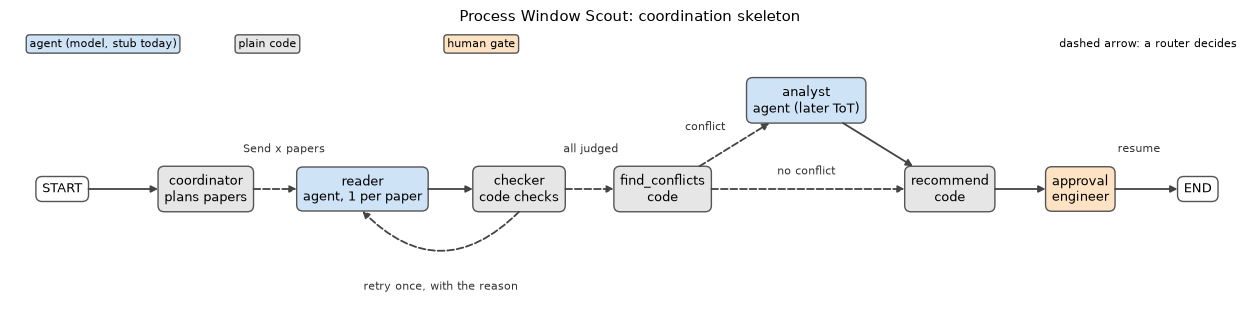

In [77]:
class ScoutState(TypedDict, total=False):
    request: dict                                          # from the engineer: alloy, layer thickness, target
    papers: list[str]                                      # Coordinator
    records: Annotated[list[dict], merge_records]          # evidence table: Reader, Checker, Analyst (own fields)
    conflicts: list[dict]                                  # Coordinator (code)
    explanations: list[dict]                               # Analyst
    recommendation: dict                                   # Coordinator (code)
    approval: dict                                         # engineer
    log: Annotated[list[dict], operator.add]               # every node appends its trace line


def send_readers(state: ScoutState) -> list[Send]:
    """Fan out: one Reader per paper, all in the same super-step."""
    return [Send("reader", {"paper_id": p, "attempt": 1}) for p in state["papers"]]


def route_after_check(state: ScoutState):
    """Failed records go back to their paper's Reader once, all of that paper's together, with the reasons.
    Otherwise move on to conflicts."""
    retry = [r for r in state["records"] if r["status"] == "retry"]
    if not retry:
        return "find_conflicts"
    by_paper = {}
    for r in retry:
        by_paper.setdefault(r["paper_id"], []).append(r)
    return [Send("reader", {"paper_id": pid, "attempt": max(r["attempt"] for r in rs) + 1,
                            "feedback": " | ".join(f"{r['id']}: {r['reason']}" for r in rs),
                            "retry_ids": [r["id"] for r in rs], "retry_records": rs})
            for pid, rs in by_paper.items()]


def route_after_conflicts(state: ScoutState) -> str:
    """Spend Analyst calls only when code found a conflict."""
    return "analyst" if state["conflicts"] else "recommend"


def build_scout_graph(reader_model, analyst_model, library, checkpointer=None, judge=None):
    g = StateGraph(ScoutState)
    g.add_node("coordinator", partial(coordinator_node, library=library))
    g.add_node("reader", partial(reader_node, model=reader_model, library=library))
    g.add_node("checker", partial(checker_node, library=library, judge=judge))
    g.add_node("find_conflicts", find_conflicts_node)
    g.add_node("analyst", partial(analyst_node, model=analyst_model))
    g.add_node("recommend", recommend_node)
    g.add_node("approval", approval_node)

    g.add_edge(START, "coordinator")
    g.add_conditional_edges("coordinator", send_readers, ["reader"])
    g.add_edge("reader", "checker")
    g.add_conditional_edges("checker", route_after_check, ["reader", "find_conflicts"])
    g.add_conditional_edges("find_conflicts", route_after_conflicts, ["analyst", "recommend"])
    g.add_edge("analyst", "recommend")
    g.add_edge("recommend", "approval")
    g.add_edge("approval", END)
    return g.compile(checkpointer=checkpointer)


# Drawing: positions and labels for this graph. Colours: agent (model), code, human.
KIND = {"coordinator": "code", "reader": "agent", "checker": "code", "find_conflicts": "code",
        "analyst": "agent", "recommend": "code", "approval": "human"}
SUBTITLE = {"coordinator": "plans papers", "reader": "agent, 1 per paper", "checker": "code checks",
            "find_conflicts": "code", "analyst": "agent (later ToT)", "recommend": "code", "approval": "engineer"}
COLOR = {"agent": "#cfe3f7", "code": "#e6e6e6", "human": "#fde2c4", "end": "#ffffff"}
POS = {"__start__": (0, 0), "coordinator": (2.2, 0), "reader": (4.6, 0), "checker": (7, 0), "find_conflicts": (9.2, 0),
       "analyst": (11.4, 1), "recommend": (13.6, 0), "approval": (15.6, 0), "__end__": (17.4, 0)}
EDGE_LABEL = {("coordinator", "reader"): ("Send x papers", 0, 0.45), ("checker", "reader"): ("retry once, with the reason", 0, -1.1),
              ("checker", "find_conflicts"): ("all judged", 0, 0.45), ("find_conflicts", "analyst"): ("conflict", -0.45, 0.2),
              ("find_conflicts", "recommend"): ("no conflict", 0, 0.2), ("approval", "__end__"): ("resume", 0, 0.45)}


def draw_graph(compiled, title="Process Window Scout: coordination skeleton"):
    """Draw the compiled graph from its own node and edge list. Dashed = conditional edge (a router decides)."""
    G = compiled.get_graph()
    fig, ax = plt.subplots(figsize=(16, 3.8))
    ax.set_xlim(-0.8, 18.2)
    ax.set_ylim(-1.5, 1.8)
    ax.axis("off")
    boxes = {}
    for n in G.nodes:
        name = {"__start__": "START", "__end__": "END"}.get(n, n)
        boxes[n] = ax.text(*POS[n], name + (f"\n{SUBTITLE[n]}" if n in SUBTITLE else ""), ha="center", va="center",
                           fontsize=9, bbox=dict(boxstyle="round,pad=0.5", fc=COLOR[KIND.get(n, "end")], ec="#555"))
    # Box sizes are known only after a first draw. Convert them to data units to end arrows at the box edges.
    fig.canvas.draw()
    to_data = ax.transData.inverted()
    half = {}
    for n, t in boxes.items():
        (xa, ya), (xb, yb) = to_data.transform(t.get_bbox_patch().get_window_extent(fig.canvas.get_renderer()))
        half[n] = ((xb - xa) / 2, (yb - ya) / 2)

    def border(n, toward):                                # where the line from n's centre to 'toward' leaves n's box
        (cx, cy), (hw, hh) = POS[n], half[n]
        dx, dy = toward[0] - cx, toward[1] - cy
        s = min(hw / abs(dx) if dx else float("inf"), hh / abs(dy) if dy else float("inf"))
        return cx + dx * s, cy + dy * s

    for e in G.edges:
        a, b = POS[e.source], POS[e.target]
        style = dict(arrowstyle="-|>", color="#444", lw=1.3, linestyle="--" if e.conditional else "-", shrinkA=0, shrinkB=0)
        if b[0] < a[0]:                                   # the retry loop runs backwards: an arc under the boxes
            start, end = (a[0], a[1] - half[e.source][1]), (b[0], b[1] - half[e.target][1])
            style["connectionstyle"] = "arc3,rad=-0.5"
        else:
            start, end = border(e.source, b), border(e.target, a)
        ax.annotate("", xy=end, xytext=start, arrowprops=style)
        if (e.source, e.target) in EDGE_LABEL:
            text, dx, dy = EDGE_LABEL[(e.source, e.target)]
            ax.text((a[0] + b[0]) / 2 + dx, (a[1] + b[1]) / 2 + dy, text, ha="center", va="center", fontsize=8, color="#333")
    for i, (k, lab) in enumerate([("agent", "agent (model, stub today)"), ("code", "plain code"), ("human", "human gate")]):
        ax.text(-0.5 + 3.2 * i, 1.6, lab, fontsize=8, bbox=dict(boxstyle="round", fc=COLOR[k], ec="#555"))
    ax.text(18, 1.6, "dashed arrow: a router decides", fontsize=8, ha="right")
    ax.set_title(title, fontsize=11)
    plt.show()


preview_graph = build_scout_graph(ScriptedModel("reader", READER_SCRIPT), ScriptedModel("analyst", ANALYST_SCRIPT),
                                  TEST_LIBRARY, checkpointer=InMemorySaver())
draw_graph(preview_graph)

In [78]:
# Tests for 8.6: the compiled graph has exactly the planned shape
G = preview_graph.get_graph()
edges = {(e.source, e.target, e.conditional) for e in G.edges}
check("seven nodes plus START and END", set(G.nodes) == set(POS))
check("fan out from the Coordinator to the Readers is conditional (Send)", ("coordinator", "reader", True) in edges)
check("the retry loop goes from the Checker back to the Reader", ("checker", "reader", True) in edges)
check("the Analyst is skipped when there is no conflict", ("find_conflicts", "recommend", True) in edges)
check("approval is the last node before END", ("approval", "__end__", False) in edges)

  ok  seven nodes plus START and END
  ok  fan out from the Coordinator to the Readers is conditional (Send)
  ok  the retry loop goes from the Checker back to the Reader
  ok  the Analyst is skipped when there is no conflict
  ok  approval is the last node before END


### 8.7 Run 1: five papers, one retry, one conflict

Now the whole graph runs on the five test papers. Three settings go into the run's **config**:

- `thread_id`: the name of this run in the checkpointer. A new id means a fresh evidence table. Reusing an old id
  would continue that run, old records included (a gotcha from the squad lab).
- `recursion_limit`: the most super-steps a run may take. It is the backstop if a router bug ever loops (8.10).
- `max_concurrency`: at most 3 Readers call the model at the same time, to be kind to the hosted endpoint.

`graph.stream(..., stream_mode="updates")` yields each node's update as soon as it finishes, so the trace
prints while the graph runs. Watch the **step** column: the five Readers share one super-step, T3 and T4 go back
to their Readers, and the run stops before approval.

In [79]:
def run_config(thread_id: str, recursion_limit: int = 25) -> dict:
    return {"configurable": {"thread_id": thread_id}, "recursion_limit": recursion_limit, "max_concurrency": 3}


def stream_run(graph, inputs, config):
    """Run (or resume) the graph and print each node's trace lines as they arrive."""
    for update in graph.stream(inputs, config, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                print("        PAUSED: waiting for the engineer (interrupt)")
            else:
                show_log((change or {}).get("log", []))


reader_1 = ScriptedModel("reader", READER_SCRIPT)
analyst_1 = ScriptedModel("analyst", ANALYST_SCRIPT)
memory = InMemorySaver()                                   # checkpointer: keeps every run's state in RAM
scout = build_scout_graph(reader_1, analyst_1, TEST_LIBRARY, checkpointer=memory)
cfg_1 = run_config("run-1")

stream_run(scout, {"request": REQUEST}, cfg_1)
state_1 = scout.get_state(cfg_1).values
print()
show_table(state_1["records"])

step  1 | coordinator           | 316L, 30 um, target 99.5 %: 5 papers to read


step  2 | reader         T3     | attempt 1: 1 record(s), rho = 99.1 %
step  2 | reader         T4     | attempt 1: 1 record(s), rho = 99.2 %
step  2 | reader         T5     | attempt 1: 1 record(s), rho = 99.6 %
step  2 | reader         T2     | attempt 1: 1 record(s), rho = 97.8 %
step  2 | reader         T1     | attempt 1: 1 record(s), rho = 99.9 %
step  3 | checker        T1     | verified
step  3 | checker        T2     | verified
step  3 | checker        T3     | retry: density_pct = 99.1 not in passage, nearest value 98.1
step  3 | checker        T4     | retry: power_W = 195 not in passage; speed_mm_s = 800 not in passage; hatch_um missing
step  3 | checker        T5     | verified
step  4 | reader         T3     | attempt 2: 1 record(s), rho = 98.1 %  (feedback: T3-r1: density_pct = 99.1 not in passage, nearest value 98.1)
step  4 | reader         T4     | attempt 2: 1 record(s), rho = 99.2 %  (feedback: T4-r1: power_W = 195 not in passage; speed_mm_s = 800 not in passage; ha

**The run as a timeline.** One row per agent (one per Reader), one column per super-step. Readers in the same
column ran in parallel. The second marks on T3 and T4 are the retries. Colours show the Checker's verdict.

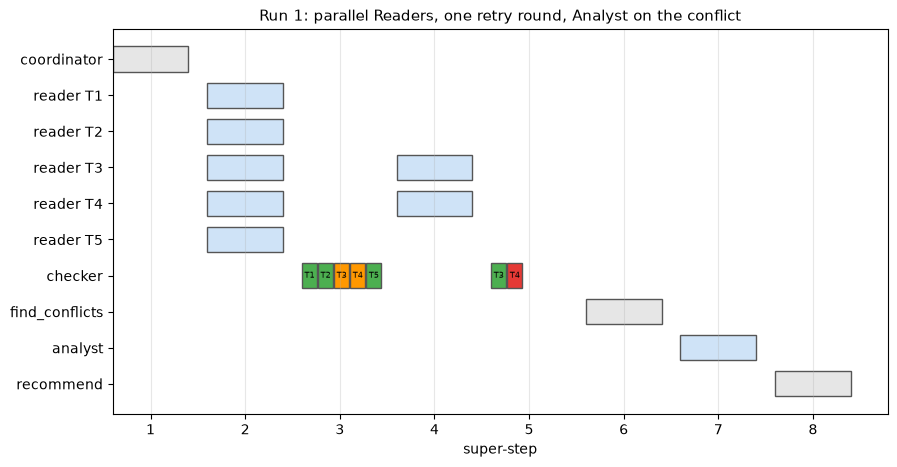

In [80]:
VERDICT_COLOR = {"verified": "#4caf50", "retry": "#ff9800", "not verified": "#e53935"}


def plot_timeline(log, title):
    """Gantt-style view of the trace: which node ran in which super-step."""
    rows, marks = [], []
    for e in log:
        if e["step"] == "-":
            continue
        row = f"reader {e['subject']}" if e["node"] == "reader" else e["node"]
        if row not in rows:
            rows.append(row)
        colour = "#cfe3f7" if e["node"] in ("reader", "analyst") else "#fde2c4" if e["node"] == "approval" else "#e6e6e6"
        if e["node"] == "checker":
            colour = VERDICT_COLOR.get(e["msg"].split(":")[0], "#e6e6e6")
        marks.append((e["step"], row, colour, e["subject"] if e["node"] == "checker" else ""))
    rows.sort(key=lambda rw: (min(s for s, r, *_ in marks if r == rw), rw))
    y = {rw: i for i, rw in enumerate(rows)}
    fig, ax = plt.subplots(figsize=(10, 0.38 * len(rows) + 1.2))
    seen = {}
    for step, row, colour, label in marks:
        k = seen.get((step, row), 0)
        seen[(step, row)] = k + 1
        if row == "checker":                               # several verdicts per Checker step: small stacked boxes
            ax.barh(y[row], 0.16, left=step - 0.4 + 0.17 * k, color=colour, edgecolor="#555", height=0.7)
            ax.text(step - 0.32 + 0.17 * k, y[row], label, ha="center", va="center", fontsize=6)
        elif k == 0:
            ax.barh(y[row], 0.8, left=step - 0.4, color=colour, edgecolor="#555", height=0.7)
    ax.set_yticks(range(len(rows)), rows)
    ax.invert_yaxis()
    steps = sorted({s for s, *_ in marks})
    ax.set_xticks(steps)
    ax.set_xlabel("super-step")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", alpha=0.3)
    plt.show()


plot_timeline(state_1["log"], "Run 1: parallel Readers, one retry round, Analyst on the conflict")

In [81]:
# Tests for 8.7
by_id = {r["id"]: r for r in state_1["records"]}
first_round = [e["step"] for e in state_1["log"] if e["node"] == "reader" and e["msg"].startswith("attempt 1")]
check("five Readers ran, all in the same super-step (parallel)", len(first_round) == 5 and len(set(first_round)) == 1)
check("the evidence table has one record per paper (retries updated, not duplicated)", len(state_1["records"]) == 5)
check("T3 was verified on the retry with the corrected density",
      by_id["T3-r1"]["status"] == "verified" and by_id["T3-r1"]["attempt"] == 2 and by_id["T3-r1"]["density_pct"] == 98.1)
check("T3's second Reader call received the Checker's reason",
      "nearest value 98.1" in [c for c in reader_1.calls if c["key"] == "T3" and c["attempt"] == 2][0]["feedback"])
check("T4 was tried exactly twice and ended 'not verified'",
      by_id["T4-r1"]["status"] == "not verified" and sum(c["key"] == "T4" for c in reader_1.calls) == 2)
check("Reader model calls = 5 papers + 2 retries", len(reader_1.calls) == 7)
check("the Analyst ran once, on the T1 vs T3 conflict",
      [c["key"] for c in analyst_1.calls] == ["T1-r1|T3-r1"] and "Archimedes" in by_id["T1-r1"]["analyst_note"])
check("the window cites T1 and T5 and excludes T4",
      state_1["recommendation"]["cites"] == ["T1-r1", "T5-r1"] and state_1["recommendation"]["excluded"] == ["T4-r1"])
check("the run is paused at approval (no decision yet)", "approval" not in state_1)

  ok  five Readers ran, all in the same super-step (parallel)
  ok  the evidence table has one record per paper (retries updated, not duplicated)
  ok  T3 was verified on the retry with the corrected density
  ok  T3's second Reader call received the Checker's reason
  ok  T4 was tried exactly twice and ended 'not verified'
  ok  Reader model calls = 5 papers + 2 retries
  ok  the Analyst ran once, on the T1 vs T3 conflict
  ok  the window cites T1 and T5 and excludes T4
  ok  the run is paused at approval (no decision yet)


### 8.8 The human gate: inspect the paused run, then resume it

The graph stopped inside `approval_node` at `interrupt(...)`. Nothing is lost, because the **checkpointer** saved
the state after every super-step under `thread_id = "run-1"`. Run 1 could be resumed from another cell, after a
coffee, or (with the SQLite checkpointer planned for later) after restarting the notebook.

- `graph.get_state(config)` shows the saved state, `.next` (the node waiting to run) and the question that
  `interrupt` handed out.
- `graph.stream(Command(resume=answer), config)` continues the same thread. LangGraph runs `approval_node` again
  from its start, and this time `interrupt(...)` returns the engineer's answer instead of pausing.
- `graph.get_state_history(config)` lists every saved checkpoint, one per super-step. This is the audit trail
  (and it also allows "time travel": rerunning from an earlier checkpoint).

In the real tool the engineer would read the window and the citations first. Here the answer is written in code.

In [82]:
paused = scout.get_state(cfg_1)
question = paused.tasks[0].interrupts[0].value
print("Waiting to run :", paused.next)
print("Question       :", question["question"])
for k, v in question["recommendation"].items():
    print(f"  {k:<11}: {v}")

Waiting to run : ('approval',)
Question       : Approve this process window?
  status     : proposed
  power_W    : [170, 190]
  speed_mm_s : [700, 750]
  hatch_um   : [90, 100]
  layer_um   : 30
  cites      : ['T1-r1', 'T5-r1']
  excluded   : ['T4-r1']


In [83]:
stream_run(scout, Command(resume={"approved": True, "note": "start at the middle, 180 W and 725 mm/s"}), cfg_1)
final_1 = scout.get_state(cfg_1)
print("\nWaiting to run :", final_1.next or "nothing, the run is finished")
print("Approval       :", final_1.values["approval"])

print("\nCheckpoints of run-1 (newest first):")
for snap in scout.get_state_history(cfg_1):
    print(f"  after step {snap.metadata['step']:>2}: next = {snap.next}")

step  9 | approval              | engineer approved: start at the middle, 180 W and 725 mm/s

Waiting to run : nothing, the run is finished
Approval       : {'approved': True, 'note': 'start at the middle, 180 W and 725 mm/s'}

Checkpoints of run-1 (newest first):
  after step  9: next = ()
  after step  8: next = ('approval',)
  after step  7: next = ('recommend',)
  after step  6: next = ('analyst',)
  after step  5: next = ('find_conflicts',)
  after step  4: next = ('checker',)
  after step  3: next = ('reader', 'reader')
  after step  2: next = ('checker',)
  after step  1: next = ('reader', 'reader', 'reader', 'reader', 'reader')
  after step  0: next = ('coordinator',)
  after step -1: next = ('__start__',)


In [84]:
# Tests for 8.8
check("before resuming, the graph was waiting at 'approval'", paused.next == ("approval",))
check("the engineer saw the window and its citations", question["recommendation"]["cites"] == ["T1-r1", "T5-r1"])
check("after resuming, the run is finished", final_1.next == ())
check("the approval is stored in the state", final_1.values["approval"]["approved"] is True)
check("resuming did not call the Reader again (state came from the checkpoint)", len(reader_1.calls) == 7)
history = list(scout.get_state_history(cfg_1))
check("one checkpoint per super-step was saved", len(history) >= 10)

  ok  before resuming, the graph was waiting at 'approval'
  ok  the engineer saw the window and its citations
  ok  after resuming, the run is finished
  ok  the approval is stored in the state
  ok  resuming did not call the Reader again (state came from the checkpoint)
  ok  one checkpoint per super-step was saved


### 8.9 Run 2: a different path through the same graph

Same graph, new thread, only the three papers that agree (T1, T2, T5). Now the Checker passes everything at once,
`find_conflicts` finds nothing, so the router skips the Analyst and **no Analyst call is spent**. This time the
engineer rejects the window. The rejection is stored with its note, ready for the feedback memory planned in M6.

step  1 | coordinator           | 316L, 30 um, target 99.5 %: 3 papers to read


step  2 | reader         T5     | attempt 1: 1 record(s), rho = 99.6 %


step  2 | reader         T2     | attempt 1: 1 record(s), rho = 97.8 %
step  2 | reader         T1     | attempt 1: 1 record(s), rho = 99.9 %
step  3 | checker        T1     | verified
step  3 | checker        T2     | verified
step  3 | checker        T5     | verified
step  4 | find_conflicts        | 3 verified records compared, 0 conflict(s)
step  5 | recommend             | proposed: P 170 to 190 W, v 700 to 750 mm/s from ['T1-r1', 'T5-r1']
        PAUSED: waiting for the engineer (interrupt)
step  6 | approval              | engineer rejected: our machine tops out at 180 W


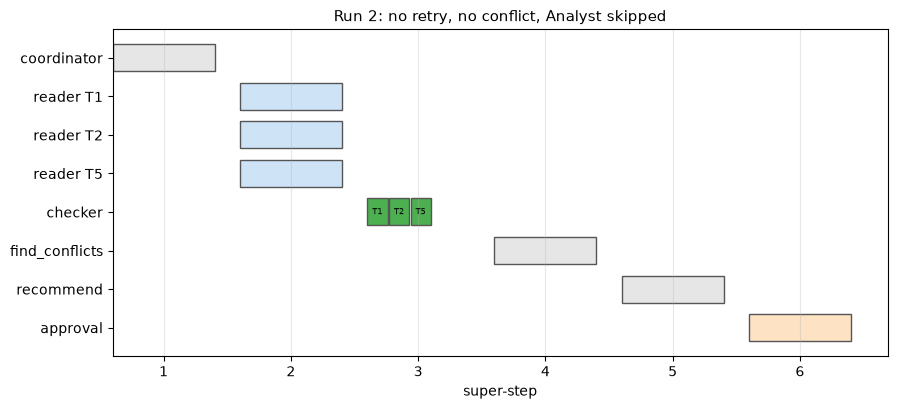

In [85]:
agreeing = {p: TEST_LIBRARY[p] for p in ["T1", "T2", "T5"]}
reader_2 = ScriptedModel("reader", READER_SCRIPT)
analyst_2 = ScriptedModel("analyst", ANALYST_SCRIPT)
scout_2 = build_scout_graph(reader_2, analyst_2, agreeing, checkpointer=InMemorySaver())
cfg_2 = run_config("run-2")

stream_run(scout_2, {"request": REQUEST}, cfg_2)
stream_run(scout_2, Command(resume={"approved": False, "note": "our machine tops out at 180 W"}), cfg_2)
state_2 = scout_2.get_state(cfg_2).values
plot_timeline(state_2["log"], "Run 2: no retry, no conflict, Analyst skipped")

In [86]:
# Tests for 8.9
nodes_2 = [e["node"] for e in state_2["log"]]
check("the Analyst was skipped and never called", "analyst" not in nodes_2 and analyst_2.calls == [])
check("no retries: three Reader calls for three papers", len(reader_2.calls) == 3)
check("node order: coordinator, readers, checker, find_conflicts, recommend, approval",
      [n for i, n in enumerate(nodes_2) if i == 0 or n != nodes_2[i - 1]]
      == ["coordinator", "reader", "checker", "find_conflicts", "recommend", "approval"])
check("the rejection and its note are stored",
      state_2["approval"] == {"approved": False, "note": "our machine tops out at 180 W"})
check("run-1 is untouched by run-2 (separate threads)", scout.get_state(cfg_1).values["approval"]["approved"] is True)

  ok  the Analyst was skipped and never called
  ok  no retries: three Reader calls for three papers
  ok  node order: coordinator, readers, checker, find_conflicts, recommend, approval
  ok  the rejection and its note are stored
  ok  run-1 is untouched by run-2 (separate threads)


### 8.10 Safety brakes: the retry cap and the recursion limit

Loops are where multi-agent systems burn money. This skeleton has two brakes:

1. **The retry cap** (`MAX_ATTEMPTS = 2`) is the designed brake. It is part of the Checker's rule, so a Reader that
   is always wrong (T4 in run 1) costs exactly two calls and ends as "not verified".
2. **`recursion_limit`** is the backstop for bugs. If I ever break a router so that it loops forever, LangGraph
   stops the run after that many super-steps with a `GraphRecursionError`. Run 1 needs 8 super-steps to reach the
   pause, so a limit of 6 must stop it. The default in this LangGraph version is above 10,000, which is why
   `run_config` always sets it.

In [87]:
reader_3 = ScriptedModel("reader", READER_SCRIPT)
scout_3 = build_scout_graph(reader_3, ScriptedModel("analyst", ANALYST_SCRIPT), TEST_LIBRARY, checkpointer=InMemorySaver())
try:
    stream_run(scout_3, {"request": REQUEST}, run_config("run-3", recursion_limit=6))
    stopped = None
except GraphRecursionError as e:
    stopped = e
    print("\nStopped by the backstop ->", type(e).__name__, ":", str(e).splitlines()[0])
steps_run_1 = max(e["step"] for e in state_1["log"] if e["node"] != "approval")
print("Super-steps run 1 needed before the pause:", steps_run_1)

step  1 | coordinator           | 316L, 30 um, target 99.5 %: 5 papers to read


step  2 | reader         T3     | attempt 1: 1 record(s), rho = 99.1 %
step  2 | reader         T1     | attempt 1: 1 record(s), rho = 99.9 %
step  2 | reader         T4     | attempt 1: 1 record(s), rho = 99.2 %
step  2 | reader         T5     | attempt 1: 1 record(s), rho = 99.6 %
step  2 | reader         T2     | attempt 1: 1 record(s), rho = 97.8 %
step  3 | checker        T1     | verified
step  3 | checker        T2     | verified
step  3 | checker        T3     | retry: density_pct = 99.1 not in passage, nearest value 98.1
step  3 | checker        T4     | retry: power_W = 195 not in passage; speed_mm_s = 800 not in passage; hatch_um missing
step  3 | checker        T5     | verified


step  4 | reader         T3     | attempt 2: 1 record(s), rho = 98.1 %  (feedback: T3-r1: density_pct = 99.1 not in passage, nearest value 98.1)
step  4 | reader         T4     | attempt 2: 1 record(s), rho = 99.2 %  (feedback: T4-r1: power_W = 195 not in passage; speed_mm_s = 800 not in passage; hatch_um missing)
step  5 | checker        T3     | verified
step  5 | checker        T4     | not verified: power_W = 195 not in passage; speed_mm_s = 800 not in passage; hatch_um missing
step  6 | find_conflicts        | 4 verified records compared, 1 conflict(s); T1-r1 vs T3-r1: [93.8, 92.6] J/mm3, [99.9, 98.1] %

Stopped by the backstop -> GraphRecursionError : Recursion limit of 6 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
Super-steps run 1 needed before the pause: 8


In [88]:
# Tests for 8.10
check("a too small recursion_limit stops the run with GraphRecursionError", isinstance(stopped, GraphRecursionError))
check("run 1 fits comfortably inside the limit of 25", steps_run_1 < 25)
check("the always wrong Reader (T4) cost exactly MAX_ATTEMPTS calls in run 1",
      sum(c["key"] == "T4" for c in reader_1.calls) == MAX_ATTEMPTS)

  ok  a too small recursion_limit stops the run with GraphRecursionError
  ok  run 1 fits comfortably inside the limit of 25
  ok  the always wrong Reader (T4) cost exactly MAX_ATTEMPTS calls in run 1


### 8.11 The real Reader and Checker in the graph

The skeleton was built so that the agents could be swapped in without rewiring. Here that happens:

- **Reader:** `GLMReader` is a thin adapter around Part 5's Reader chain with the same `invoke()` as `ScriptedModel`,
  passed to `build_scout_graph` as `reader_model`. A paper now yields many records. If the Checker rejects some, only
  that paper's Reader runs again, once, for the rejected records only, with the Checker's reasons
  (`route_after_check` groups the retries by paper).
- **Checker:** the node gets `judge=check_record`, the code checks of Part 6.
- **Analyst:** not built yet. `PendingAnalyst` stands in **without any model call**, so conflicts are only reported.
- **Library:** the ten 316L papers of the frozen library (the alloy filter would keep the distractor out anyway).

The request is the skeleton's: 316L, 30 µm layers, target 99.5 %. The run stops at the approval pause, where the
engineer would see the window, the records that were excluded and the conflicts. The conflict rule (energy density
within 10 %, density gap above 1 point) is still the provisional one from 8.5. Which pairs it flags here is input for
my decision on the comparability rule.

The first-attempt Reader calls are the same prompts as in 5.2, so they come from the cache. Only the retries are new.

In [89]:
class GLMReader:
    """The real Reader (Part 5) with the same invoke() as ScriptedModel, so build_scout_graph needs no change."""

    def __init__(self):
        self.calls = []

    def invoke(self, paper_id, attempt=1, retry_records=None, **_):
        self.calls.append({"paper_id": paper_id, "attempt": attempt})
        if attempt == 1:     # the paper's reading units with the same prompts as in 5.2, so the answers come from the cache
            calls = [(reader_inputs(paper_id, unit), f"reader {SHORT[paper_id]} {unit['name']}") for unit in reading_units(paper_id)]
        else:                # one call for the records the Checker sent back, with its reasons
            calls = [(reader_inputs(paper_id, retry_records=retry_records), f"reader {SHORT[paper_id]} retry")]
        outs = [reader_chain.invoke(inputs, config={"metadata": {"agent": name}}) for inputs, name in calls]
        return merge_units(paper_id, outs)


class PendingAnalyst:
    """Stands in for the Analyst until the Tree of Thought is built: no model call, the conflict is only recorded."""

    def __init__(self):
        self.calls = []

    def invoke(self, key, **context):
        self.calls.append(key)
        return {"explanation": "not analysed yet (the Analyst comes with the Tree of Thought)", "favoured": "-", "tier": "-"}


REAL_LIBRARY = {pid: LIB_META[pid] for pid in SOURCE_IDS}
real_reader, pending_analyst = GLMReader(), PendingAnalyst()
real_graph = build_scout_graph(real_reader, pending_analyst, REAL_LIBRARY, checkpointer=InMemorySaver(), judge=check_record)
cfg_real = run_config("real-run-1")


def run_real():
    """Stream the real run. The Checker writes one log line per record, so its lines are summarised per step."""
    TRACER.start("graph_real_run")
    t0 = time.time()
    for update in real_graph.stream({"request": REQUEST}, cfg_real, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                print("        PAUSED: waiting for the engineer (interrupt)")
                continue
            entries = (change or {}).get("log", [])
            if node == "checker" and entries:
                verdicts = [e["msg"].split(":")[0] for e in entries]
                print(f"step {entries[0]['step']!s:>2} | checker        {len(entries)} records | "
                      + ", ".join(f"{s}: {verdicts.count(s)}" for s in sorted(set(verdicts))))
            for e in entries if node != "checker" else []:
                print(f"step {e['step']!s:>2} | {e['node']:<14} {SHORT.get(e['subject'], e['subject']):<4} | {e['msg'][:140]}")
    return time.time() - t0


real_seconds = model_cell(run_real)

step  1 | coordinator         | 316L, 30 um, target 99.5 %: 10 papers to read


--- [reader L04 text] from cache: 30.3 s, 2292 in / 4585 out tokens (3638 reasoning) ---
reasoning (2292 words): Let me analyze the passages to find measured density or porosity values.

From [PMC12387571-017], the text reports:
- "The minimum porosity of approximately 0.04% occurred at 190 W and 700 to 800 mm/s"
- "the maximum porosity of about 2% appeared at 140 W and 900 mm/s"

These are measured porosity values from the study's own contour plots. The minimum porosity is at 190 W with scanning speeds of 700-800 mm/s (two possible parameter sets), and the maximum is at 140 W and 900 mm/s.

Looking at Table 4 [PMC12387571-070], the parameter sets are:
- 190 W, 700 mm/s, 100.53 J/mm3
- 190 W, 800 mm/s, 87.96 J/mm3
- 140 W, 900 mm/s, 57.61 J/mm3

For the minimum porosity of ~0.04%, the text says it occurred at 190 W and 700 to 800 mm/s. This is a range, so I should note that.

For the maximum porosity of ~2%, it's at 140 W and 900 mm/s.

The layer thickness, hatch spacing, and spot size

step  2 | reader         L04  | attempt 1: 4 record(s)


--- [reader L06 Table 2] from cache: 22.61 s, 1924 in / 4930 out tokens (1050 reasoning) ---
reasoning (457 words): Let me analyze the focus passage [PMC11818529-023], which is Table 2. This table contains porosity values measured by two methods: Archimedes method and Image Analysis.

I need to create records for each sample and each measurement method, since the rules say "If a sample has values from two methods, write one record for each."

Let me extract the parameters:

From [PMC11818529-004]: Hatch spacing = 60 µm, Layer thickness = 30 µm (constant for all samples)

Table 2 data:
- S1: Power=120W, Speed=700mm/s, Archimedes Porosity=4.3±0.5%, Image Analysis Porosity=1.16%, Shape Factor=1.12
- S2: Power=120W, Speed=900mm/s, Archimedes Porosity=6.5±0.1%, Image Analysis Porosity=1.21%, Shape Factor=3.15
- S3: Power=120W, Speed=1100mm/s, Archimedes Porosity=9.1±1.2%, Image Analysis Porosity=3.02%, Shape Factor=2.63
- S4: Power=150W, Speed=700mm/s, Archimedes Porosity=3.4±0.4%, Image An

--- [reader L03 Table 2] from cache: 8.61 s, 1634 in / 1670 out tokens (420 reasoning) ---
reasoning (177 words): Let me analyze the focus table [PMC13208960-029] which is Table 2. It contains measured density values for SLM SS316 specimens. I need to extract all six rows as records.

From the table:
- Layer thickness: 30 μm (from [PMC13208960-010])
- Hatch spacing: 120 μm (from [PMC13208960-010])
- Spot size/beam size: 200 μm (from [PMC13208960-010])

The table has:
1. SLM (100/100): Power=100W, Speed=100 mm/s, LED=278 J/mm³, Density=96.93%
2. SLM (100/1000): Power=100W, Speed=1000 mm/s, LED=28 J/mm³, Density=95.55%
3. SLM (140/100): Power=140W, Speed=100 mm/s, LED=389 J/mm³, Density=97.76%
4. SLM (140/1000): Power=140W, Speed=1000 mm/s, LED=39 J/mm³, Density=96.78%
5. SLM (180/100): Power=180W, Speed=100 mm/s, LED=500 J/mm³, Density=95.94%
6. SLM (180/1000): Power=180W, Speed=1000 mm/s, LED=50 J/mm³, Density=93.79%

The material is SS316L (also called SS316, 316L). The process is SLM

--- [reader L07 Table 3] from cache: 7.76 s, 1750 in / 1515 out tokens (690 reasoning) ---
reasoning (351 words): Let me analyze the focus passage [PMC8510493-031] which is Table 3, containing density measurements for AMed and wrought AISI 316L.

From Table 3, I can extract three AMed specimens with their density values:

1. VED 50.8 J/mm3 → Density 91.9%
2. VED 79.4 J/mm3 → Density 94.6%
3. VED 84.3 J/mm3 → Density 99.6%

The wrought row (100%) is not PBF-LB, so I should exclude it.

From Table 2 [PMC8510493-030], I can get the fabrication parameters for each:

1. low-VED: VED 50.8 J/mm3, Laser Power 160 W, Scan Speed 875 mm/s, Hatch Spacing 120 µm, Layer Thickness 30 µm
2. medium-VED: VED 79.4 J/mm3, Laser Power 190 W, Scan Speed 800 mm/s, Hatch Spacing 100 µm, Layer Thickness 30 µm
3. high-VED: VED 84.3 J/mm3, Laser Power 220 W, Scan Speed 725 mm/s, Hatch Spacing 120 µm, Layer Thickness 30 µm

The density is measured relative density in %, as stated in the methods [PMC8510493-007]: 

--- [reader L05 Table 1] from cache: 2.29 s, 5467 in / 257 out tokens (250 reasoning) ---
reasoning (168 words): The focus is on records whose density or porosity values are printed in [PMC12194911-099].

Let me examine chunk [PMC12194911-099], which is Table 1 - a comparative analysis of additive manufacturing processes by advantages, disadvantages, and industrial preference.

Looking at this table, it describes various AM processes (DED, SLM, EBM, FDM, SLA/DLP, Binder Jetting, Material Jetting, Sheet Lamination) with their advantages, disadvantages, and why they are preferred. 

There are no specific process parameters (laser power, scan speed, hatch spacing, etc.) and no measured density or porosity values in this table. It's a qualitative comparison table.

The table mentions things like "Produces fully dense, high-strength metal parts" for SLM, and "Results in lower-density parts" for Binder Jetting, but these are qualitative descriptions, not measured density or porosity values.


--- [reader L09 Table 1] from cache: 14.27 s, 2979 in / 2479 out tokens (1834 reasoning) ---
reasoning (1136 words): Let me analyze the focus: records whose density or porosity values are printed in [PMC8880558-020].

Looking at [PMC8880558-020], which is Table 1 - a summary of bibliographic results related to corrosion behavior of 316L manufactured by SLM. This is a literature summary table, so origin should be "quoted" for all records.

Let me identify rows with density or porosity values:

- Ref [20]: Relative Density = "-" → no value
- Ref [21]: Relative Density = "99.4%–99.6%" → has value, but scanning speed and hatch spacing are missing
- Ref [22]: Relative Density = "-" → no value
- Ref [23]: Relative Density = "-" → no value
- Ref [24]: Relative Density = "-" → no value
- Ref [25]: Relative Density = "-" → no value
- Ref [26]: Relative Density = "-" → no value
- Ref [27]: Relative Density = "-" → no value
- Ref [28]: Relative Density = "-" → no value
- Ref [29]: Relative Densit

--- [reader L08 Table 2] from cache: 1283.97 s, 3726 in / 16776 out tokens (8656 reasoning) ---
reasoning (5025 words): Let me analyze the focus table [PMC7579382-039] which is Table 2, containing density measurements and porosity levels for samples after SLM.

The table contains:
- ρpycno: density in g/cm³ (this is the measured density, not relative density in %)
- Vpycno: volume in cm³
- Pclosed: closed porosity in %
- Pimage: porosity from image analysis in %

I need to extract records for density or porosity values. The table reports porosity values (Pclosed and Pimage) in %. These are porosity measurements, not relative density in %. 

The density column ρpycno is in g/cm³, which is the absolute density of the printed parts, not relative density in %. The rules say "Density means the measured relative density of printed parts in %, or their porosity in %". The density here is in g/cm³, not in %, so it's not the quantity I should record as "density". However, the porosity values (P

--- [reader L08 retry] from cache: 25.42 s, 4977 in / 5727 out tokens (1006 reasoning) ---
reasoning (544 words): The checker rejected all records because layer_um = 50000 is outside the typical PBF-LB range of 10 to 150 µm. The paper states layer thickness is 50 µm, which should be 50 µm = 50, not 50000. The issue is that 50 µm was converted to 50000 nm or something, but the field expects micrometers. So layer_um should be 50, not 50000.

Let me check: the passage says "layer thickness (50 µm)" - so layer_um = 50.

Similarly, hatch distance is 0.11 mm = 110 µm, and spot diameter is 70 µm.

The checker said layer_um = 50000, which would be 50 mm converted to µm = 50000 µm. That's wrong. The paper says 50 µm, so layer_um = 50.

Let me also check hatch_spacing: 0.11 mm. Should I convert to µm? The field name is hatch_spacing_mm probably, or it could be in mm. Let me think about what fields are expected.

Looking at the rejected records, they have hatch 0.11, layer 50, spot 70. The checke

In [90]:
if real_seconds is not None:
    state_real = real_graph.get_state(cfg_real).values
    recs_real = state_real["records"]
    print(f"Run time {real_seconds:.0f} s. Records: {len(recs_real)}\n")
    STATUSES = ["verified", "quoted", "incomplete", "no density", "other process", "not verified"]
    rows = []
    for pid in SOURCE_IDS:
        mine = [r for r in recs_real if r["paper_id"] == pid]
        rows.append({"paper": f"{SHORT[pid]} {pid}", "records": len(mine), "retried": sum(r["attempt"] > 1 for r in mine),
                     **{s: sum(r["status"] == s for r in mine) for s in STATUSES}})
    print_rows(rows, [("paper", "paper", 16), ("records", "records", 7), ("retried", "retried", 7),
                      *[(s, s, max(len(s), 6)) for s in STATUSES]])

    print("\nRecords sent back to the Reader, and what happened:")
    print_rows([r for r in recs_real if r["attempt"] > 1],
               [("id", "record", 16), ("sample_label", "sample", 10), ("status", "final status", 12), ("reason", "reason", 100)])

    rec_window = state_real["recommendation"]
    print(f"\nWindow ({rec_window['status']}): P {rec_window.get('power_W')} W, v {rec_window.get('speed_mm_s')} mm/s, "
          f"h {rec_window.get('hatch_um')} µm at {REQUEST['layer_um']} µm, from {len(rec_window['cites'])} verified records; "
          f"{len(rec_window['excluded'])} records 'not verified' kept out")

Run time 2 s. Records: 190

paper             records  retried  verified  quoted  incomplete  no density  other process  not verified
----------------  -------  -------  --------  ------  ----------  ----------  -------------  ------------
L01 PMC13073740   1        0        0         0       0           1           0              0           
L02 PMC12735063   27       0        27        0       0           0           0              0           
L03 PMC13208960   6        0        6         0       0           0           0              0           
L04 PMC12387571   4        0        3         0       1           0           0              0           
L05 PMC12194911   1        0        0         0       0           0           1              0           
L06 PMC11818529   18       0        18        0       0           0           0              0           
L07 PMC8510493    3        3        3         0       0           0           0              0           
L08 PMC7579382    

**Conflicts flagged by the provisional rule.** Every pair of verified 30 µm records whose energy densities are within
10 % but whose densities differ by more than 1 point. Only the first three would go to the Analyst (`MAX_CONFLICTS`),
and here the Analyst is a stand-in. The list is the evidence for choosing the comparability rule: pairs inside one paper
(two density methods on the same sample) are a different question from pairs across papers.

In [91]:
if real_seconds is not None:
    by_id = {r["id"]: r for r in recs_real}
    n_cmp, all_pairs = comparable_conflicts(recs_real, REQUEST["layer_um"])

    def describe(r):
        return f"{SHORT[r['paper_id']]} {r['sample_label'] or ''} {r['power_W']:g} W {r['speed_mm_s']:g} mm/s h{r['hatch_um']:g}"

    pair_rows = [{"a": describe(by_id[c["ids"][0]]), "b": describe(by_id[c["ids"][1]]),
                  "same paper": "yes" if by_id[c["ids"][0]]["paper_id"] == by_id[c["ids"][1]]["paper_id"] else "no",
                  "ved": f"{c['ved_J_mm3'][0]} / {c['ved_J_mm3'][1]}", "rho": f"{c['density_pct'][0]:g} / {c['density_pct'][1]:g}",
                  "methods": f"{by_id[c['ids'][0]]['density_method']} / {by_id[c['ids'][1]]['density_method']}"} for c in all_pairs]
    print(f"{n_cmp} verified records at {REQUEST['layer_um']} µm compared, {len(all_pairs)} pairs flagged "
          f"({sum(p['same paper'] == 'no' for p in pair_rows)} across papers)\n")
    print_rows(sorted(pair_rows, key=lambda p: p["same paper"]),
               [("a", "record A", 30), ("b", "record B", 30), ("same paper", "same paper", 10), ("ved", "E_v J/mm3", 13),
                ("rho", "density %", 13), ("methods", "methods", 45)])
    print("\nSent to the (stand-in) Analyst:", [" vs ".join(SHORT[by_id[i]["paper_id"]] for i in c["ids"]) for c in state_real["conflicts"]])
    save_records(recs_real, EXTRACTION / "graph_run_records.csv", extra=["attempt", "status", "reason"])

39 verified records at 30 µm compared, 70 pairs flagged (48 across papers)

record A                        record B                        same paper  E_v J/mm3      density %      methods                                      
------------------------------  ------------------------------  ----------  -------------  -------------  ---------------------------------------------
L06 S1 120 W 700 mm/s h60       L04  190 W 700 mm/s h90         no          95.2 / 100.5   95.7 / 99.96   Archimedes / None                            
L06 S1 120 W 700 mm/s h60       L04  190 W 800 mm/s h90         no          95.2 / 88.0    95.7 / 99.96   Archimedes / None                            
L06 S1 120 W 700 mm/s h60       L02 8 (rep 1) 250 W 600 mm/...  no          95.2 / 92.6    95.7 / 98.39   Archimedes / None                            
L06 S1 120 W 700 mm/s h60       L02 8 (rep 2) 250 W 600 mm/...  no          95.2 / 92.6    95.7 / 98.67   Archimedes / None                            
L06 S1 120 W

In [92]:
show_trace("graph_real_run")

Trace 'graph_real_run': 28 model calls
#    agent / node            source  s       tok in  tok out  reason  answer or tool call                                         
---  ----------------------  ------  ------  ------  -------  ------  ------------------------------------------------------------
1    reader L04 text         cache   30.3    2292    4585     3638    {"records":[   {     "record_id": null,     "sample_label...
2    reader L06 Table 2      cache   22.61   1924    4930     1050    {"records": [   {     "record_id": null,     "sample_labe...
3    reader L06 Table 3      cache   1.6     2173    186      179     {"records": []}                                             
4    reader L06 Table 5      cache   2.03    2086    304      296     { "records": [] }                                           
5    reader L02 Table 1      cache   2.7     3249    203      196     {"records": []}                                             
6    reader L02 Table 4      cache   94.45  

In [93]:
# Tests for 8.11
if real_seconds is not None:
    trace_real = load_trace("graph_real_run")
    retried_papers = {r["paper_id"] for r in recs_real if r["attempt"] > 1}
    check("the run is paused at the approval node", real_graph.get_state(cfg_real).next == ("approval",))
    check("every record has been judged (none left waiting or in retry)",
          not any(r["status"] in ("extracted", "retry") for r in recs_real))
    check("'not verified' only after the one retry", all(r["attempt"] == MAX_ATTEMPTS for r in recs_real if r["status"] == "not verified"))
    check("Reader calls = 10 papers + one retry per paper with rejected records",
          len(real_reader.calls) == len(SOURCE_IDS) + len(retried_papers))
    check("first attempts were replayed from the cache (same prompts as 5.2)",
          all(t["cached"] for t in trace_real if not t["agent"].endswith("retry")))
    check("no Analyst model call: every traced call is a Reader call", all(t["agent"].startswith("reader") for t in trace_real))
    check("the window cites only verified records", all(by_id[i]["status"] == "verified" for i in rec_window["cites"]))
    check("verified records passed every check",
          all(r["checks"]["11 verbatim"] == "pass" and r["checks"]["14 ranges"] == "pass" and r["checks"]["14 energy"] != "fail"
              for r in recs_real if r["status"] == "verified"))

  ok  the run is paused at the approval node
  ok  every record has been judged (none left waiting or in retry)
  ok  'not verified' only after the one retry
  ok  Reader calls = 10 papers + one retry per paper with rejected records
  ok  first attempts were replayed from the cache (same prompts as 5.2)
  ok  no Analyst model call: every traced call is a Reader call
  ok  the window cites only verified records
  ok  verified records passed every check


### Part 8 summary

- A LangGraph `StateGraph` with the Checkpoint 5.1 roles: Coordinator in code, parallel Readers via `Send`, a code
  Checker with **one retry then "not verified"**, conflict routing to the Analyst, and an approval `interrupt` saved by
  a checkpointer.
- One shared evidence table with an upsert reducer (`merge_records`) and per-agent field ownership (`write`).
- Tested offline with scripted fake models on made-up papers T1 to T5: parallel super-step, retry with feedback, cap,
  conflict path, skip path, pause and resume, rejection, recursion backstop (8.1 to 8.10).
- The real Reader and Checker plugged in without rewiring (8.11): the real library runs to the approval pause, and
  retries go back per paper for the rejected records only. The Analyst is still a stand-in with no model call.

**Next:** Part 9 makes the pause survive a restart and adds the clarification step and the engineer's memory.


## Part 9. When must a human decide? (guardrails and memory)

- **Question:** When does the agent stop and ask, and what does it remember from the engineer?
- **Course concept:** human in the loop, guardrails, and memory types (Modules 2 and 6)
- **Framework feature:** `interrupt` and `Command(resume=...)` for clarification and approval, the SQLite checkpointer (`langgraph-checkpoint-sqlite`), a LangGraph `Store` for engineer feedback, and an SQLite evidence table
- **Evidence:** a paused run resumed from a fresh graph and a fresh connection (9.1), a "stainless steel" request that asks back (9.2), and a machine limit from run 1 that filters run 2 (9.3) (capabilities 22 to 26)

## Part 10. Does it actually work? (evaluation)

- **Question:** How accurate is the extraction, and did splitting the work between agents pay for itself?
- **Course concept:** benchmarking against a baseline, and "did the extra coordination pay for itself?" (Module 5)
- **Framework feature:** the traces and the cache of 0.3 for cost and latency, plain code for scoring against my answer key
- **Evidence:** accuracy per paper and field once the key is filled (10.1), and the single agent against the multi-agent graph (10.2) (capabilities 27 to 32)

## Part 11. End-to-end demo (planned)

- **Question:** What does one request look like from start to approved window?
- **Course concept:** all of the above
- **Framework feature:** one run through the full graph with the trace shown
- **Evidence:** planned for the video: one request through the graph, its trace and the cited window (capability 34)

**Not built yet.** It comes last, once the Analyst exists and the comparability rule is decided.